# 18 · Document Question Answering over Tables, with Evidence
*AI Foundations · Notebook 18 of 19*

Offices run on reports: scanned budgets, staffing sheets, sales summaries, mostly made of tables.
A **document question answering** system reads such pages and answers questions like *"What is the
combined Revenue of the Oakridge and Elm Street stores?"*. In this notebook the system must also
**show its evidence**, meaning the exact boxes on the page that justify the answer, so that a person can
check it in two seconds. You will build the whole thing from scratch and offline: a generator of
realistic report pages with simulated OCR, the official-style metrics (ANLS, IoU, Evidence-F1), a
pipeline that rebuilds tables from box geometry and answers eight kinds of questions, a pixel-level
bold-text detector, and a careful evaluation with noise-robustness curves and ablations.

**What you will learn**
- What document VQA is, how it differs from plain-text QA, and why answers should carry evidence boxes
- How to generate a perfectly labelled synthetic document dataset: rendering, simulated OCR, OCR noise
- Levenshtein distance, ANLS (and why its threshold is $\tau = 0.5$), IoU, one-to-one box matching
  (greedy vs. Hungarian), evidence precision / recall / F1 and the combined score
- How to turn a question into a **structured intent** with regex templates, a schema-linking fallback
  and field validation
- How to recover rows, merged cells and columns of a table from nothing but bounding boxes
- How to write solvers for lookup, count, sum, compare, argmax / argmin (with *minimal* evidence) and
  cross-page sums, plus robust number parsing and formatting
- How to detect **bold** rows from pixels with Otsu thresholding and distance transforms, and how to
  train a tiny pairwise classifier for the hard cases
- How to route questions, when to abstain, and how the scoring rule decides whether abstaining pays
- How to evaluate honestly: per reasoning type, on paraphrased questions, under OCR noise, with
  ablations and an error analysis
- When learned document models (LayoutLM, Donut, Pix2Struct, grounded vision-language models) beat a
  rule-based pipeline, and when they do not

**Prerequisites:** comfortable Python (functions, dataclasses, dictionaries), NumPy and pandas
basics, a little regular-expression syntax, and the idea of logistic regression. OpenCV experience
helps but is not required: every image operation is explained.
**Estimated time:** ~5–6 h.

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are
marked ✏️, and each has an automatic checker and a hidden solution (click "Solution" to expand).
Quick-check questions have hidden answers. Nothing later in the notebook depends on your exercise
solutions.

**Contents**
1. The task: answers that point at their proof
2. A synthetic document factory
3. Questions with gold answers and gold evidence
4. Scoring from scratch: Levenshtein, ANLS, IoU, Evidence-F1
5. Representing documents and understanding questions
6. Recovering table structure from box geometry
7. Retrieval, numbers and the text-only solvers
8. Reading pixels: which row is bold?
9. Routing, abstaining and writing predictions
10. Evaluation: per type, paraphrases, OCR noise, ablations, errors
11. Rules vs. learned document models
12. Quiz
13. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style, a tiny test harness.
from __future__ import annotations

import itertools
import json
import math
import random
import re
import time
import warnings
from collections import Counter, defaultdict
from dataclasses import asdict, dataclass, field
from functools import lru_cache
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import scipy
import sklearn
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image, ImageDraw, ImageFont
from scipy import ndimage
from scipy.optimize import linear_sum_assignment
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

print(f"numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__} | "
      f"Pillow {PIL.__version__} | OpenCV {cv2.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

numpy 2.5.3 | pandas 2.3.3 | matplotlib 3.11.2 | Pillow 12.3.0 | OpenCV 5.0.0 | scipy 1.18.1 | scikit-learn 1.9.1


## 1. The task: answers that point at their proof

### 1.1 From reading to answering

Imagine handing a stack of quarterly reports to a careful assistant and asking *"Which store sold
the most units in the first half?"*. A good assistant does two things: says **"Oakridge"**, and
**highlights** the row in the table where they found it. The highlight is what lets you trust (or
quickly correct) the answer without redoing the work.

**Document Visual Question Answering (document VQA)** asks a machine to do the same:

- **Input:** a document made of one or more page *images*, plus a natural-language question.
- **Output:** an answer string. In our version, also a list of **evidence regions**: boxes on
  specific pages that contain the information used to produce the answer.

Why is this harder than ordinary question answering over text? Because in a document, *layout
carries meaning*. The number `1,250` means nothing on its own. It means "Revenue of Oakridge"
only because it sits in the Oakridge **row** and under the Revenue **column**. Flatten the page
into a single string and that two-dimensional relationship is gone.

Pages are images, so the first step is almost always **OCR** (optical character recognition): a
model that finds text on the image and returns it as **blocks**, each a piece of text with a
**bounding box**:

```text
{"id": 17, "page": 0, "text": "Oakridge", "bbox": [0.183, 0.214, 0.322, 0.231]}
```

A bounding box `[x1, y1, x2, y2]` stores the top-left corner $(x_1, y_1)$ and the bottom-right
corner $(x_2, y_2)$. Coordinates are **normalized**: divided by the page width (for $x$) or height
(for $y$), so they live in $[0, 1]$ and do not depend on the scan resolution. As in all image
software, the origin is the **top-left** corner and $y$ grows **downward**.

> **Common pitfall.** Mixing up conventions: pixel vs. normalized coordinates, `[x1, y1, x2, y2]`
> vs. `[x, y, width, height]`, 0-based vs. 1-based page numbers. Questions in this notebook talk
> about "page 1" (human counting), while the JSON output uses `"page": 0` (programmer counting).
> Half of all bugs in document pipelines are conversions like these.

Here is the whole system you will build, as a diagram:

```text
  page images ──► OCR blocks (text + box) ──► table reconstruction ─────┐
       │                                     (titles, rows, columns)     │
       │                                                                 ▼
       │          question ──► structured intent ──► router ──► solver(s) ──► answer + evidence
       │                       (type, table, page,                  ▲
       │                        columns, conditions)                │
       └──────── pixels of candidate rows (only for "which row is bold?") ┘
```

### 1.2 The output format

Predictions are written as **JSON Lines** (`.jsonl`): one JSON object per line, one line per
question. JSONL is popular for datasets and predictions because you can stream it, append to it,
and a broken line does not corrupt the rest of the file. A single prediction looks like this:

```json
{"question_id": "D0042-q03",
 "answer": "$270,007",
 "evidence": [{"page": 0, "bbox": [0.214, 0.301, 0.329, 0.318]},
              {"page": 0, "bbox": [0.512, 0.301, 0.604, 0.318]}]}
```

### 1.3 How a prediction is scored (preview)

Each question gets a score in $[0, 1]$:

$$
\text{score} = 0.85 \cdot \text{ANLS} + 0.15 \cdot \text{Evidence-F1}.
$$

- **ANLS** (Average Normalized Levenshtein Similarity) compares your answer string with the gold
  answer character by character, giving partial credit for near-misses such as an OCR typo.
- **Evidence-F1** compares your boxes with the gold boxes: a predicted box counts as correct when it
  is on the same page as a gold box and overlaps it with **IoU ≥ 0.5** (intersection over union).

The answer dominates (85%), but evidence is far from decorative: two systems with identical answers
are separated entirely by their evidence, and sloppy evidence (whole rows, whole tables) is
punished through precision. Section 4 builds all of these metrics from scratch.

### 1.4 Eight kinds of reasoning

All questions in our document world are about tables, and they come in eight **reasoning types**.
The examples below show the question style used throughout the notebook, and the "evidence" column
says which cells a careful human would highlight.

| Type | Example question | Answer | Evidence (cells) |
|---|---|---|---|
| `lookup` | In Table 1, what is the Revenue of Store "Lakeside"? | a cell's text | condition cell(s) + answer cell |
| `count` | In Table 1, how many rows have Region "North"? | an integer | condition cell(s) of the counted rows |
| `sum` | In Table 1, what is the total Units Sold of Store "Oakridge" and Store "Elm Street"? | a number | conditions + both value cells |
| `compare` | In Table 2, which has the higher Growth: Store "Fairview" or Store "Ashford"? | a key cell's text | conditions + values of both rows |
| `argmax` | In Table 1, which Store has the highest Revenue? | a key cell's text | minimal identifying cells + the max value |
| `argmin` | Which Project has the lowest Open Issues in Table 2? | a key cell's text | minimal identifying cells + the min value |
| `cross_page_sum` | What is the total Revenue of Store "Oakridge" in Table 1 and Table 3 combined? (Table 3 is on page 2) | a number | conditions + values on **both** pages |
| `visual_bold_lookup` | Either Product "Desk Chair" or Product "Bookshelf" appears in bold in Table 2. What is its Stock? | a cell's text | conditions of both rows + answer cell |

The last type is special: boldness is a *visual* property, and OCR text and boxes do not record
it. To answer it you must look at pixels.

### 1.5 Our plan: structure first, learning where it pays

You could throw the page image and question at a large vision-language model and hope. Instead we
will exploit structure, because in this kind of data:

1. **Questions are templated**: a handful of phrasings per type, so parsing them is reliable.
2. **Tables are regular**: cells of a row share a top edge, cells of a column sit under their
   header, titles say `TABLE n:`. Geometry alone is enough to rebuild the grid.
3. **Arithmetic must be exact**: summing `1,250 + 3,406` should never be "approximately right".

A rule-based pipeline turns these regularities into near-perfect accuracy on clean data, gives
evidence for free (the cells it touched *are* the evidence), and is fully debuggable. Its weakness
is brittleness: new phrasings, OCR noise, unusual layouts. We will measure exactly how brittle it
is, harden it, add a small learned model where rules run out (bold detection), and in Section 11
compare against end-to-end learned models.

> **Key idea.** Retrieve first, reason second. Every solver in this notebook first pins down the
> exact cells it needs (and those cells become the evidence), and only then computes. This keeps
> answer and evidence consistent *by construction*.

## 2. A synthetic document factory

To study a system properly we need documents with **perfect labels**: the text, row, column, box
and boldness of every cell, plus questions whose answers *and* evidence are known exactly. Real
annotated documents are expensive and come with licenses, so we will manufacture our own.

A generator gives us three superpowers:

1. **Unlimited, exact ground truth.** We placed every cell, so we know everything about it.
2. **Control.** We can turn difficulty dials one at a time (scan blur, OCR noise, paraphrased
   questions) and measure the effect of each, which is exactly what a good experiment needs.
3. **No leakage worries.** We can create fresh documents for testing at any time.

The price is the **sim-to-real gap**: real scans have stains, skew, handwriting and layouts our
generator never imagined. Keep that in mind when you read the final numbers (Section 11 returns
to it).

### 2.1 Fonts and measuring text

We render pages with Pillow (`PIL`) using the DejaVu fonts bundled with matplotlib, so the notebook
needs no downloads. Two Pillow features do all the work:

- `draw.text(xy, text, font=..., anchor=...)` draws text. The **anchor** says which point of the text
  sits at `xy`: `"lt"` = left-top, `"lm"` = left-middle, `"rm"` = right-middle, `"mm"` = centered.
  Right-aligning numbers is just `anchor="rm"` at the right edge of a cell.
- `draw.textbbox(xy, text, font=..., anchor=...)` returns the pixel box the text would occupy,
  without drawing it. That is how we know where everything is, and it becomes our ground truth.

regular: text width =  120.8 px, box = (10, 12, 131, 26)
   bold: text width =  134.9 px, box = (10, 44, 145, 58)


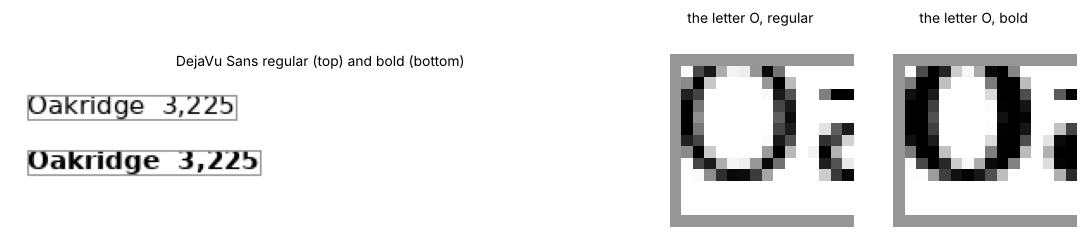

In [2]:
# Page geometry, in pixels. A US-letter page (8.5 x 11 in) at about 106 dots per inch.
PAGE_W, PAGE_H = 900, 1165
MARGIN_X, TOP_Y = 54, 64
TITLE_SIZE, HEADER_SIZE, CELL_SIZE, SMALL_SIZE = 17, 14, 15, 12   # font sizes (px)
TITLE_GAP, HEADER_H, ROW_H, PAD = 30, 32, 26, 11   # title-to-grid gap, header / row height, text padding
INSET_X, INSET_Y = 8, 3          # an OCR cell block = the cell rectangle shrunk by these insets
MINUS = "−"                 # the typographic minus sign used by printed reports

FONT_DIR = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
FONT_FILES = {"regular": "DejaVuSans.ttf", "bold": "DejaVuSans-Bold.ttf",
              "italic": "DejaVuSans-Oblique.ttf"}


@lru_cache(maxsize=None)
def get_font(style: str = "regular", size: int = CELL_SIZE) -> ImageFont.FreeTypeFont:
    """Load (and cache) one of matplotlib's bundled DejaVu fonts."""
    return ImageFont.truetype(str(FONT_DIR / FONT_FILES[style]), size)


_MEASURE = ImageDraw.Draw(Image.new("L", (1, 1)))   # scratch canvas, used only for measuring


def text_box(xy, text: str, font, anchor: str = "lt") -> tuple:
    """Pixel box (x1, y1, x2, y2) that `text` occupies when drawn at `xy` with `anchor`."""
    return tuple(int(round(v)) for v in _MEASURE.textbbox(xy, text, font=font, anchor=anchor))


# Regular vs. bold, measured and rendered side by side.
demo = Image.new("L", (360, 70), 255)
d = ImageDraw.Draw(demo)
for k, style in enumerate(["regular", "bold"]):
    xy = (10, 12 + 32 * k)
    d.text(xy, "Oakridge  3,225", font=get_font(style), fill=0, anchor="lt")
    d.rectangle(text_box(xy, "Oakridge  3,225", get_font(style)), outline=150)
    w = get_font(style).getlength("Oakridge  3,225")
    print(f"{style:>7}: text width = {w:6.1f} px, box = {text_box(xy, 'Oakridge  3,225', get_font(style))}")

fig, axes = plt.subplots(1, 3, figsize=(11, 2.6), gridspec_kw={"width_ratios": [3, 1, 1]})
axes[0].imshow(np.asarray(demo), cmap="gray", vmin=0, vmax=255)
axes[0].set_title("DejaVu Sans regular (top) and bold (bottom)", fontsize=10)
for ax, (y0, style) in zip(axes[1:], [(12, "regular"), (44, "bold")]):
    ax.imshow(np.asarray(demo)[y0 - 2:y0 + 16, 8:26], cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(f"the letter O, {style}", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Look at the zoom: a stroke of the regular "O" is one fully black pixel plus a gray fringe, about 1.5
pixels of ink in total, while a stroke of the bold "O" is two black pixels plus a fringe, about 3
pixels, and the bold text is also wider. That **stroke width** difference is all we will have to go on
in Section 8, after the page has been blurred and noised by a simulated scanner.

### 2.2 What goes into a table

Our reports contain four **families** of tables. Every table has two **key** (identifier) columns,
a *group* column such as Region and an *item* column such as Store, followed by two to four
**numeric** columns. Numbers are printed the way real reports print them:

| Kind | Example | Notes |
|---|---|---|
| `int` | `3,225` | thousands separator |
| `money` | `$172,644` | currency symbol + separator |
| `money2` | `$249.99` | prices with cents |
| `pct` | `8.5%`, `−3.2%` | one decimal, typographic minus sign |
| `signed` | `+12`, `−7`, `0` | explicit sign (net changes) |

Two structural features make the tables realistic and are deliberately annoying for a parser:

- **Merged (row-spanning) cells.** In three families, consecutive rows of the same group share one
  tall group cell, so "South" is printed once but belongs to three rows.
- **Repeated keys.** The same Store name can appear in two Regions, and in the staffing family the
  same Department appears at two Sites. Then a single condition no longer identifies a row.

In [3]:
FAMILIES = {
    "stores": dict(
        topic="Store performance by region", merged=True,
        group=("Region", ["North", "South", "East", "West", "Central", "Coastal", "Mountain", "Lakes"]),
        item=("Store", ["Oakridge", "Pinecrest", "Lakeside", "Harbor View", "Elm Street", "Riverside",
                        "Hillcrest", "Brookfield", "Maple Court", "Stonegate", "Fairview", "Westbrook",
                        "Kingsley", "Ashford", "Willow Bend", "Granite Falls"]),
        numeric=[("Units Sold", "int", (150, 6000)), ("Revenue", "money", (4000, 250000)),
                 ("Growth", "pct", (-12.0, 25.0)), ("Returns", "int", (0, 300))]),
    "staffing": dict(
        topic="Staffing by department and site", merged=False,
        group=("Department", ["Finance", "Legal", "Marketing", "Engineering", "Support", "Operations",
                              "Research", "Sales", "Human Resources", "Logistics", "Procurement",
                              "Quality"]),
        item=("Site", ["Austin", "Denver", "Boston", "Seattle", "Portland", "Atlanta", "Phoenix",
                       "Raleigh"]),
        numeric=[("Headcount", "int", (4, 140)), ("New Hires", "int", (0, 30)),
                 ("Net Change", "signed", (-15, 20)), ("Overtime Hours", "int", (80, 4200))]),
    "projects": dict(
        topic="Project portfolio status", merged=True,
        group=("Program", ["Alpha", "Beacon", "Cascade", "Delta", "Evergreen", "Falcon", "Granite",
                           "Horizon"]),
        item=("Project", ["Data Platform", "Mobile App", "Billing Revamp", "Search Upgrade",
                          "Warehouse Robots", "Customer Portal", "Fraud Model", "Payroll Sync",
                          "Edge Cache", "Chat Assistant", "Route Planner", "Sensor Network",
                          "Price Engine", "Help Center"]),
        numeric=[("Budget ($K)", "int", (40, 2500)), ("Spent ($K)", "int", (10, 2400)),
                 ("Completion", "pct", (5.0, 100.0)), ("Open Issues", "int", (0, 240))]),
    "products": dict(
        topic="Product line results", merged=True,
        group=("Category", ["Furniture", "Lighting", "Kitchen", "Garden", "Office", "Storage"]),
        item=("Product", ["Coffee Table", "Table Lamp", "Desk Chair", "Floor Lamp", "Bookshelf",
                          "Plant Pot", "Knife Set", "Filing Cabinet", "Standing Desk", "Bar Stool",
                          "Wall Clock", "Garden Hose", "Side Table", "Pendant Light", "Spice Rack",
                          "Storage Bin"]),
        numeric=[("Unit Price", "money2", (9.0, 900.0)), ("Units Sold", "int", (20, 9000)),
                 ("Return Rate", "pct", (0.2, 12.0)), ("Stock", "int", (0, 1500))]),
}
ADDITIVE = {"int", "money", "signed"}     # kinds for which "total" makes sense (not prices or %)
PERIODS = ["first half", "second half", "Q1", "Q2", "Q3", "Q4", "full year"]


def format_value(v: float, kind: str) -> str:
    """Print a number the way our reports do: separators, $, %, explicit signs, typographic minus."""
    a = abs(v)
    sign = MINUS if v < 0 else ("+" if kind == "signed" and v > 0 else "")
    body = {"int": f"{a:,.0f}", "signed": f"{a:,.0f}", "money": f"${a:,.0f}",
            "money2": f"${a:,.2f}", "pct": f"{a:.1f}%"}[kind]
    return sign + body


examples = [(3225, "int"), (172644, "money"), (249.99, "money2"), (-3.2, "pct"), (8.5, "pct"),
            (12, "signed"), (-7, "signed"), (0, "signed")]
display(pd.DataFrame([(v, k, format_value(v, k)) for v, k in examples],
                     columns=["value", "kind", "printed"]).T)

,0,1,2,3,4,5,6,7
value,3225.0,172644.0,249.99,-3.2,8.5,12.0,-7.0,0.0
kind,int,money,money2,pct,pct,signed,signed,signed
printed,"3,225","$172,644",$249.99,−3.2%,8.5%,+12,−7,0


### 2.3 The table data model

A `Table` stores *what* is printed (texts, numeric values, merged groups, bold rows) and, after the
layout step, *where* it is printed (pixel boxes). Two conventions matter later:

- `texts[r][c]` repeats a merged group name in **every** row it spans, because logically each of
  those rows does belong to that group. On the page, though, it is a single tall cell, so the OCR
  will return it as **one** block.
- `group_start[r]` is the first row of the merged block that contains row `r`, and `span(r, c)`
  turns that into the first and last row covered by the cell at `(r, c)`.

Bold rows come in two **emphasis** styles: `"full"` (every cell of the row is bold) and `"label"`
(only the key cells are bold, which is common for highlighted line items). The second style is
harder to detect, which will matter in Section 8.

In [4]:
@dataclass
class Column:
    name: str
    kind: str                    # "key" for identifier columns, otherwise a number format


@dataclass
class Table:
    number: int                  # printed number, counted across the whole document ("TABLE 3")
    page: int                    # 0-based page index
    family: str
    title: str
    columns: list                # list[Column]
    texts: list                  # texts[r][c]: printed text (merged names repeated on every row)
    values: list                 # values[r][c]: float for numeric cells, None for key cells
    group_start: list            # first row of the merged group block containing row r (column 0)
    merged: bool                 # does column 0 use row-spanning cells?
    bold_rows: set               # rows printed in bold
    emphasis: str = "full"       # "full": whole row bold, "label": only key cells bold
    sibling_of: int | None = None  # number of the earlier table this one continues (next period)
    x0: int = 0                  # top-left corner of the title, set by the layout step
    y0: int = 0
    title_box: tuple = ()
    header_boxes: list = field(default_factory=list)   # pixel box of each header block
    boxes: dict = field(default_factory=dict)          # (r, c) -> pixel box of that cell's block
    grid_x: list = field(default_factory=list)         # x of the vertical grid lines
    grid_y: list = field(default_factory=list)         # y of the horizontal grid lines

    @property
    def n_rows(self) -> int:
        return len(self.texts)

    def key_cols(self) -> list:
        return [c for c, col in enumerate(self.columns) if col.kind == "key"]

    def num_cols(self) -> list:
        return [c for c, col in enumerate(self.columns) if col.kind != "key"]

    def col_index(self, name: str) -> int:
        return [col.name for col in self.columns].index(name)

    def span(self, r: int, c: int) -> tuple:
        """(first_row, last_row) covered by the cell that contains (r, c)."""
        if not (self.merged and c == 0):
            return r, r
        r0 = self.group_start[r]
        r1 = max(i for i in range(self.n_rows) if self.group_start[i] == r0)
        return r0, r1

    def is_bold(self, r: int, c: int) -> bool:
        """Is the cell at (r, c) printed in bold? A merged cell is bold only if all its rows are."""
        r0, r1 = self.span(r, c)
        rows_bold = all(i in self.bold_rows for i in range(r0, r1 + 1))
        return rows_bold and (self.emphasis == "full" or self.columns[c].kind == "key")

Now the random table maker. Values in each numeric column are drawn **without repeats**, so
"highest", "lowest" and "which is higher" never end in a tie (ties would make gold answers
ambiguous). Key columns are built by one of two helpers: merged groups for three families, and
duplicated departments (no merging) for the staffing family.

In [5]:
def _distinct_values(rng, lo, hi, kind, n) -> list:
    """n distinct random values in [lo, hi] for a column of the given kind."""
    out = set()
    while len(out) < n:
        if kind in ("int", "money", "signed"):
            v = float(rng.integers(int(lo), int(hi) + 1))
        elif kind == "money2":
            v = round(float(rng.uniform(lo, hi)), 2)
            if rng.random() < 0.6:                    # many prices end in .99
                v = math.floor(v) + 0.99
        else:                                         # "pct": one decimal place
            v = round(float(rng.uniform(lo, hi)), 1) + 0.0
        out.add(v)
    vals = sorted(out)
    rng.shuffle(vals)
    return vals


def _merged_keys(rng, n_rows, gvocab, ivocab):
    """Group column with row-spanning cells: rows are split into consecutive groups of 1-4 rows."""
    n_groups = int(rng.integers(math.ceil(n_rows / 4), min(n_rows, len(gvocab), 5) + 1))
    while True:
        sizes = [1 + int(k) for k in rng.multinomial(n_rows - n_groups, [1 / n_groups] * n_groups)]
        if max(sizes) <= 4:
            break
    groups = [str(g) for g in rng.choice(gvocab, n_groups, replace=False)]
    group_col, group_start = [], []
    for g, s in zip(groups, sizes):
        group_start += [len(group_col)] * s
        group_col += [g] * s
    items = [str(x) for x in rng.choice(ivocab, n_rows, replace=False)]
    if n_groups >= 2 and rng.random() < 0.35:        # reuse one item name in another group
        a, b = (int(x) for x in rng.choice(n_rows, 2, replace=False))
        if group_col[a] != group_col[b]:
            items[b] = items[a]
    return group_col, items, group_start


def _duplicated_keys(rng, n_rows, gvocab, ivocab):
    """No merged cells, but one or two departments appear in two adjacent rows (different sites)."""
    n_dup = int(rng.integers(1, 3))
    depts = [str(d) for d in rng.choice(gvocab, n_rows - n_dup, replace=False)]
    depts += [str(d) for d in rng.choice(depts, n_dup, replace=False)]
    order = list(dict.fromkeys(depts))                   # first-appearance order
    depts.sort(key=order.index)                          # duplicates become adjacent rows
    items = []
    for dname in order:
        items += [str(x) for x in rng.choice(ivocab, depts.count(dname), replace=False)]
    return depts, items, list(range(n_rows))


def _bold_style(rng, n_rows):
    bold = set()
    if rng.random() < 0.6:
        bold = {int(x) for x in rng.choice(n_rows, int(rng.integers(1, 3)), replace=False)}
    return bold, ("label" if rng.random() < 0.35 else "full")


def make_table(rng, family: str, number: int, page: int, period: str) -> Table:
    """A random table of the given family. Guarantees at least one additive numeric column."""
    fam = FAMILIES[family]
    (gname, gvocab), (iname, ivocab) = fam["group"], fam["item"]
    n_rows = int(rng.integers(4, 10))
    while True:
        picked = sorted(int(i) for i in rng.choice(len(fam["numeric"]), int(rng.integers(2, 5)),
                                                   replace=False))
        numeric = [fam["numeric"][i] for i in picked]
        if any(kind in ADDITIVE for _, kind, _ in numeric):
            break
    columns = [Column(gname, "key"), Column(iname, "key")] + [Column(n, k) for n, k, _ in numeric]
    maker = _merged_keys if fam["merged"] else _duplicated_keys
    group_col, items, group_start = maker(rng, n_rows, gvocab, ivocab)
    col_vals = [_distinct_values(rng, lo, hi, kind, n_rows) for _, kind, (lo, hi) in numeric]
    texts = [[group_col[r], items[r]] + [format_value(v[r], k) for (_, k, _), v in zip(numeric, col_vals)]
             for r in range(n_rows)]
    values = [[None, None] + [float(v[r]) for v in col_vals] for r in range(n_rows)]
    bold_rows, emphasis = _bold_style(rng, n_rows)
    return Table(number, page, family, f"TABLE {number}: {fam['topic']}, {period}", columns, texts,
                 values, group_start, fam["merged"], bold_rows, emphasis)


def sibling_table(rng, base: Table, number: int, page: int, period: str) -> Table:
    """Same rows and columns as `base`, fresh numbers: the next period of the same report."""
    spec = {name: (kind, bounds) for name, kind, bounds in FAMILIES[base.family]["numeric"]}
    texts, values = [row[:] for row in base.texts], [row[:] for row in base.values]
    for c in base.num_cols():
        kind, (lo, hi) = spec[base.columns[c].name]
        for r, v in enumerate(_distinct_values(rng, lo, hi, kind, base.n_rows)):
            texts[r][c], values[r][c] = format_value(v, kind), float(v)
    bold_rows, emphasis = _bold_style(rng, base.n_rows)
    title = f"TABLE {number}: {FAMILIES[base.family]['topic']}, {period}"
    return Table(number, page, base.family, title, [Column(c.name, c.kind) for c in base.columns],
                 texts, values, list(base.group_start), base.merged, bold_rows, emphasis,
                 sibling_of=base.number)


t_demo = make_table(np.random.default_rng(9), "stores", 1, 0, "first half")
print(t_demo.title, "| merged:", t_demo.merged, "| bold rows:", t_demo.bold_rows, "| emphasis:", t_demo.emphasis)
display(pd.DataFrame(t_demo.texts, columns=[c.name for c in t_demo.columns]))

TABLE 1: Store performance by region, first half | merged: True | bold rows: {1, 5} | emphasis: full


,Region,Store,Units Sold,Revenue,Growth,Returns
0,Central,Oakridge,"5,817","$218,511",5.7%,166
1,Central,Granite Falls,"1,786","$178,219",−9.7%,23
2,North,Westbrook,"3,151","$146,901",−4.8%,182
3,North,Riverside,"1,900","$140,406",17.3%,187
4,Mountain,Fairview,"5,801","$228,552",23.6%,17
5,West,Riverside,"4,484","$219,055",−7.3%,235


### 2.4 Layout, rendering and a simulated scanner

**Layout** decides where everything goes and records every box, and **rendering** draws it. Keeping
them separate means we can re-render any page at any time from the stored layout, which we will
use in Section 8 to re-scan the same page at different qualities.

One subtle design choice: column widths are computed with the **bold** font for every cell. If we
used each cell's own font, columns containing bold text would be slightly wider and the *geometry*
would leak which rows are bold. We want boldness to be visible only in the pixels, like in real
documents.

The OCR block of a cell is the cell rectangle shrunk by a few pixels (`INSET_X`, `INSET_Y`), the
kind of output a table-aware OCR engine produces. A merged cell's block is tall: it spans all of its
rows.

In [6]:
GRID_DARK, GRID_LIGHT, HEADER_FILL = 110, 190, 228     # gray levels of grid lines and header band


def column_widths(table: Table) -> list:
    """Widths that fit each column's widest text (bold metrics everywhere: no geometric leak)."""
    hf, cf = get_font("bold", HEADER_SIZE), get_font("bold", CELL_SIZE)
    return [int(math.ceil(max([hf.getlength(col.name)] + [cf.getlength(row[c]) for row in table.texts])))
            + 2 * PAD for c, col in enumerate(table.columns)]


def place_table(table: Table, x0: int, y0: int) -> int:
    """Compute all boxes of `table` with its title's top-left corner at (x0, y0). Returns bottom y."""
    table.x0, table.y0 = x0, y0
    tb = text_box((x0, y0), table.title, get_font("bold", TITLE_SIZE), "lt")
    table.title_box = (tb[0] - 2, tb[1] - 2, tb[2] + 2, tb[3] + 2)
    widths = column_widths(table)
    table.grid_x = [x0 + int(v) for v in np.concatenate([[0], np.cumsum(widths)])]
    top = y0 + TITLE_GAP
    table.grid_y = [top, top + HEADER_H] + [top + HEADER_H + ROW_H * (r + 1) for r in range(table.n_rows)]
    gx, gy = table.grid_x, table.grid_y
    table.header_boxes = [(gx[c] + INSET_X, gy[0] + INSET_Y, gx[c + 1] - INSET_X, gy[1] - INSET_Y)
                          for c in range(len(table.columns))]
    table.boxes = {}
    for r in range(table.n_rows):
        for c in range(len(table.columns)):
            r0, r1 = table.span(r, c)
            table.boxes[(r, c)] = (gx[c] + INSET_X, gy[r0 + 1] + INSET_Y, gx[c + 1] - INSET_X,
                                   gy[r1 + 2] - INSET_Y)
    return gy[-1]


def draw_table(draw: ImageDraw.ImageDraw, table: Table) -> None:
    """Draw title, header band, grid and cell texts of an already placed table."""
    gx, gy = table.grid_x, table.grid_y
    draw.text((table.x0, table.y0), table.title, font=get_font("bold", TITLE_SIZE), fill=0, anchor="lt")
    draw.rectangle([gx[0], gy[0], gx[-1], gy[1]], fill=HEADER_FILL)
    for c, col in enumerate(table.columns):
        draw.text(((gx[c] + gx[c + 1]) / 2, (gy[0] + gy[1]) / 2), col.name,
                  font=get_font("bold", HEADER_SIZE), fill=0, anchor="mm")
    for r in range(1, table.n_rows):              # horizontal rules skip merged group cells
        x_from = gx[1] if table.span(r, 0)[0] != r else gx[0]
        draw.line([x_from, gy[r + 1], gx[-1], gy[r + 1]], fill=GRID_LIGHT, width=1)
    for c in range(1, len(table.columns)):
        draw.line([gx[c], gy[0], gx[c], gy[-1]], fill=GRID_LIGHT, width=1)
    draw.line([gx[0], gy[1], gx[-1], gy[1]], fill=GRID_DARK, width=1)
    draw.rectangle([gx[0], gy[0], gx[-1], gy[-1]], outline=GRID_DARK, width=1)
    for r in range(table.n_rows):
        for c, col in enumerate(table.columns):
            r0, r1 = table.span(r, c)
            if r0 != r:                            # a merged cell is drawn once, at its first row
                continue
            font = get_font("bold" if table.is_bold(r, c) else "regular", CELL_SIZE)
            cy = (gy[r0 + 1] + gy[r1 + 2]) / 2
            if col.kind == "key":                  # names left-aligned, numbers right-aligned
                draw.text((gx[c] + PAD, cy), table.texts[r][c], font=font, fill=0, anchor="lm")
            else:
                draw.text((gx[c + 1] - PAD, cy), table.texts[r][c], font=font, fill=0, anchor="rm")

A real scan is not a perfect rendering. Our **simulated scanner** applies three effects, controlled
by a named *profile*:

1. **Contrast loss.** Black ink becomes dark gray and white paper becomes light gray:
   $I' = I \cdot \frac{\text{paper} - \text{ink}}{255} + \text{ink}$, a linear map sending
   $0 \mapsto \text{ink}$ and $255 \mapsto \text{paper}$.
2. **Optical blur.** A Gaussian blur with standard deviation $\sigma_{\text{blur}}$ pixels, as from a
   slightly defocused lens. Blur is the enemy of stroke-width measurement: it smears thin and thick
   strokes toward each other.
3. **Sensor noise.** Independent Gaussian noise with standard deviation $\sigma_{\text{noise}}$
   gray levels added to every pixel.

In [7]:
SCAN_PROFILES = {   # blur sigma (px), noise sigma (gray levels), ink level, paper level
    "clean": (0.0, 0.0, 0, 255),
    "good": (0.5, 4.0, 25, 248),
    "fair": (0.9, 8.0, 45, 240),
    "poor": (1.3, 12.0, 70, 232),
}


def degrade(img: np.ndarray, profile: str, seed: int) -> np.ndarray:
    """Simulate a scan of a clean grayscale page: contrast loss, blur, sensor noise -> uint8."""
    blur, noise, ink, paper = SCAN_PROFILES[profile]
    a = img.astype(np.float32) * ((paper - ink) / 255.0) + ink
    if blur > 0:
        a = cv2.GaussianBlur(a, (0, 0), blur)
    if noise > 0:
        a += np.random.default_rng(seed).standard_normal(a.shape, dtype=np.float32) * noise
    return np.clip(np.rint(a), 0, 255).astype(np.uint8)

### 2.5 Whole documents

A document has one or two pages, each with one or two tables, plus the text that real reports
contain: a running header, a page footer, sometimes an introduction paragraph and notes under
tables. Three details are deliberate:

- When a document has two pages, page 2 opens with a **sibling** of a page-1 table: same rows, next
  period, new numbers. That is what makes "add this period to last period" (cross-page) questions
  natural.
- Tables are numbered across the whole document (`TABLE 1`, `TABLE 2` on page 1, `TABLE 3` on
  page 2).
- The introduction sometimes says *"Table 1 and Table 2 cover the same reporting period."* This
  sentence is a trap for a careless title detector, as you will see in Section 6.

In [8]:
@dataclass
class Document:
    doc_id: str
    n_pages: int
    tables: list                 # list[Table]
    lines: list                  # free text lines: dicts with page, text, xy, anchor, style, size, box
    profile: str                 # scan profile used for `images`
    seed: int = 0                # seed of the scanner noise
    images: list = field(default_factory=list)   # scanned grayscale pages (uint8, H x W)

    def table(self, number: int) -> Table:
        return next(t for t in self.tables if t.number == number)


def add_line(lines, page, text, xy, style="regular", size=SMALL_SIZE, anchor="lt") -> int:
    """Register a line of free text. Returns the y just below it."""
    b = text_box(xy, text, get_font(style, size), anchor)
    lines.append(dict(page=page, text=text, xy=xy, anchor=anchor, style=style, size=size,
                      box=(b[0] - 2, b[1] - 2, b[2] + 2, b[3] + 2)))
    return b[3]


def note_for(rng, t: Table) -> str:
    opts = [f"Note: figures in Table {t.number} are preliminary and may be revised.",
            "Source: internal reporting system, extracted at period end."]
    if t.bold_rows:
        opts.append("Rows printed in bold are flagged for management review.")
    if any(t.columns[c].name == "Growth" for c in t.num_cols()):
        opts.append("Growth is measured against the same period last year.")
    return str(rng.choice(opts))


def render_page(doc: Document, page: int) -> np.ndarray:
    """Draw page `page` of `doc` from its stored layout (clean, before scanning)."""
    img = Image.new("L", (PAGE_W, PAGE_H), 255)
    draw = ImageDraw.Draw(img)
    for ln in doc.lines:
        if ln["page"] == page:
            draw.text(ln["xy"], ln["text"], font=get_font(ln["style"], ln["size"]), fill=0,
                      anchor=ln["anchor"])
    for t in doc.tables:
        if t.page == page:
            draw_table(draw, t)
    return np.asarray(img)


def make_document(rng, doc_id: str, n_pages: int | None = None, profile: str | None = None) -> Document:
    n_pages = n_pages or (2 if rng.random() < 0.4 else 1)
    profile = profile or str(rng.choice(list(SCAN_PROFILES), p=[0.25, 0.35, 0.25, 0.15]))
    periods = [str(p) for p in rng.choice(PERIODS, 2, replace=False)]
    tables, number = [], 1
    for page in range(n_pages):
        fams = [str(f) for f in rng.choice(list(FAMILIES), 2 if rng.random() < 0.7 else 1, replace=False)]
        for j, fam in enumerate(fams):
            if page == 1 and j == 0:          # page 2 opens with the next period of a page-1 table
                base = tables[int(rng.integers(0, len(tables)))]
                tables.append(sibling_table(rng, base, number, page, periods[1]))
            else:
                tables.append(make_table(rng, fam, number, page, periods[min(page, 1)]))
            number += 1
    if not any(t.bold_rows for t in tables):  # every document gets at least one bold row
        t = tables[int(rng.integers(0, len(tables)))]
        t.bold_rows = {int(rng.integers(0, t.n_rows))}
    lines = []
    for page in range(n_pages):
        add_line(lines, page, f"Operations Review · Report {doc_id}", (MARGIN_X, 28))
        add_line(lines, page, f"Page {page + 1} of {n_pages}", (PAGE_W // 2, PAGE_H - 40), anchor="mt")
        y = TOP_Y
        page_tables = [t for t in tables if t.page == page]
        if page == 0 and rng.random() < 0.6:
            intro = [f"This review summarizes operating results for the {periods[0]}.",
                     "Amounts are in US dollars unless otherwise noted."]
            if len(page_tables) == 2 and rng.random() < 0.5:
                intro.append("Table 1 and Table 2 cover the same reporting period.")
            for s in intro:
                add_line(lines, page, s, (MARGIN_X, y), size=13)
                y += 21
            y += 18
        for t in page_tables:
            y = place_table(t, MARGIN_X, y) + 10
            if rng.random() < 0.5:
                add_line(lines, page, note_for(rng, t), (MARGIN_X, y), style="italic")
                y += 22
            y += 40
        assert y < PAGE_H - 60, "page overflow"
    doc = Document(doc_id, n_pages, tables, lines, profile, seed=int(rng.integers(0, 2**31 - 1)))
    doc.images = [degrade(render_page(doc, p), profile, doc.seed + p) for p in range(n_pages)]
    return doc

### 2.6 Simulated OCR and ground-truth cell annotations

Our OCR simulator plays a **perfect, table-aware OCR engine**: one block per line of free text and
one block per table cell, with normalized boxes. Notice what the output does **not** contain:
no row index, no column index, no "this is a header", no "this is bold". Recovering those is the
pipeline's job.

Separately, we keep the **cell annotations** (row, column, header, boldness, span), which play the
role of a training set's labels: we use them to create questions and to analyze the data, never as
input to the pipeline.

In [9]:
def norm_box(box) -> list:
    """Pixel box -> normalized [x1, y1, x2, y2] rounded to 4 decimals."""
    x1, y1, x2, y2 = box
    return [round(x1 / PAGE_W, 4), round(y1 / PAGE_H, 4), round(x2 / PAGE_W, 4), round(y2 / PAGE_H, 4)]


def simulate_ocr(doc: Document) -> list:
    """One block per text line and per table cell, in reading order (page, top, left)."""
    raw = [(ln["page"], ln["text"], ln["box"]) for ln in doc.lines]
    for t in doc.tables:
        raw.append((t.page, t.title, t.title_box))
        raw += [(t.page, col.name, t.header_boxes[c]) for c, col in enumerate(t.columns)]
        for (r, c), box in t.boxes.items():
            if t.span(r, c)[0] == r:               # a merged cell is ONE block
                raw.append((t.page, t.texts[r][c], box))
    raw.sort(key=lambda x: (x[0], x[2][1], x[2][0]))
    return [{"id": i, "page": p, "text": s, "bbox": norm_box(b)} for i, (p, s, b) in enumerate(raw)]


def cell_annotations(doc: Document) -> pd.DataFrame:
    """Ground-truth description of every (row, column) position of every table."""
    rows = []
    for t in doc.tables:
        for (r, c), box in t.boxes.items():
            r0, r1 = t.span(r, c)
            rows.append(dict(doc=doc.doc_id, page=t.page, table=t.number, row=r, col=c,
                             header=t.columns[c].name, text=t.texts[r][c], bold=t.is_bold(r, c),
                             row_span=r1 - r0 + 1, bbox=norm_box(box)))
    return pd.DataFrame(rows)


doc0 = make_document(np.random.default_rng(3), "R-0003", n_pages=2, profile="good")
blocks0 = simulate_ocr(doc0)
print(f"{doc0.doc_id}: {doc0.n_pages} pages, tables {[t.number for t in doc0.tables]}, "
      f"{len(blocks0)} OCR blocks, scan profile '{doc0.profile}'")
for b in blocks0[:6]:
    print(b)
ann0 = cell_annotations(doc0)
print(f"\n{len(ann0)} annotated cell positions; merged positions: {(ann0.row_span > 1).sum()}; "
      f"bold positions: {ann0.bold.sum()}")
display(ann0.head(4))

R-0003: 2 pages, tables [1, 2, 3], 130 OCR blocks, scan profile 'good'
{'id': 0, 'page': 0, 'text': 'Operations Review · Report R-0003', 'bbox': [0.0578, 0.0223, 0.2956, 0.0361]}
{'id': 1, 'page': 0, 'text': 'This review summarizes operating results for the first half.', 'bbox': [0.0567, 0.0532, 0.4844, 0.0687]}
{'id': 2, 'page': 0, 'text': 'Amounts are in US dollars unless otherwise noted.', 'bbox': [0.0578, 0.0712, 0.4267, 0.0841]}
{'id': 3, 'page': 0, 'text': 'TABLE 1: Store performance by region, first half', 'bbox': [0.0578, 0.1047, 0.5744, 0.1227]}
{'id': 4, 'page': 0, 'text': 'Region', 'bbox': [0.0689, 0.1348, 0.1644, 0.1571]}
{'id': 5, 'page': 0, 'text': 'Store', 'bbox': [0.1822, 0.1348, 0.3078, 0.1571]}

118 annotated cell positions; merged positions: 18; bold positions: 5


,doc,page,table,row,col,header,text,bold,row_span,bbox
0,R-0003,0,1,0,0,Region,East,False,1,"[0.0689, 0.1622, 0.1644, 0.1794]"
1,R-0003,0,1,0,1,Store,Brookfield,False,1,"[0.1822, 0.1622, 0.3078, 0.1794]"
2,R-0003,0,1,0,2,Units Sold,"1,581",False,1,"[0.3256, 0.1622, 0.4222, 0.1794]"
3,R-0003,0,1,0,3,Revenue,"$123,878",False,1,"[0.44, 0.1622, 0.5344, 0.1794]"


### 2.7 Looking at a document

Always look at your data. The helper below draws a page with normalized boxes on top, and we will reuse
it to show evidence later.

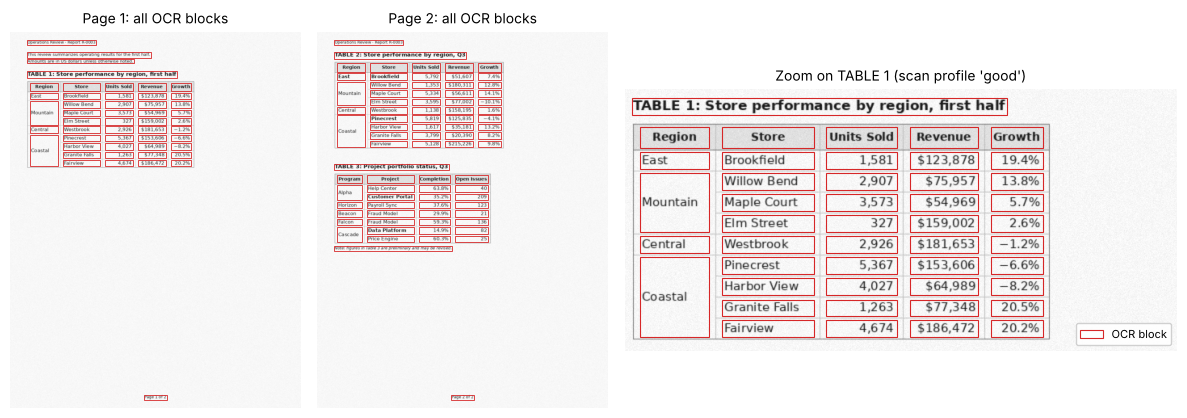

In [10]:
def show_page(img: np.ndarray, box_sets=(), ax=None, crop=None, title=None, lw=1.2):
    """Draw a grayscale page with overlaid normalized boxes.

    box_sets: iterable of (list_of_bboxes, color, label) or (list_of_bboxes, color, label, style_dict),
    where style_dict may set 'lw' and 'ls'. crop: normalized (x1, y1, x2, y2) zoom window.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4.5))
    H, W = img.shape
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    for bbs, color, label, *style in box_sets:
        st = style[0] if style else {}
        for i, (x1, y1, x2, y2) in enumerate(bbs):
            ax.add_patch(Rectangle((x1 * W, y1 * H), (x2 - x1) * W, (y2 - y1) * H, fill=False, ec=color,
                                   lw=st.get("lw", lw), ls=st.get("ls", "-"), label=label if i == 0 else None))
    if crop is not None:
        ax.set_xlim(crop[0] * W, crop[2] * W)
        ax.set_ylim(crop[3] * H, crop[1] * H)
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10)
    if any(entry[2] for entry in box_sets):
        ax.legend(loc="lower right", fontsize=8, framealpha=0.9)
    return ax


fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.9]})
for p in range(doc0.n_pages):
    show_page(doc0.images[p], [([b["bbox"] for b in blocks0 if b["page"] == p], "tab:red", None)],
              ax=axes[p], title=f"Page {p + 1}: all OCR blocks", lw=0.6)
t1 = doc0.table(1)
x1, y1, _, _ = norm_box(t1.title_box)
crop = (x1 - 0.01, y1 - 0.01, x1 + 0.75, norm_box(t1.boxes[(t1.n_rows - 1, 0)])[3] + 0.015)
show_page(doc0.images[0], [([b["bbox"] for b in blocks0 if b["page"] == 0], "tab:red", "OCR block")],
          ax=axes[2], crop=crop, title="Zoom on TABLE 1 (scan profile 'good')", lw=0.8)
plt.tight_layout()
plt.show()

Things to notice in the zoom: the tall merged group cells (their red boxes span several rows), the
right-aligned numbers, the header band, and a bold row if this table has one. Every red rectangle is
an OCR block, and the pipeline will see *only* these blocks (plus, for bold questions, the pixels).

### 2.8 Making OCR imperfect

Real OCR engines make mistakes. We model the three most common kinds, each with its own dial:

| Noise | What happens | Typical cause | What it breaks |
|---|---|---|---|
| **Jitter** | every box coordinate moves by Gaussian noise (std `jitter`, normalized units) | imprecise detection | "same top edge" row grouping, exact coordinates |
| **Splits** | a block with a space is cut into two blocks (`"Harbor View"` → `"Harbor"`, `"View"`) | word-level detection | exact text matching, header names, title detection |
| **Character errors** | one character substituted by a look-alike (`0`↔`O`, `1`↔`l`, `5`↔`S`, `,`↔`.`) or dropped | blur, low contrast | value matching, number parsing |

A single `level` knob turns all three up together, from 0 (perfect) to 5 (a bad day).

In [11]:
OCR_CONFUSIONS = {"0": "O", "O": "0", "1": "l", "l": "1", "5": "S", "S": "5", "8": "B", "B": "8",
                  "2": "Z", "6": "b", ",": ".", ".": ",", "e": "c", "a": "o", "i": "l"}


@dataclass(frozen=True)
class OCRNoise:
    jitter: float = 0.0    # std of Gaussian noise on each box coordinate (normalized units)
    p_split: float = 0.0   # chance that a block containing a space is split in two
    p_char: float = 0.0    # chance that a block gets one character error


def noise_at(level: float) -> OCRNoise:
    """The noise dial: level 0 = perfect OCR, level 5 = a bad day."""
    return OCRNoise(jitter=0.0004 * level, p_split=0.08 * level, p_char=0.025 * level)


def corrupt_text(text: str, rng) -> str:
    """One OCR-style character error: a look-alike substitution (75%) or a dropped character."""
    pos = [i for i, ch in enumerate(text) if ch in OCR_CONFUSIONS]
    if pos and rng.random() < 0.75:
        i = int(rng.choice(pos))
        return text[:i] + OCR_CONFUSIONS[text[i]] + text[i + 1:]
    if len(text) > 1:
        i = int(rng.integers(len(text)))
        return text[:i] + text[i + 1:]
    return text


def split_block(b: dict, rng) -> list:
    """Cut a block at one of its spaces. The box is cut proportionally to the character position."""
    spaces = [i for i, ch in enumerate(b["text"]) if ch == " "]
    i = int(rng.choice(spaces))
    x1, y1, x2, y2 = b["bbox"]
    xs = x1 + (x2 - x1) * (i + 0.5) / len(b["text"])
    g = 2.0 / PAGE_W                                   # a 2-pixel gap on each side of the cut
    return [dict(b, text=b["text"][:i], bbox=[x1, y1, round(xs - g, 4), y2]),
            dict(b, text=b["text"][i + 1:], bbox=[round(xs + g, 4), y1, x2, y2])]


def add_ocr_noise(blocks: list, noise: OCRNoise, seed: int) -> list:
    """Return a noisy copy of `blocks` (the input list is not modified)."""
    r = np.random.default_rng(seed)
    out = []
    for b in blocks:
        parts = split_block(b, r) if (" " in b["text"] and r.random() < noise.p_split) else [dict(b)]
        for p in parts:
            if noise.p_char > 0 and r.random() < noise.p_char:
                p["text"] = corrupt_text(p["text"], r)
            if noise.jitter > 0:
                x1, y1, x2, y2 = np.asarray(p["bbox"]) + r.normal(0.0, noise.jitter, 4)
                p["bbox"] = [round(float(v), 4) for v in (min(x1, x2), min(y1, y2), max(x1, x2), max(y1, y2))]
            out.append(p)
    for i, p in enumerate(out):
        p["id"] = i
    return out


noisy0 = add_ocr_noise(blocks0, noise_at(4), seed=1)
print(f"clean blocks: {len(blocks0)}  ->  noisy blocks (level 4): {len(noisy0)}")

# To see individual corruptions, push single blocks through the noise model ("|" marks a split).
r_demo = np.random.default_rng(5)
examples = []
for b in blocks0:
    out = add_ocr_noise([b], noise_at(4), seed=int(r_demo.integers(1_000_000)))
    if len(out) > 1 or out[0]["text"] != b["text"]:
        examples.append((b["text"], " | ".join(o["text"] for o in out)))
display(pd.DataFrame(examples[:8], columns=["clean text", "noisy text"]))

clean blocks: 130  ->  noisy blocks (level 4): 138


,clean text,noisy text
0,Units Sold,Units Sol
1,Willow Bend,Willow | Bend
2,"4,674","4,74"
3,20.2%,"20,2%"
4,"TABLE 2: Store performance by region, Q3","TABLE | 2: Store performance by region, Q3"
5,Units Sold,Units | Sold
6,Revenue,Revcnue
7,Maple Court,Mople | Court


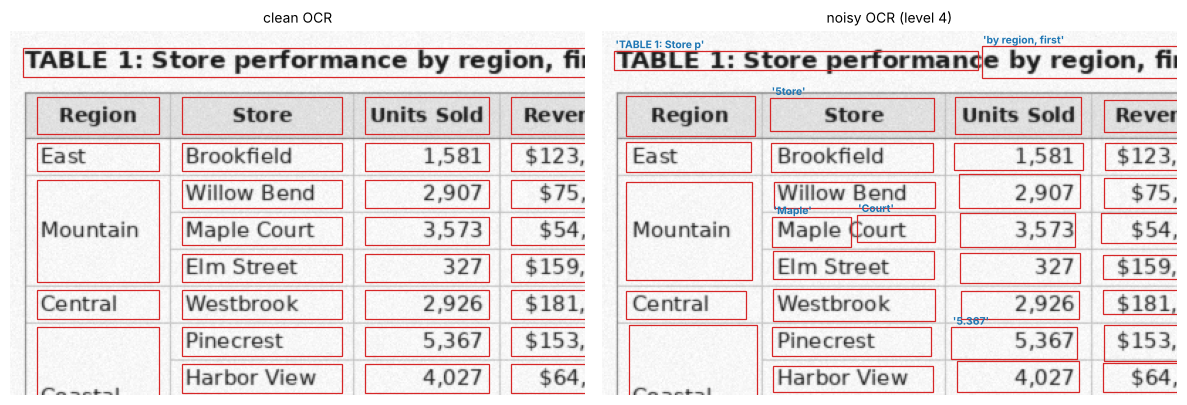

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
clean_texts = {b["text"] for b in blocks0}
for ax, (bl, name) in zip(axes, [(blocks0, "clean OCR"), (noisy0, "noisy OCR (level 4)")]):
    show_page(doc0.images[0], [([b["bbox"] for b in bl if b["page"] == 0], "tab:red", None)], ax=ax,
              crop=(crop[0], crop[1], crop[0] + 0.45, crop[1] + 0.22), title=name, lw=0.9)
    for b in bl:                       # label only the blocks whose text changed
        x1b, y1b, _, _ = b["bbox"]
        inside = crop[0] <= x1b <= crop[0] + 0.43 and crop[1] <= y1b <= crop[1] + 0.21
        if b["page"] == 0 and inside and b["text"] not in clean_texts:
            ax.text(x1b * PAGE_W + 1, y1b * PAGE_H - 2, repr(b["text"][:16]), fontsize=7.5,
                    color="tab:blue", weight="bold")
plt.tight_layout()
plt.show()

On the right, boxes no longer line up perfectly, some cells are now two blocks, and a few texts are
misspelled. None of this bothers a human reader, and the challenge is to make the pipeline equally
unbothered.

**Quick check.** Why do we jitter *normalized* coordinates with a fixed standard deviation instead
of moving every box by the same random offset?

<details><summary>Answer</summary>

A common offset for all boxes is a harmless translation: rows stay aligned with rows and columns
with columns, so it tests nothing. Independent noise per coordinate breaks the *relative*
alignments (same top edge within a row, same horizontal range within a column) that the pipeline
relies on, which is exactly what real OCR detectors do.
</details>

## 3. Questions with gold answers and gold evidence

### 3.1 Specs first, words second

A question has two layers: **what is asked** (type, table, column, which rows) and **how it is
worded**. We keep them apart. A generator first draws a **spec**, a small dictionary that pins down
the meaning together with the gold answer and gold evidence. A second step turns the spec into
English using a **template**. Two template sets exist:

- **canonical** templates, which the pipeline's parser is designed for (think: the phrasings you
  saw while developing), and
- **paraphrase** templates, never looked at while writing the parser, used as a held-out
  robustness test. Because a paraphrased question shares its spec with a canonical one, any score
  difference between the two sets is caused by the *wording alone*.

Rows are referred to by a **row descriptor** built from key columns, using as few conditions as
possible: `Store "Lakeside"` when the store name is unique in the table, and
`Store "Riverside" in Region "East"` when the same store appears in two regions. Values are always
in double quotes, which makes them easy to extract and is common practice in templated datasets.

### 3.2 What counts as evidence

Evidence should be the *smallest set of boxes a reader needs to verify the answer*. For each type:

| Type | Gold evidence |
|---|---|
| `lookup` | the condition cells of the row + the answer cell |
| `count` (by group) | the group cell(s) of the counted rows (a merged group is a single box) |
| `count` (by threshold) | the value cells that pass the threshold |
| `sum` | for every row: its condition cells + its value cell |
| `compare` | for both rows: condition cells + value cell |
| `argmax`, `argmin` | the *minimal identifying* key cells of the winning row + its value cell |
| `cross_page_sum` | for both tables (both pages): condition cells + value cell |
| `visual_bold_lookup` | condition cells of both candidate rows + the answer cell |

"Minimal identifying" means: the item cell alone if the item name is unique in the table, otherwise
item and group cells. Adding the whole row would also "prove" the answer, but it would add boxes
the gold set does not contain, and every extra box lowers evidence precision.

> **Common pitfall.** A merged group cell is *one* block on the page, so it is *one* evidence box,
> even when a question touches three rows of that group. Returning its box once per row creates
> duplicates, and since evidence boxes are matched one-to-one (Section 4.4), every duplicate
> counts as a false positive.

In [13]:
def key_conditions(t: Table, r: int) -> list:
    """Smallest list of (column name, text) pairs that singles out row r of table t."""
    item = t.texts[r][1]
    conds = [(t.columns[1].name, item)]
    if sum(row[1] == item for row in t.texts) > 1:    # repeated item name: add its group
        conds.append((t.columns[0].name, t.texts[r][0]))
    return conds


def describe(conds: list) -> str:
    """Row descriptor: 'Store "Oakridge"' or 'Store "Riverside" in Region "East"'."""
    (c1, v1), *rest = conds
    return f'{c1} "{v1}"' + "".join(f' in {c} "{v}"' for c, v in rest)


def join_descs(descs: list) -> str:
    """['A'] -> 'A', ['A', 'B'] -> 'A and B', ['A', 'B', 'C'] -> 'A, B and C'."""
    return descs[0] if len(descs) == 1 else ", ".join(descs[:-1]) + " and " + descs[-1]


def cells_to_evidence(t: Table, cells) -> list:
    """Evidence entries for (row, col) cells of t, without duplicates (a merged cell is one box)."""
    out = []
    for r, c in cells:
        e = {"page": t.page, "bbox": norm_box(t.boxes[(r, c)])}
        if e not in out:
            out.append(e)
    return out


def cond_cells(t: Table, r: int, conds: list) -> list:
    return [(r, t.col_index(name)) for name, _ in conds]


t = t_demo
print([describe(key_conditions(t, r)) for r in range(t.n_rows)])

['Store "Oakridge"', 'Store "Granite Falls"', 'Store "Westbrook"', 'Store "Riverside" in Region "North"', 'Store "Fairview"', 'Store "Riverside" in Region "West"']


### 3.3 Drawing specs

One function per type. Each picks a table and rows at random, computes the gold answer *from the
table data* (never from pixels or OCR), and collects the gold evidence cells. A few safeguards keep
the gold answers unambiguous:

- `compare` uses two rows with different item names (otherwise the answer "Riverside" would not say
  which Riverside).
- Threshold counts use a threshold strictly *between* two values of the column, so no value equals
  it and "greater than" vs. "at least" never matters.
- `sum` and `cross_page_sum` only use **additive** columns: adding two prices or two percentages is
  not meaningful.

In [14]:
def _fmt_threshold(v: float, kind: str) -> str:
    return format_value(v, "int" if kind == "signed" else kind)   # no explicit '+' in thresholds


def spec_lookup(rng, doc, t):
    r, c = int(rng.integers(t.n_rows)), int(rng.choice(t.num_cols()))
    conds = key_conditions(t, r)
    return dict(table=t.number, col=t.columns[c].name, operands=[conds], answer=t.texts[r][c],
                evidence=cells_to_evidence(t, cond_cells(t, r, conds) + [(r, c)]))


def spec_count(rng, doc, t):
    if rng.random() < 0.5:                                         # count rows of one group
        g = t.texts[int(rng.integers(t.n_rows))][0]
        rows = [r for r in range(t.n_rows) if t.texts[r][0] == g]
        return dict(table=t.number, form="group", operands=[[(t.columns[0].name, g)]],
                    answer=str(len(rows)), evidence=cells_to_evidence(t, [(r, 0) for r in rows]))
    c = int(rng.choice(t.num_cols()))                              # count rows above / below a threshold
    kind = t.columns[c].kind
    vals = sorted(t.values[r][c] for r in range(t.n_rows))
    for k in rng.permutation(t.n_rows - 1):
        thr_text = _fmt_threshold((vals[k] + vals[k + 1]) / 2, kind)
        thr = float(thr_text.replace(MINUS, "-").strip("$%").replace(",", ""))
        if vals[k] < thr < vals[k + 1]:                            # strictly between two values
            break
    else:
        return None
    op = str(rng.choice(["greater than", "less than"]))
    rows = [r for r in range(t.n_rows) if (t.values[r][c] > thr if op == "greater than" else t.values[r][c] < thr)]
    return dict(table=t.number, form="threshold", col=t.columns[c].name, op=op, thr=thr_text,
                answer=str(len(rows)), evidence=cells_to_evidence(t, [(r, c) for r in rows]))


def spec_sum(rng, doc, t):
    cols = [c for c in t.num_cols() if t.columns[c].kind in ADDITIVE]
    c = int(rng.choice(cols))
    rows = [int(r) for r in rng.choice(t.n_rows, 3 if rng.random() < 0.3 else 2, replace=False)]
    ops = [key_conditions(t, r) for r in rows]
    total = sum(t.values[r][c] for r in rows)
    cells = [x for r, cd in zip(rows, ops) for x in cond_cells(t, r, cd) + [(r, c)]]
    return dict(table=t.number, col=t.columns[c].name, operands=ops,
                answer=format_value(total, t.columns[c].kind), evidence=cells_to_evidence(t, cells))


def spec_compare(rng, doc, t):
    c = int(rng.choice(t.num_cols()))
    r1, r2 = (int(r) for r in rng.choice(t.n_rows, 2, replace=False))
    if t.texts[r1][1] == t.texts[r2][1]:
        return None
    higher = bool(rng.random() < 0.5)
    win = r1 if (t.values[r1][c] > t.values[r2][c]) == higher else r2
    ops = [key_conditions(t, r1), key_conditions(t, r2)]
    cells = cond_cells(t, r1, ops[0]) + [(r1, c)] + cond_cells(t, r2, ops[1]) + [(r2, c)]
    return dict(table=t.number, col=t.columns[c].name, operands=ops, higher=higher,
                answer=t.texts[win][1], evidence=cells_to_evidence(t, cells))


def _spec_extreme(rng, doc, t, largest: bool):
    c = int(rng.choice(t.num_cols()))
    col_vals = [t.values[r][c] for r in range(t.n_rows)]
    r = int(np.argmax(col_vals) if largest else np.argmin(col_vals))
    conds = key_conditions(t, r)                                   # minimal identifying key cells
    return dict(table=t.number, col=t.columns[c].name, answer=t.texts[r][1],
                evidence=cells_to_evidence(t, cond_cells(t, r, conds) + [(r, c)]))


def spec_cross_page_sum(rng, doc, t2):
    t1 = doc.table(t2.sibling_of)
    c = int(rng.choice([c for c in t1.num_cols() if t1.columns[c].kind in ADDITIVE]))
    r = int(rng.integers(t1.n_rows))
    conds = key_conditions(t1, r)                                  # same rows in both tables
    total = t1.values[r][c] + t2.values[r][c]
    ev = (cells_to_evidence(t1, cond_cells(t1, r, conds) + [(r, c)])
          + cells_to_evidence(t2, cond_cells(t2, r, conds) + [(r, c)]))
    return dict(table=t1.number, table2=t2.number, col=t1.columns[c].name, operands=[conds],
                answer=format_value(total, t1.columns[c].kind), evidence=ev)


def spec_visual_bold_lookup(rng, doc, t):
    rb = int(rng.choice(sorted(t.bold_rows)))
    others = [r for r in range(t.n_rows) if r not in t.bold_rows]
    ro = int(rng.choice(others))
    pair = [rb, ro] if rng.random() < 0.5 else [ro, rb]
    c = int(rng.choice(t.num_cols()))
    ops = [key_conditions(t, r) for r in pair]
    cells = cond_cells(t, pair[0], ops[0]) + cond_cells(t, pair[1], ops[1]) + [(rb, c)]
    return dict(table=t.number, col=t.columns[c].name, operands=ops, answer=t.texts[rb][c],
                evidence=cells_to_evidence(t, cells))

Each type also needs to know which tables it can use: cross-page sums need a page-2 table that
continues a page-1 table, bold questions need a table with at least one bold row, sums need an
additive column. `draw_spec` handles that and retries when a draw fails a safeguard.

In [15]:
TYPES = ["lookup", "count", "sum", "compare", "argmax", "argmin", "cross_page_sum", "visual_bold_lookup"]
SPEC_MAKERS = {"lookup": spec_lookup, "count": spec_count, "sum": spec_sum, "compare": spec_compare,
               "argmax": lambda rng, doc, t: _spec_extreme(rng, doc, t, True),
               "argmin": lambda rng, doc, t: _spec_extreme(rng, doc, t, False),
               "cross_page_sum": spec_cross_page_sum, "visual_bold_lookup": spec_visual_bold_lookup}


def eligible_tables(doc: Document, qtype: str) -> list:
    if qtype == "cross_page_sum":
        return [t for t in doc.tables if t.sibling_of is not None]
    if qtype == "visual_bold_lookup":
        return [t for t in doc.tables if t.bold_rows]
    if qtype == "sum":
        return [t for t in doc.tables if any(t.columns[c].kind in ADDITIVE for c in t.num_cols())]
    return list(doc.tables)


def draw_spec(rng, doc: Document, qtype: str, tries: int = 20):
    tables = eligible_tables(doc, qtype)
    for _ in range(tries if tables else 0):
        spec = SPEC_MAKERS[qtype](rng, doc, tables[int(rng.integers(len(tables)))])
        if spec is not None:
            spec["type"] = qtype
            return spec
    return None

### 3.4 From spec to words

Canonical templates come two per type, and paraphrase templates use different verbs, different word
order, and synonyms ("largest" for "highest", "above" for "greater than", "Add up" for "total").
Look at them side by side: a human would not even notice the difference, but a regex written for
one set will miss the other.

In [16]:
CANONICAL = {
    "lookup": ["In Table {t}, what is the {col} of {desc}?",
               "What is the {col} for {desc} in Table {t}?"],
    "count_group": ['In Table {t}, how many rows have {desc}?',
                    'How many rows in Table {t} have {desc}?'],
    "count_threshold": ["In Table {t}, how many rows have {col} {op} {thr}?",
                        "How many rows in Table {t} have {col} {op} {thr}?"],
    "sum": ["In Table {t}, what is the total {col} of {descs}?",
            "What is the sum of {col} for {descs} in Table {t}?"],
    "compare": ["In Table {t}, which has the {hl} {col}: {desc1} or {desc2}?",
                "Which has the {hl} {col} in Table {t}, {desc1} or {desc2}?"],
    "argmax": ["In Table {t}, which {icol} has the highest {col}?",
               "Which {icol} has the highest {col} in Table {t}?"],
    "argmin": ["In Table {t}, which {icol} has the lowest {col}?",
               "Which {icol} has the lowest {col} in Table {t}?"],
    "cross_page_sum": ["What is the total {col} of {desc} in Table {t} and Table {t2} combined?",
                       "Combining Table {t} and Table {t2}, what is the total {col} of {desc}?"],
    "visual_bold_lookup": ["In Table {t}, one of {desc1} and {desc2} is printed in bold. What is the {col} of the bold row?",
                           "Either {desc1} or {desc2} appears in bold in Table {t}. What is its {col}?"],
}
PARAPHRASE = {
    "lookup": ["Report the {col} listed for {desc} (Table {t}).",
               "Table {t} lists several rows. Find the {col} shown for {desc}."],
    "count_group": ["Count the entries of Table {t} that belong to {desc}.",
                    "For Table {t}, give the number of rows under {desc}."],
    "count_threshold": ["Count the rows of Table {t} whose {col} is {op2} {thr}.",
                        "For Table {t}, give the number of rows with a {col} {op2} {thr}."],
    "sum": ["Add up the {col} of {descs} in Table {t}.",
            "Table {t}: combined {col} of {descs}?"],
    "compare": ["Between {desc1} and {desc2} in Table {t}, whose {col} is {hl2}?",
                "Compare the {col} of {desc1} with that of {desc2} in Table {t}. Which one is {hl2}?"],
    "argmax": ["Name the {icol} with the largest {col} in Table {t}.",
               "Table {t}: top {icol} by {col}?"],
    "argmin": ["Name the {icol} with the smallest {col} in Table {t}.",
               "Table {t}: bottom {icol} by {col}?"],
    "cross_page_sum": ["Add the {col} of {desc} in Table {t} to its {col} in Table {t2}.",
                       "Across Table {t} and Table {t2} together, how much {col} does {desc} have?"],
    "visual_bold_lookup": ["Table {t} prints either {desc1} or {desc2} in a heavier font. Give the {col} of that row.",
                           "Of {desc1} and {desc2} in Table {t}, one is set in bold type. Report its {col}."],
}
OP_SYNONYMS = {"greater than": ["above", "over"], "less than": ["below", "under"]}


def render_question(spec: dict, doc: Document, style: str, rng) -> str:
    """Turn a spec into an English question using a random template of the given style."""
    key = spec["type"] if spec["type"] != "count" else f"count_{spec['form']}"
    tpl = str(rng.choice((CANONICAL if style == "canonical" else PARAPHRASE)[key]))
    t = doc.table(spec["table"])
    descs = [describe(conds) for conds in spec.get("operands", [])]
    fields = dict(t=spec["table"], t2=spec.get("table2"), col=spec.get("col"), icol=t.columns[1].name,
                  desc=descs[0] if descs else None, descs=join_descs(descs) if descs else None,
                  desc1=descs[0] if descs else None, desc2=descs[-1] if descs else None,
                  op=spec.get("op"), thr=spec.get("thr"),
                  op2=str(rng.choice(OP_SYNONYMS[spec["op"]])) if spec.get("op") else None,
                  hl="higher" if spec.get("higher") else "lower",
                  hl2="larger" if spec.get("higher") else "smaller")
    return tpl.format(**fields)

Finally, `make_questions` draws ten specs per document. Every feasible type is used at least once
(so rare types such as cross-page sums are not starved), the remaining slots are filled at random,
and each spec is rendered in both styles with the *same* gold answer and evidence.

In [17]:
def make_questions(doc: Document, rng, n: int = 10) -> tuple:
    """Return (canonical_questions, paraphrased_questions) for one document."""
    feasible = [q for q in TYPES if eligible_tables(doc, q)]
    order = list(rng.permutation(feasible)) + list(rng.choice(feasible, max(0, n - len(feasible))))
    canon, para = [], []
    for k, qtype in enumerate(order[:n]):
        spec = draw_spec(rng, doc, str(qtype))
        if spec is None:
            continue
        base = dict(question_id=f"{doc.doc_id}-q{k:02d}", doc_id=doc.doc_id, type=spec["type"],
                    answer=spec["answer"], evidence=spec["evidence"],
                    meta={k2: v for k2, v in spec.items() if k2 not in ("answer", "evidence", "type")})
        canon.append(dict(base, question=render_question(spec, doc, "canonical", rng)))
        para.append(dict(base, question=render_question(spec, doc, "paraphrase", rng)))
    return canon, para


q_canon0, q_para0 = make_questions(doc0, np.random.default_rng(11))
display(pd.DataFrame([dict(type=q["type"], question=q["question"], answer=q["answer"],
                           n_evidence=len(q["evidence"])) for q in q_canon0]))

,type,question,answer,n_evidence
0,compare,"Which has the lower Open Issues in Table 3, Project ""Fra...",Fraud Model,5
1,count,"In Table 3, how many rows have Completion less than 32.5%?",2,2
2,visual_bold_lookup,"In Table 3, one of Project ""Price Engine"" and Project ""D...",82,3
3,argmin,Which Store has the lowest Revenue in Table 1?,Maple Court,2
4,argmax,Which Project has the highest Completion in Table 3?,Help Center,2
5,sum,"What is the sum of Open Issues for Project ""Customer Por...",234,4
6,lookup,"In Table 3, what is the Open Issues of Project ""Fraud Mo...",21,3
7,cross_page_sum,"Combining Table 1 and Table 2, what is the total Units S...","9,802",4
8,count,"How many rows in Table 2 have Region ""Coastal""?",4,1
9,compare,"In Table 1, which has the higher Revenue: Store ""Fairvie...",Fairview,4


The same specs, worded as paraphrases:

In [18]:
for qc, qp in list(zip(q_canon0, q_para0))[:5]:
    print(f"[{qc['type']}]\n   canonical : {qc['question']}\n   paraphrase: {qp['question']}")

[compare]
   canonical : Which has the lower Open Issues in Table 3, Project "Fraud Model" in Program "Beacon" or Project "Help Center"?
   paraphrase: Compare the Open Issues of Project "Fraud Model" in Program "Beacon" with that of Project "Help Center" in Table 3. Which one is smaller?
[count]
   canonical : In Table 3, how many rows have Completion less than 32.5%?
   paraphrase: Count the rows of Table 3 whose Completion is under 32.5%.
[visual_bold_lookup]
   canonical : In Table 3, one of Project "Price Engine" and Project "Data Platform" is printed in bold. What is the Open Issues of the bold row?
   paraphrase: Table 3 prints either Project "Price Engine" or Project "Data Platform" in a heavier font. Give the Open Issues of that row.
[argmin]
   canonical : Which Store has the lowest Revenue in Table 1?
   paraphrase: Name the Store with the smallest Revenue in Table 1.
[argmax]
   canonical : Which Project has the highest Completion in Table 3?
   paraphrase: Table 3: top Pro

### 3.5 Seeing gold evidence

Let us draw the gold evidence of a few questions on the page. This is also the picture a user of a
real system would see next to the answer.

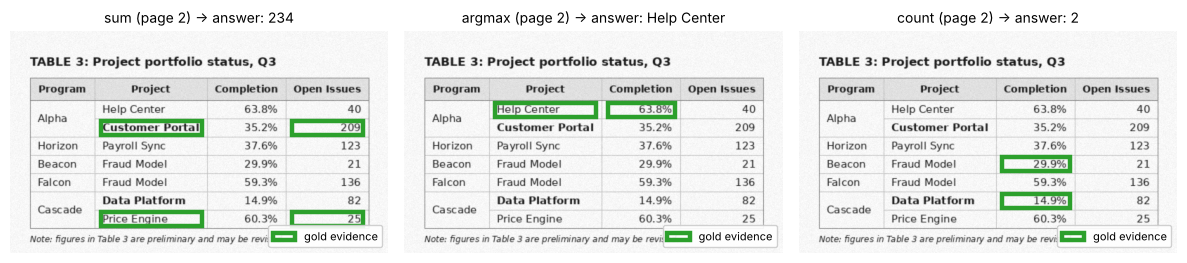

     sum: What is the sum of Open Issues for Project "Customer Portal" and Project "Price Engine" in Table 3?
  argmax: Which Project has the highest Completion in Table 3?
   count: In Table 3, how many rows have Completion less than 32.5%?


In [19]:
def show_question(doc: Document, q: dict, ax=None, pred_boxes=None, pad=0.03):
    """Zoom on the table(s) touched by question q and draw gold (and optionally predicted) boxes."""
    pages = sorted({e["page"] for e in q["evidence"]})
    p = pages[0]
    gold = [e["bbox"] for e in q["evidence"] if e["page"] == p]
    tabs = [t for t in doc.tables if t.page == p and t.number in (q["meta"]["table"], q["meta"].get("table2"))]
    t = tabs[0]
    x1, y1, _, _ = norm_box(t.title_box)
    x2, y2 = t.grid_x[-1] / PAGE_W, t.grid_y[-1] / PAGE_H        # bottom-right corner of the grid
    crop = (max(x1 - pad, 0), max(y1 - pad, 0), min(x2 + pad, 1), min(y2 + pad, 1))
    sets = [(gold, "tab:green", "gold evidence", {"lw": 3.2})]
    if pred_boxes is not None:                    # thin dashed red on top of thick green: both stay visible
        sets.append(([e["bbox"] for e in pred_boxes if e["page"] == p], "tab:red", "prediction", {"lw": 1.3, "ls": "--"}))
    show_page(doc.images[p], sets, ax=ax, crop=crop, lw=1.6,
              title=f"{q['type']} (page {p + 1}) → answer: {q['answer']}")
    return ax


picks = [next(q for q in q_canon0 if q["type"] == ty) for ty in ["sum", "argmax", "count"]]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, q in zip(axes, picks):
    show_question(doc0, q, ax=ax)
plt.tight_layout()
plt.show()
for q in picks:
    print(f"{q['type']:>8}: {q['question']}")

### 3.6 The datasets

We now manufacture three question sets. Development documents are what you "look at" while
building the pipeline, and test documents are generated with different seeds and are only used for the
final evaluation in Section 10.

| Set | Documents | Wording | Used for |
|---|---|---|---|
| `DEV` | 30 | canonical | developing and debugging the pipeline, training the bold classifier |
| `TEST` | 60 | canonical | final evaluation |
| `TEST_PARA` | same 60 | paraphrased | robustness to wording |

> **Common pitfall.** Tuning thresholds while looking at test scores quietly turns the test set into a
> second development set, and the final number becomes optimistic. Here every threshold is chosen
> on `DEV`.

In [20]:
def make_corpus(seed: int, n_docs: int, prefix: str) -> tuple:
    """n_docs documents and their (canonical, paraphrased) questions, reproducible from `seed`."""
    r = np.random.default_rng(seed)
    docs, canon, para = {}, [], []
    for i in range(n_docs):
        doc = make_document(r, f"{prefix}{i:03d}")
        c, p = make_questions(doc, r)
        docs[doc.doc_id], canon, para = doc, canon + c, para + p
    return docs, canon, para


t0 = time.time()
DEV_DOCS, DEV, _ = make_corpus(1001, 30, "D")
TEST_DOCS, TEST, TEST_PARA = make_corpus(2002, 60, "T")
ALL_DOCS = {**DEV_DOCS, **TEST_DOCS}
print(f"generated {len(ALL_DOCS)} documents in {time.time() - t0:.1f} s")
print(f"DEV: {len(DEV)} questions | TEST: {len(TEST)} | TEST_PARA: {len(TEST_PARA)}")
print("pages per test document:", dict(Counter(d.n_pages for d in TEST_DOCS.values())))
display(pd.DataFrame({"DEV": Counter(q["type"] for q in DEV), "TEST": Counter(q["type"] for q in TEST)})
        .loc[TYPES])

generated 90 documents in 3.7 s
DEV: 300 questions | TEST: 600 | TEST_PARA: 600
pages per test document: {1: 36, 2: 24}


,DEV,TEST
lookup,38,77
count,40,86
sum,39,83
compare,42,83
argmax,39,89
argmin,45,81
cross_page_sum,11,27
visual_bold_lookup,46,74


## 4. Scoring from scratch: Levenshtein, ANLS, IoU, Evidence-F1

Before building a system, decide how it will be judged: the metric defines what "better" means,
and it will shape many design choices (for example, whether to abstain, or how many evidence
boxes to return).

### 4.1 Levenshtein distance

The **Levenshtein (edit) distance** $\operatorname{lev}(a, b)$ between strings $a$ and $b$ is the
minimum number of single-character **insertions**, **deletions** and **substitutions** that turn
$a$ into $b$. It is computed by dynamic programming. Let $D[i][j]$ be the distance between the
first $i$ characters of $a$ and the first $j$ characters of $b$. Then

$$
D[i][0] = i, \qquad D[0][j] = j, \qquad
D[i][j] = \min\big(D[i-1][j] + 1,\; D[i][j-1] + 1,\; D[i-1][j-1] + [a_i \ne b_j]\big),
$$

where $[a_i \ne b_j]$ is 1 if the characters differ and 0 otherwise. The three options are: delete
$a_i$, insert $b_j$, or match/substitute $a_i$ with $b_j$. The answer is $D[|a|][|b|]$, computed in
$O(|a|\,|b|)$ time.

Worked example: turn the gold text `1,250` into the OCR reading `1.25`. Intuitively one
substitution (`,` → `.`) and one deletion (the final `0`) suffice, so the distance should be 2. The
full table confirms it (bottom-right entry):

In [21]:
def levenshtein(a: str, b: str) -> int:
    """Minimum number of single-character insertions, deletions and substitutions turning a into b."""
    prev = list(range(len(b) + 1))                 # row i-1 of the DP table
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1,            # delete ca
                           cur[j - 1] + 1,         # insert cb
                           prev[j - 1] + (ca != cb)))   # match or substitute
        prev = cur
    return prev[-1]


def lev_table(a: str, b: str) -> pd.DataFrame:
    """The full DP table D, for teaching purposes."""
    D = np.zeros((len(a) + 1, len(b) + 1), dtype=int)
    D[:, 0], D[0, :] = np.arange(len(a) + 1), np.arange(len(b) + 1)
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = min(D[i - 1, j] + 1, D[i, j - 1] + 1, D[i - 1, j - 1] + (a[i - 1] != b[j - 1]))
    return pd.DataFrame(D, index=["ε"] + list(a), columns=["ε"] + list(b))


display(lev_table("1,250", "1.25"))
print("levenshtein('1,250', '1.25') =", levenshtein("1,250", "1.25"))

,ε,1,.,2,5
ε,0,1,2,3,4
1,1,0,1,2,3
",",2,1,1,2,3
2,3,2,2,1,2
5,4,3,3,2,1
0,5,4,4,3,2


levenshtein('1,250', '1.25') = 2


Read the table row by row: row `ε` and column `ε` stand for the empty prefix. Entry (`,`, `.`) is 1:
`1,` vs `1.` needs one substitution. The last row grows by one in its final column because the
extra `0` must be deleted.

Is the dynamic program right? A good habit is to test a clever implementation against a *slow but
obviously correct* one. The recursive definition below follows the three edit options literally
(memoized with `lru_cache` so it finishes), and the two must agree on random strings.

In [22]:
@lru_cache(maxsize=None)
def lev_recursive(a: str, b: str) -> int:
    """Edit distance straight from the definition (fine for short strings thanks to the cache)."""
    if not a or not b:
        return len(a) + len(b)
    return min(lev_recursive(a[1:], b) + 1,                      # delete a[0]
               lev_recursive(a, b[1:]) + 1,                      # insert b[0]
               lev_recursive(a[1:], b[1:]) + (a[0] != b[0]))     # match or substitute


r_chk = np.random.default_rng(0)
words = ["".join(r_chk.choice(list("ab1,"), int(r_chk.integers(0, 8)))) for _ in range(400)]
agree = all(levenshtein(x, y) == lev_recursive(x, y) for x, y in zip(words[::2], words[1::2]))
print("DP == recursive definition on 200 random pairs:", agree)

DP == recursive definition on 200 random pairs: True


### 4.2 From distance to ANLS

A raw distance is not comparable across lengths (one typo in a 3-letter word is worse than one in
a 30-letter title), so we normalize by the longer length. For a prediction $p$ and a gold answer
$g$ (both lower-cased, with whitespace collapsed):

$$
\operatorname{NL}(p, g) = \frac{\operatorname{lev}(p, g)}{\max(|p|, |g|)} \in [0, 1], \qquad
s(p, g) = \begin{cases} 1 - \operatorname{NL}(p, g) & \text{if } \operatorname{NL}(p, g) < \tau \\
0 & \text{otherwise.} \end{cases}
$$

A question may accept several gold answers $G$ (for example `"8.5%"` and `"8.5 %"`), and the question
score is $\max_{g \in G} s(p, g)$, and **ANLS** is the average of question scores over the dataset.

**Why the threshold $\tau = 0.5$?** Without it, *almost every* answer gets partial credit:
`"Coastal"` for a gold `"Central"` needs 4 edits in 7 characters ($\operatorname{NL} \approx 0.57$)
and would still earn $0.43$ for a completely wrong region, but with the threshold it earns 0. The
threshold says: a prediction that differs from the gold answer in fewer than half of its characters
is probably *the right answer with recognition errors* and deserves partial credit. Beyond that, it is
probably a *different answer* and gets nothing. The value 0.5 is a convention, chosen so that one
or two typos in a typical answer still earn most of the credit. It is a coarse filter, though:
`"South"` for a gold `"North"` needs only 2 edits in 5 characters ($\operatorname{NL} = 0.4$), so that
wrong region keeps 0.6 even with $\tau = 0.5$ (both cases are in the table below).

> **Common pitfall.** ANLS is generous to near-misses, and for numbers that is a weakness: `"1,350"`
> for a gold `"1,250"` is a *wrong* number but scores $1 - 1/5 = 0.8$. Conversely, `"1250"` vs.
> `"1,250"` is the *right* number but scores only 0.8 too. So always print numbers exactly in the
> document's format, because the metric cannot tell formatting slips from arithmetic slips.

In [23]:
def normalize_answer(s) -> str:
    """Lower-case, strip and collapse runs of whitespace (case and extra spaces are ignored,
    a single space still counts as a character)."""
    return " ".join(str(s).lower().split())


def nls(pred: str, gold: str) -> float:
    """Normalized Levenshtein similarity 1 - lev / max length (1.0 for two empty strings)."""
    p, g = normalize_answer(pred), normalize_answer(gold)
    if not p and not g:
        return 1.0
    return 1.0 - levenshtein(p, g) / max(len(p), len(g))


def anls(pred: str, golds, tau: float = 0.5) -> float:
    """ANLS score of one prediction against one gold answer or a list of acceptable answers."""
    golds = [golds] if isinstance(golds, str) else list(golds)
    best = 0.0
    for g in golds:
        s = nls(pred, g)
        if 1.0 - s < tau:                      # normalized distance below the threshold
            best = max(best, s)
    return best


pairs = [("Oakridge", "oakridge"), ("Oakridge", "0akridge"), ("Harbor View", "Harbor"),
         ("North", "South"), ("Central", "Coastal"), ("1,250", "1,350"), ("1,250", "1250"),
         ("$172,644", "172644"), ("Lakeside", "Riverside"), ("8.5%", "8.5 %")]
display(pd.DataFrame([dict(gold=g, pred=p, lev=levenshtein(normalize_answer(p), normalize_answer(g)),
                           NLS=round(nls(p, g), 3), ANLS=round(anls(p, g), 3)) for g, p in pairs]))

,gold,pred,lev,NLS,ANLS
0,Oakridge,oakridge,0,1.000,1.000
1,Oakridge,0akridge,1,0.875,0.875
2,Harbor View,Harbor,5,0.545,0.545
3,North,South,2,0.600,0.600
4,Central,Coastal,4,0.429,0.000
5,"1,250","1,350",1,0.800,0.800
6,"1,250",1250,1,0.800,0.800
7,"$172,644",172644,2,0.750,0.750
8,Lakeside,Riverside,4,0.556,0.556
9,8.5%,8.5 %,1,0.800,0.800


Some observations: case does not matter (`oakridge`), one OCR substitution costs only $1/8$, and
`"8.5 %"` scores $0.8$ because a space is a character too. `"Coastal"` is the only example that the
threshold cuts to 0. Worst of all, `"Riverside"` for a gold `"Lakeside"` (two *different* stores)
still earns 0.556, because the names share the ending "side": the threshold removes credit only
when *at least half* of the characters differ ($\operatorname{NL} \ge 0.5$). Let us plot the score
as a function of the normalized distance, with the examples above placed on the curve.

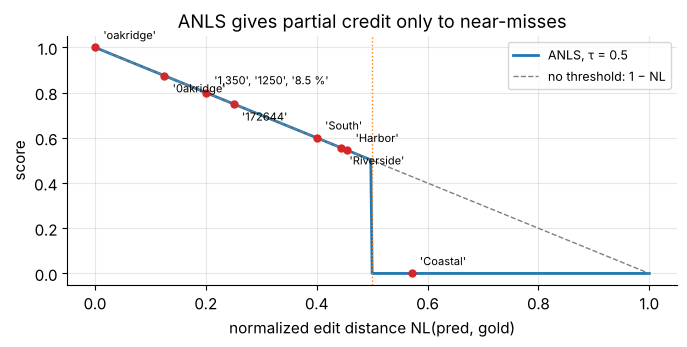

In [24]:
fig, ax = plt.subplots(figsize=(7, 3.6))
nl_grid = np.linspace(0, 1, 401)
ax.plot(nl_grid, np.where(nl_grid < 0.5, 1 - nl_grid, 0.0), color="tab:blue", lw=2, label="ANLS, τ = 0.5")
ax.plot(nl_grid, 1 - nl_grid, color="gray", ls="--", lw=1, label="no threshold: 1 − NL")
groups = defaultdict(list)                       # examples with the same distance share one label
for g, p in pairs:
    groups[round(1 - nls(p, g), 3)].append(f"'{p}'")
for k, (d, labels) in enumerate(sorted(groups.items())):
    score = 1 - d if d < 0.5 else 0.0
    ax.plot(d, score, "o", color="tab:red", ms=5)
    ax.annotate(", ".join(labels), (d, score), textcoords="offset points", fontsize=8,
                xytext=(6, 6) if k % 2 == 0 or score == 0 else (6, -12))
ax.axvline(0.5, color="tab:orange", lw=1, ls=":")
ax.set_xlabel("normalized edit distance NL(pred, gold)")
ax.set_ylabel("score")
ax.set_title("ANLS gives partial credit only to near-misses")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

You will implement ANLS yourself in Exercise 2, right after the IoU exercise below.

### 4.3 Intersection over union

Evidence is judged by box overlap. For two boxes $A$ and $B$ the **intersection over union** is

$$
\operatorname{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|} \in [0, 1],
$$

where $|\cdot|$ is area. For axis-aligned boxes the intersection is again a box with
$x$-extent $\max(0, \min(x_2^A, x_2^B) - \max(x_1^A, x_1^B))$ and similarly for $y$.

Worked example: $A = [0, 0, 4, 2]$ and $B = [2, 1, 6, 3]$. The intersection is $[2, 1, 4, 2]$ with
area $2 \cdot 1 = 2$, the areas are $|A| = 8$ and $|B| = 8$, the union is $8 + 8 - 2 = 14$, and so
$\operatorname{IoU} = 2/14 \approx 0.143$.

**How much error does $\operatorname{IoU} \ge 0.5$ tolerate?** Slide a copy of a $w \times h$ box
sideways by $d \le w$. The intersection is $(w - d)h$ and the union is $(w + d)h$, so

$$
\operatorname{IoU} = \frac{w - d}{w + d} \ge \frac{1}{2} \iff d \le \frac{w}{3}.
$$

A box may slide by a third of its width (or, vertically, a third of its height). Our cell blocks are
roughly $0.1$ wide but only about $0.017$ tall in normalized units, so vertical errors are the dangerous ones:
predicting the box of the row *above* gives IoU 0. And a box that is too big fails as well: the
box around a cell's whole row contains the cell, but their IoU is only about $0.18$.

IoU of the worked example: 0.1429


max |ours - torchvision.ops.box_iou| over 1,600 random pairs: 0.00e+00
cell vs. a box around its whole row: 0.177


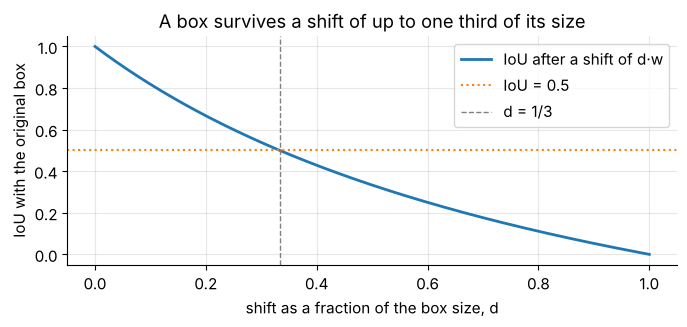

In [25]:
def box_area(b) -> float:
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])


def iou(a, b) -> float:
    """Intersection over union of two [x1, y1, x2, y2] boxes (0.0 if the union is empty)."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = box_area(a) + box_area(b) - inter
    return inter / union if union > 0 else 0.0


print("IoU of the worked example:", round(iou([0, 0, 4, 2], [2, 1, 6, 3]), 4))
try:                                                        # cross-check against a library implementation
    import torch
    from torchvision.ops import box_iou
    xy = np.sort(r_chk.uniform(0, 1, (2, 40, 2, 2)), axis=-1)          # sorted pairs: x1 < x2, y1 < y2
    A_, B_ = (np.stack([z[:, 0, 0], z[:, 1, 0], z[:, 0, 1], z[:, 1, 1]], axis=1) for z in xy)
    ours = np.array([[iou(a_, b_) for b_ in B_] for a_ in A_])
    lib = box_iou(torch.tensor(A_), torch.tensor(B_)).numpy()
    print(f"max |ours - torchvision.ops.box_iou| over 1,600 random pairs: {np.abs(ours - lib).max():.2e}")
except ImportError:
    print("torchvision not available: skipping the library cross-check")
cell = norm_box(t1.boxes[(0, 2)])
row = [cell[0] - 0.25, cell[1], cell[2] + 0.2, cell[3]]
print("cell vs. a box around its whole row:", round(iou(cell, row), 3))

fig, ax = plt.subplots(figsize=(7, 3.4))
d = np.linspace(0, 1, 201)
ax.plot(d, (1 - d) / (1 + d), lw=2, label="IoU after a shift of d·w")
ax.axhline(0.5, color="tab:orange", ls=":", label="IoU = 0.5")
ax.axvline(1 / 3, color="gray", ls="--", lw=1, label="d = 1/3")
ax.set_xlabel("shift as a fraction of the box size, d")
ax.set_ylabel("IoU with the original box")
ax.set_title("A box survives a shift of up to one third of its size")
ax.legend()
plt.tight_layout()
plt.show()

In [26]:
# ✏️ Exercise 1: IoU of two boxes
def my_iou(a, b) -> float:
    """IoU of two boxes [x1, y1, x2, y2]. Return 0.0 when the union has zero area."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert abs(my_iou([0, 0, 2, 2], [1, 1, 3, 3]) - 1 / 7) < 1e-9, "two overlapping squares: expected 1/7"
    assert abs(my_iou([0, 0, 4, 2], [2, 1, 6, 3]) - 1 / 7) < 1e-9, "worked example: expected 2/14"
    assert my_iou([0, 0, 1, 1], [1, 0, 2, 1]) == 0.0, "boxes that only touch have IoU 0"
    assert my_iou([0, 0, 1, 1], [2, 2, 3, 3]) == 0.0, "disjoint boxes have IoU 0"
    assert abs(my_iou([0.1, 0.2, 0.5, 0.3], [0.1, 0.2, 0.5, 0.3]) - 1) < 1e-9, "identical boxes: 1"
    assert abs(my_iou([0, 0, 4, 1], [1, 0, 2, 1]) - 0.25) < 1e-9, "a box inside another: area ratio"
    assert my_iou([0, 0, 0, 0], [0, 0, 0, 0]) == 0.0, "degenerate (zero-area) boxes: return 0.0"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_iou(a, b) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0
```
The `max(0, ...)` clamps make non-overlapping boxes produce an empty intersection instead of a
negative "area", and the final guard handles two zero-area boxes.
</details>

In [27]:
# ✏️ Exercise 2: ANLS with several acceptable answers
def my_anls(pred: str, golds: list, tau: float = 0.5) -> float:
    """ANLS of `pred` against a list of acceptable gold answers.

    Compare lower-cased strings with whitespace collapsed. You may call `levenshtein`.
    A gold answer contributes 1 - NL if NL < tau, else 0. Return the best over all golds.
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert my_anls("OAKRIDGE", ["Oakridge"]) == 1.0, "case must not matter"
    assert my_anls("  Harbor   View ", ["harbor view"]) == 1.0, "extra spaces must not matter"
    assert abs(my_anls("0akridge", ["Oakridge"]) - 0.875) < 1e-9, "one substitution in 8 chars"
    assert my_anls("ab", ["ac"]) == 0.0, "NL = 0.5 exactly is NOT below the threshold"
    assert my_anls("1,250", ["7,986"]) == 0.0, "a different number scores 0"
    assert abs(my_anls("8.5 %", ["8.5%", "8.5 %"]) - 1.0) < 1e-9, "take the best gold answer"
    assert my_anls("", ["North"]) == 0.0, "an empty answer scores 0"
    assert abs(my_anls("Sout", ["South", "S"]) - 0.8) < 1e-9, "best over golds: 0.8"


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_anls(pred, golds, tau=0.5):
    p = " ".join(pred.lower().split())
    best = 0.0
    for g in golds:
        g = " ".join(g.lower().split())
        if not p and not g:
            return 1.0
        nl = levenshtein(p, g) / max(len(p), len(g))
        if nl < tau:
            best = max(best, 1.0 - nl)
    return best
```
The strict inequality `nl < tau` is what makes `"ab"` vs. `"ac"` (NL exactly 0.5) score 0.
</details>

### 4.4 Matching evidence boxes one-to-one

A predicted box is a **true positive** if it is on the same page as a gold box and their
$\operatorname{IoU} \ge 0.5$, with one extra rule: the matching is **one-to-one**, so each gold box can
be claimed by at most one predicted box. Without that rule, a system could repeat one correct box
ten times and collect ten true positives for a single gold box: the copies would cost no precision,
and recall ($\text{TP}$ divided by the number of gold boxes, defined in Section 4.5) would be
inflated, even above 1. With the rule, the nine copies are false positives.

Finding the largest one-to-one matching is a classic **bipartite matching** problem. Two
algorithms:

- **Greedy.** Sort all (prediction, gold) pairs with IoU ≥ 0.5 by IoU, take a pair whenever both
  boxes are still free. Simple and fast, but it can be fooled: grabbing the best-looking pair first
  may block two other pairs.
- **Hungarian algorithm** (`scipy.optimize.linear_sum_assignment`). Solves the assignment problem
  exactly: given a cost matrix, it finds the one-to-one assignment with the lowest total cost in
  $O(n^3)$. Give every valid pair a cost of $-(1 + 0.001\cdot\text{IoU})$ and every invalid pair cost
  $0$: minimizing the total cost then maximizes the *number* of matches first and, among those, the
  total IoU.

Here is a small case where greedy loses a match:

In [28]:
def match_boxes(pred: list, gold: list, thr: float = 0.5, method: str = "hungarian") -> list:
    """One-to-one matching of evidence entries ({'page', 'bbox'}). Returns matched (i_pred, j_gold) pairs."""
    if not pred or not gold:
        return []
    M = np.array([[iou(p["bbox"], g["bbox"]) if p["page"] == g["page"] else 0.0 for g in gold]
                  for p in pred])
    valid = M >= thr
    if method == "greedy":
        cand = sorted(((M[i, j], i, j) for i, j in zip(*np.nonzero(valid))), reverse=True)
        used_p, used_g, out = set(), set(), []
        for _, i, j in cand:
            if i not in used_p and j not in used_g:
                used_p.add(i); used_g.add(j); out.append((int(i), int(j)))
        return out
    rows, cols = linear_sum_assignment(np.where(valid, -(1.0 + 1e-3 * M), 0.0))
    return [(int(i), int(j)) for i, j in zip(rows, cols) if valid[i, j]]


P = [{"page": 0, "bbox": [0.00, 0.0, 0.30, 0.1]}, {"page": 0, "bbox": [0.00, 0.0, 0.18, 0.1]}]
G = [{"page": 0, "bbox": [0.02, 0.0, 0.30, 0.1]}, {"page": 0, "bbox": [0.08, 0.0, 0.36, 0.1]}]
M_demo = np.array([[iou(p["bbox"], g["bbox"]) for g in G] for p in P])
print("IoU matrix (rows = predictions, columns = gold):\n", M_demo.round(3))
print("greedy   :", match_boxes(P, G, method="greedy"))
print("hungarian:", match_boxes(P, G, method="hungarian"))

IoU matrix (rows = predictions, columns = gold):
 [[0.933 0.611]
 [0.533 0.278]]
greedy   : [(0, 0)]
hungarian: [(0, 1), (1, 0)]


Greedy pairs prediction 0 with gold 0 (the single best IoU, 0.933) and then prediction 1 has no
free partner: its only valid partner is gold 0. The Hungarian algorithm instead pairs prediction 0
with gold 1 (IoU 0.611) and prediction 1 with gold 0 (IoU 0.533): two matches instead of one.

How often does this happen? Let us generate random small instances with heavily overlapping boxes
and compare both algorithms with a brute-force search over all one-to-one assignments.

In [29]:
def brute_force_matches(valid: np.ndarray) -> int:
    """Largest number of valid one-to-one pairs, by trying every assignment (tiny inputs only)."""
    n_p, n_g = valid.shape
    best = 0
    for choice in itertools.product(range(-1, n_g), repeat=n_p):      # -1 = prediction unmatched
        used = [j for j in choice if j >= 0]
        if len(used) == len(set(used)):
            best = max(best, sum(valid[i, j] for i, j in enumerate(choice) if j >= 0))
    return int(best)


r_m = np.random.default_rng(1)
stats = Counter()
for _ in range(300):
    def rand_boxes(n):
        x1 = r_m.uniform(0, 0.3, n)
        return [{"page": 0, "bbox": [a, 0.0, a + w, 0.1]} for a, w in zip(x1, r_m.uniform(0.1, 0.3, n))]
    P_, G_ = rand_boxes(int(r_m.integers(1, 5))), rand_boxes(int(r_m.integers(1, 4)))
    valid = np.array([[iou(p["bbox"], g["bbox"]) >= 0.5 for g in G_] for p in P_])
    best = brute_force_matches(valid)
    stats["hungarian == brute force"] += len(match_boxes(P_, G_)) == best
    stats["greedy == brute force"] += len(match_boxes(P_, G_, method="greedy")) == best
print({k: f"{v}/300" for k, v in stats.items()})

{'hungarian == brute force': '300/300', 'greedy == brute force': '290/300'}


On these deliberately crowded instances the Hungarian algorithm found the optimum all 300 times,
greedy in 290 of them: it falls short only occasionally, which is why greedy matching is popular
in practice, but "occasionally" is not "never".

> **Olympiad tip.** In our data the gold boxes of one question never overlap. Then greedy is
> always optimal (up to exact ties at 0.5). Proof sketch: if $\operatorname{IoU}(P, G) \ge 1/2$
> then $|P \cap G| \ge \tfrac12 |P \cup G| \ge \tfrac12 |P|$, so $G$ covers at least half of $P$. Two
> *disjoint* gold boxes cannot both cover more than half of $P$, so each prediction has at most one
> valid partner, the valid pairs never compete, and every greedy choice is forced. The fancy
> algorithm is insurance for overlapping *gold* boxes (nested regions, a merged cell annotated
> together with its parts). Duplicated predictions alone cannot fool greedy: each copy still has at
> most one valid partner.

### 4.5 Evidence precision, recall, F1 and the final score

With $\text{TP}$ matched pairs, $|\hat E|$ predicted boxes and $|E|$ gold boxes:

$$
P = \frac{\text{TP}}{|\hat E|}, \qquad R = \frac{\text{TP}}{|E|}, \qquad
F_1 = \frac{2PR}{P + R}, \qquad
\text{score} = 0.85 \cdot \text{ANLS} + 0.15 \cdot F_1 .
$$

Precision punishes extra boxes, recall punishes missing boxes, and $F_1$ (their harmonic mean) is
high only when both are. Edge cases: if neither side has boxes we define $F_1 = 1$ (nothing to find,
nothing claimed), and if exactly one side is empty, $F_1 = 0$.

In [30]:
def evidence_prf(pred: list, gold: list, method: str = "hungarian") -> tuple:
    """(precision, recall, F1) of predicted evidence against gold evidence."""
    if not pred and not gold:
        return 1.0, 1.0, 1.0
    if not pred or not gold:
        return 0.0, 0.0, 0.0
    tp = len(match_boxes(pred, gold, method=method))
    p, r = tp / len(pred), tp / len(gold)
    return p, r, (2 * p * r / (p + r) if tp else 0.0)


def score_one(pred: dict, gold: dict) -> dict:
    """All metrics of one prediction {'answer', 'evidence'} against one gold question."""
    a = anls(pred.get("answer", ""), gold["answer"])
    p, r, f1 = evidence_prf(pred.get("evidence", []), gold["evidence"])
    return dict(anls=a, ev_p=p, ev_r=r, ev_f1=f1, score=0.85 * a + 0.15 * f1)


def score_predictions(preds: dict, golds: list) -> pd.DataFrame:
    """One row of metrics per gold question. A missing prediction counts as an empty answer."""
    rows = []
    for g in golds:
        m = score_one(preds.get(g["question_id"], {}), g)
        rows.append(dict(question_id=g["question_id"], type=g["type"], **m))
    return pd.DataFrame(rows)

To feel what the evidence term rewards, score some **evidence strategies** on `DEV` while always
giving the *correct* answer. Only the boxes change:

- `exact`: the gold boxes.
- `answer cell only`: just the last gold box (usually the value cell).
- `whole rows`: every cell of every row that contains a gold box.
- `whole table`: every cell of the table(s) involved.
- `shifted down 40%`: gold boxes moved down by 40% of their height.
- `no evidence`.

In [31]:
def locate_cell(doc: Document, e: dict):
    """(table, row, col) of the cell whose box equals evidence entry e."""
    for t in doc.tables:
        if t.page == e["page"]:
            for (r, c), b in t.boxes.items():
                if norm_box(b) == e["bbox"]:
                    return t, r, c
    raise KeyError(e)


def strategy_evidence(doc: Document, q: dict, name: str) -> list:
    if name == "exact":
        return q["evidence"]
    if name == "answer cell only":
        return q["evidence"][-1:]
    if name == "no evidence":
        return []
    if name == "shifted down 40%":
        return [dict(e, bbox=[e["bbox"][0], e["bbox"][1] + 0.4 * (e["bbox"][3] - e["bbox"][1]), e["bbox"][2],
                              e["bbox"][3] + 0.4 * (e["bbox"][3] - e["bbox"][1])]) for e in q["evidence"]]
    cells = [locate_cell(doc, e) for e in q["evidence"]]
    out = []
    for t, r, _ in cells:
        rows = [r] if name == "whole rows" else range(t.n_rows)
        for rr in rows:
            out += cells_to_evidence(t, [(rr, c) for c in range(len(t.columns))])
    return [e for k, e in enumerate(out) if e not in out[:k]]


rows = []
for name in ["exact", "answer cell only", "whole rows", "whole table", "shifted down 40%", "no evidence"]:
    preds = {q["question_id"]: dict(answer=q["answer"], evidence=strategy_evidence(DEV_DOCS[q["doc_id"]], q, name))
             for q in DEV}
    s = score_predictions(preds, DEV)
    rows.append(dict(strategy=name, ev_precision=s.ev_p.mean(), ev_recall=s.ev_r.mean(),
                     ev_f1=s.ev_f1.mean(), final_score=s.score.mean()))
display(pd.DataFrame(rows).round(3))

,strategy,ev_precision,ev_recall,ev_f1,final_score
0,exact,1.000,1.000,1.000,1.000
1,answer cell only,1.000,0.391,0.535,0.930
2,whole rows,0.405,1.000,0.564,0.935
3,whole table,0.109,1.000,0.192,0.879
4,shifted down 40%,0.000,0.000,0.000,0.850
5,no evidence,0.000,0.000,0.000,0.850


Even with every answer right, sloppy evidence costs up to 0.15 points per question. "Whole
table" has perfect recall and terrible precision, "answer cell only" has perfect precision and poor
recall, and shifting boxes by 40% of their height (more than the $1/3$ tolerance derived above) destroys
every match. The only way to the top is to return *exactly* the cells you used.

In [32]:
# ✏️ Exercise 3: evidence F1 with greedy one-to-one matching
def my_evidence_f1(pred: list, gold: list, thr: float = 0.5) -> float:
    """F1 between predicted and gold evidence lists of {'page': int, 'bbox': [x1, y1, x2, y2]}.

    A pair matches if pages are equal and IoU >= thr. Match greedily by decreasing IoU, one-to-one.
    Both lists empty -> 1.0, exactly one empty -> 0.0. You may use `iou`.
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    a = {"page": 0, "bbox": [0.1, 0.1, 0.2, 0.12]}
    b = {"page": 0, "bbox": [0.3, 0.1, 0.4, 0.12]}
    c = {"page": 1, "bbox": [0.1, 0.1, 0.2, 0.12]}
    a_shift = {"page": 0, "bbox": [0.1, 0.105, 0.2, 0.125]}     # IoU with a = 0.6
    assert my_evidence_f1([a, b], [a, b]) == 1.0, "identical evidence"
    assert abs(my_evidence_f1([a, b, c], [a, b]) - 0.8) < 1e-9, "one extra box: P = 2/3, R = 1"
    assert my_evidence_f1([c], [a]) == 0.0, "same box on another page does not match"
    assert abs(my_evidence_f1([a, a], [a]) - 2 / 3) < 1e-9, "duplicates match only once"
    assert abs(my_evidence_f1([a_shift], [a]) - 1.0) < 1e-9, "IoU 0.6 >= 0.5 is a match"
    assert my_evidence_f1([], []) == 1.0 and my_evidence_f1([], [a]) == 0.0, "empty cases"


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_evidence_f1(pred, gold, thr=0.5):
    if not pred and not gold:
        return 1.0
    if not pred or not gold:
        return 0.0
    cand = sorted(((iou(p["bbox"], g["bbox"]), i, j)
                   for i, p in enumerate(pred) for j, g in enumerate(gold)
                   if p["page"] == g["page"]), reverse=True)
    used_p, used_g, tp = set(), set(), 0
    for v, i, j in cand:
        if v >= thr and i not in used_p and j not in used_g:
            used_p.add(i); used_g.add(j); tp += 1
    if tp == 0:
        return 0.0
    prec, rec = tp / len(pred), tp / len(gold)
    return 2 * prec * rec / (prec + rec)
```
The sets `used_p` / `used_g` enforce the one-to-one rule, which is what stops duplicated boxes from
being counted twice.
</details>

### 4.6 Writing predictions as JSON Lines

Finally, the file format. `json.dumps` turns a dictionary into one line of text, and we write one line
per question and read them back with `json.loads`. As a sanity check of the whole scoring chain,
an "oracle" that copies the gold answers and evidence must score exactly 1.

In [33]:
def write_jsonl(path: Path, records) -> None:
    with open(path, "w", encoding="utf-8") as f:
        for rec in records:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")


def read_jsonl(path: Path) -> list:
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


oracle = [dict(question_id=q["question_id"], answer=q["answer"], evidence=q["evidence"]) for q in DEV]
write_jsonl(DATA_DIR / "18_dev_oracle.jsonl", oracle)
back = {r["question_id"]: r for r in read_jsonl(DATA_DIR / "18_dev_oracle.jsonl")}
print("first line of the file:", (DATA_DIR / "18_dev_oracle.jsonl").read_text().splitlines()[0][:150], "...")
print("oracle score on DEV:", score_predictions(back, DEV).score.mean())

first line of the file: {"question_id": "D000-q00", "answer": "31", "evidence": [{"page": 0, "bbox": [0.2622, 0.1845, 0.34, 0.2017]}, {"page": 0, "bbox": [0.0689, 0.1845, 0.2 ...
oracle score on DEV: 1.0


## 5. Representing documents and understanding questions

### 5.1 What the pipeline is allowed to see

From now on we wear the hat of the system builder. The generator's `Document` and `Table` objects
are **off limits**: a real system never receives them. The pipeline sees exactly one thing per
document, a `DocumentLayout`: the OCR blocks (possibly noisy) and the page images.

In [34]:
@dataclass
class DocumentLayout:
    """Everything the pipeline may use: OCR blocks (text + normalized box) and page images."""
    doc_id: str
    n_pages: int
    blocks: list                                   # dicts: id, page, text, bbox
    images: list = field(default_factory=list)     # grayscale page scans (only needed for bold questions)

    def page_blocks(self, page: int) -> list:
        return [b for b in self.blocks if b["page"] == page]


def layout_of(doc: Document, noise_level: float = 0.0, seed: int = 0) -> DocumentLayout:
    """Run the (simulated) OCR on a document, optionally with OCR noise of the given level."""
    blocks = simulate_ocr(doc)
    if noise_level > 0:
        blocks = add_ocr_noise(blocks, noise_at(noise_level), seed)
    return DocumentLayout(doc.doc_id, doc.n_pages, blocks, doc.images)


lay0 = layout_of(doc0)
print(f"{lay0.doc_id}: {lay0.n_pages} pages, {len(lay0.blocks)} blocks; page 1 has {len(lay0.page_blocks(0))}")

R-0003: 2 pages, 130 blocks; page 1 has 50


### 5.2 A structured intent

The question parser turns free text into a **structured intent**, a record with one field per
piece of meaning. This is the same idea as *semantic parsing* in text-to-SQL systems: the intent
below is basically a tiny query `SELECT column FROM table WHERE conditions` plus an aggregation.

| Field | Meaning | Example |
|---|---|---|
| `qtype` | reasoning type | `"sum"` |
| `table`, `table2` | table numbers mentioned | `1`, `3` |
| `column` | the value column | `"Revenue"` |
| `item_column` | the key column that names the answer (argmax / argmin) | `"Store"` |
| `operands` | rows, each a list of `(column, value)` conditions | `[[("Store", "Oakridge")], [("Store", "Riverside"), ("Region", "East")]]` |
| `higher` | compare direction | `True` |
| `op`, `threshold` | threshold count | `">"`, `"$50,000"` |

Each type has **required fields**, and an intent missing one is invalid. Checking this early
turns silent nonsense ("sum of one row") into an explicit failure that the router can handle.

In [35]:
@dataclass
class StructuredIntent:
    qtype: str | None = None
    table: int | None = None
    table2: int | None = None
    column: str | None = None
    item_column: str | None = None
    operands: list = field(default_factory=list)   # list of rows (a row = list of (column, value))
    higher: bool | None = None
    op: str | None = None                           # ">" or "<" for threshold counts
    threshold: str | None = None
    source: str = "none"                            # "regex" or "heuristic"

    def missing(self) -> list:
        """Names of required fields that are absent (empty list = valid intent)."""
        need = {"lookup": ["table", "column", "1 operand"], "sum": ["table", "column", "2+ operands"],
                "compare": ["table", "column", "2 operands", "direction"],
                "argmax": ["table", "column"], "argmin": ["table", "column"],
                "cross_page_sum": ["table", "table2", "column", "1 operand"],
                "visual_bold_lookup": ["table", "column", "2 operands"],
                "count": ["table", "1 operand or threshold"]}.get(self.qtype, ["qtype"])
        n, out = len(self.operands), []
        for f in need:
            ok = {"table": self.table is not None, "table2": self.table2 is not None,
                  "column": bool(self.column), "1 operand": n == 1, "2 operands": n == 2,
                  "2+ operands": n >= 2, "direction": self.higher is not None, "qtype": False,
                  "1 operand or threshold": n == 1 or (self.column and self.op and self.threshold)}[f]
            if not ok:
                out.append(f)
        return out

### 5.3 Regex templates with named groups

Because the canonical questions come from templates, the most reliable parser simply *inverts* the
templates. A **named group** `(?P<name>...)` captures a piece of the match under a name, so
`m.group("col")` returns the column. We generate one regular expression per template:

- literal text is escaped with `re.escape` (so `?` or `(` in a template are taken literally).
- each `{field}` becomes a named group with a suitable pattern: digits for table numbers, a fixed
  alternation for words like `higher|lower`, and a **non-greedy** `.+?` for free text (the shortest
  match that still lets the rest of the pattern match).
- `^...$` anchors force the template to explain the *whole* question.

In [36]:
FIELD_PATTERNS = {
    "t": r"(?P<t>\d+)", "t2": r"(?P<t2>\d+)",
    "col": r'(?P<col>[^"?]+?)', "icol": r'(?P<icol>[^"?]+?)',
    "desc": r"(?P<desc>.+?)", "descs": r"(?P<descs>.+?)", "desc1": r"(?P<desc1>.+?)", "desc2": r"(?P<desc2>.+?)",
    "op": r"(?P<op>greater than|less than)", "thr": r"(?P<thr>[^\s?]+)", "hl": r"(?P<hl>higher|lower)",
}


def template_to_regex(tpl: str) -> re.Pattern:
    """Invert a question template: literal text is escaped, every {field} becomes a named group."""
    pieces = re.split(r"\{(\w+)\}", tpl)               # literal, field, literal, field, ...
    body = "".join(FIELD_PATTERNS[p] if k % 2 else re.escape(p).replace("\\ ", " ")
                   for k, p in enumerate(pieces))
    return re.compile("^" + body + "$", re.IGNORECASE)


# Threshold counts are tried before group counts: "rows have Growth less than 5.0%" also fits the
# looser group template, but would then have no quoted condition and fail validation.
TEMPLATE_ORDER = ["count_threshold", "count_group"] + [k for k in CANONICAL if not k.startswith("count")]
COMPILED = [(key, template_to_regex(tpl)) for key in TEMPLATE_ORDER for tpl in CANONICAL[key]]
rx_lookup = template_to_regex(CANONICAL["lookup"][0])
print(f"{len(COMPILED)} compiled templates. Example:\n  template: {CANONICAL['lookup'][0]}\n  regex   : {rx_lookup.pattern}")
m = rx_lookup.match('In Table 2, what is the Revenue of Store "Riverside" in Region "East"?')
print("  groups  :", m.groupdict())

18 compiled templates. Example:
  template: In Table {t}, what is the {col} of {desc}?
  regex   : ^In Table (?P<t>\d+), what is the (?P<col>[^"?]+?) of (?P<desc>.+?)\?$
  groups  : {'t': '2', 'col': 'Revenue', 'desc': 'Store "Riverside" in Region "East"'}


The `desc` group still holds raw text like `Store "Riverside" in Region "East"`. A second regex
splits descriptors into `(column, value)` conditions. It relies on our quoting convention: a
capitalized column word, a space, a quoted value, optionally followed by `in <Column> "<value>"`.
`re.finditer` returns every non-overlapping match, so the same function handles one descriptor or a
list like `Store "A", Store "B" and Store "C"`.

In [37]:
DESC_RE = re.compile(r'(?P<c1>[A-Z][\w()$]*) "(?P<v1>[^"]+)"(?: in (?P<c2>[A-Z][\w()$]*) "(?P<v2>[^"]+)")?')


def parse_descriptors(text: str) -> list:
    """'Store "A" and Store "B" in Region "X"' -> [[('Store', 'A')], [('Store', 'B'), ('Region', 'X')]]."""
    out = []
    for m in DESC_RE.finditer(text or ""):
        row = [(m.group("c1"), m.group("v1"))]
        if m.group("c2"):
            row.append((m.group("c2"), m.group("v2")))
        out.append(row)
    return out


print(parse_descriptors('Store "Oakridge", Store "Riverside" in Region "East" and Store "Lakeside"'))


def intent_from_match(key: str, gd: dict) -> StructuredIntent:
    """Build a StructuredIntent from the named groups of a template match."""
    qtype = "count" if key.startswith("count") else key
    ops = parse_descriptors(gd.get("desc") or gd.get("descs") or "")
    if gd.get("desc1"):
        ops = parse_descriptors(gd["desc1"]) + parse_descriptors(gd["desc2"])
    return StructuredIntent(
        qtype=qtype, table=int(gd["t"]), table2=int(gd["t2"]) if gd.get("t2") else None,
        column=(gd.get("col") or "").strip() or None, item_column=gd.get("icol"), operands=ops,
        higher={"higher": True, "lower": False}.get((gd.get("hl") or "").lower()),
        op={"greater than": ">", "less than": "<"}.get((gd.get("op") or "").lower()),
        threshold=gd.get("thr"), source="regex")


def parse_with_templates(question: str):
    """First template whose match yields a *valid* intent, or None."""
    for key, rx in COMPILED:
        m = rx.match(question.strip())
        if m:
            intent = intent_from_match(key, m.groupdict())
            if not intent.missing():
                return intent
    return None


for q in q_canon0[:4]:
    print(q["question"], "\n   ->", parse_with_templates(q["question"]))

[[('Store', 'Oakridge')], [('Store', 'Riverside'), ('Region', 'East')], [('Store', 'Lakeside')]]
Which has the lower Open Issues in Table 3, Project "Fraud Model" in Program "Beacon" or Project "Help Center"? 
   -> StructuredIntent(qtype='compare', table=3, table2=None, column='Open Issues', item_column=None, operands=[[('Project', 'Fraud Model'), ('Program', 'Beacon')], [('Project', 'Help Center')]], higher=False, op=None, threshold=None, source='regex')
In Table 3, how many rows have Completion less than 32.5%? 
   -> StructuredIntent(qtype='count', table=3, table2=None, column='Completion', item_column=None, operands=[], higher=None, op='<', threshold='32.5%', source='regex')
In Table 3, one of Project "Price Engine" and Project "Data Platform" is printed in bold. What is the Open Issues of the bold row? 
   -> StructuredIntent(qtype='visual_bold_lookup', table=3, table2=None, column='Open Issues', item_column=None, operands=[[('Project', 'Price Engine')], [('Project', 'Data Platfo

### 5.4 A heuristic fallback with schema linking

Templates break as soon as someone words a question differently. The fallback parser uses cues
that survive rewording:

1. **Table numbers**: every `Table <n>`, and two different numbers signal a cross-page question.
2. **Row descriptors**: the quoted conditions, with the same `DESC_RE` as before.
3. **Keywords** for the type, checked in a fixed priority order: bold, count, compare (only with
   two row descriptors), sum, argmax, argmin, otherwise lookup. Two different table numbers
   override everything and mean cross-page. Quoted values are masked first, so a store called
   "Top Market" cannot trigger the argmax rule.
4. **Schema linking**: which column headers of the referenced table appear in the question? The
   parser needs the table's **schema** (header names, and which columns are numeric) for this. In
   the full pipeline the schema comes from the recovered table (Section 6), and here we pass it in.
   Matching is case-insensitive and tolerates a typo (NLS ≥ 0.8), because OCR may have misread the
   header.

The keyword lists were written *before* looking at the paraphrase set, with common synonyms only.
It would be easy to "fix" the fallback by copying the paraphrases into it, and just as easy to fool
yourself that way.

In [38]:
TYPE_CUES = [   # (type, regex on the question with quoted values masked), in priority order
    ("visual_bold_lookup", r"\bbold\b|\bhighlighted\b|\bemphasi[sz]ed\b"),
    ("count", r"\bhow many\b|\bcount\b|\bnumber of\b"),
    ("compare", r"\b(?:higher|lower|larger|smaller|greater|bigger|more|less)\b"),
    ("sum", r"\btotal\b|\bsum\b|\badd\b|\badd up\b|\bcombined\b|\baltogether\b"),
    ("argmax", r"\bhighest\b|\blargest\b|\bmaximum\b|\bmost\b|\bbiggest\b|\btop\b|\bgreatest\b"),
    ("argmin", r"\blowest\b|\bsmallest\b|\bminimum\b|\bleast\b|\bfewest\b|\bbottom\b"),
]
GREATER_WORDS = r"greater than|more than|higher than|above|over|exceeding"
LESS_WORDS = r"less than|fewer than|lower than|below|under"
NUM_TOKEN = r"[−+-]?\$?\d[\d,]*(?:\.\d+)?%?"
THRESHOLD_RE = re.compile(rf"\b(?P<w>{GREATER_WORDS}|{LESS_WORDS})\s+(?P<num>{NUM_TOKEN})", re.IGNORECASE)


def link_columns(text: str, headers: list, min_sim: float = 0.8) -> list:
    """Headers mentioned in `text`, in order of appearance: exact (case-insensitive) or fuzzy matches."""
    low, found = text.lower(), []
    words = re.findall(r"[\w$()%]+", low)
    for h in sorted(headers, key=len, reverse=True):          # longest first: "Units Sold" before "Units"
        hl = h.lower()
        pos = low.find(hl)
        if pos < 0:                                            # fuzzy: compare with every word n-gram
            n = len(hl.split())
            grams = [" ".join(words[i:i + n]) for i in range(len(words) - n + 1)]
            best = max(grams, key=lambda g: nls(g, hl), default="")
            if best and nls(best, hl) >= min_sim:
                pos = low.find(best)
        if pos >= 0 and not any(p <= pos < p + len(f) for f, p in found):
            found.append((h, pos))
    return [h for h, _ in sorted(found, key=lambda x: x[1])]


def heuristic_parse(question: str, schema: dict) -> StructuredIntent:
    """Keyword + schema-linking parser. schema: {table_no: [(header, is_numeric), ...]}."""
    masked = re.sub(r'"[^"]*"', '""', question)
    low = masked.lower()
    tables = list(dict.fromkeys(int(x) for x in re.findall(r"\btable\s+(\d+)", low)))
    intent = StructuredIntent(operands=parse_descriptors(question), source="heuristic",
                              table=tables[0] if tables else None)
    if len(tables) >= 2:
        intent.qtype, intent.table2 = "cross_page_sum", tables[1]
    else:
        for qtype, rx in TYPE_CUES:
            if re.search(rx, low) and (qtype != "compare" or len(intent.operands) == 2):
                intent.qtype = qtype
                break
        else:
            intent.qtype = "lookup"
    cols = schema.get(intent.table, [])
    used = {c for row in intent.operands for c, _ in row}
    mentioned = [h for h in link_columns(masked, [h for h, _ in cols]) if h not in used]
    numeric = {h for h, is_num in cols if is_num}
    intent.column = next((h for h in mentioned if h in numeric), None)
    if intent.qtype in ("argmax", "argmin"):
        keys = [h for h, is_num in cols if not is_num]
        intent.item_column = next((h for h in mentioned if h not in numeric), keys[-1] if keys else None)
    if intent.qtype == "compare":
        intent.higher = bool(re.search(r"\b(?:higher|larger|greater|bigger|more)\b", low))
    if intent.qtype == "count":
        m = THRESHOLD_RE.search(question)
        if m and intent.column:
            intent.op = ">" if re.fullmatch(GREATER_WORDS, m.group("w").lower()) else "<"
            intent.threshold = m.group("num")
    return intent


def parse_question(question: str, schema: dict) -> StructuredIntent:
    """Templates first. If none yields a valid intent, fall back to the heuristic parser."""
    return parse_with_templates(question) or heuristic_parse(question, schema)


def gold_schema(doc: Document) -> dict:
    """Schema from the generator (for demos only, and the pipeline recovers it from the page)."""
    return {t.number: [(c.name, c.kind != "key") for c in t.columns] for t in doc.tables}


for q in q_para0[:5]:
    it = parse_question(q["question"], gold_schema(doc0))
    print(f"{q['question']}\n   -> {it.qtype}, table={it.table}, column={it.column}, operands={it.operands}, "
          f"source={it.source}, missing={it.missing()}")

Compare the Open Issues of Project "Fraud Model" in Program "Beacon" with that of Project "Help Center" in Table 3. Which one is smaller?
   -> compare, table=3, column=Open Issues, operands=[[('Project', 'Fraud Model'), ('Program', 'Beacon')], [('Project', 'Help Center')]], source=heuristic, missing=[]
Count the rows of Table 3 whose Completion is under 32.5%.
   -> count, table=3, column=Completion, operands=[], source=heuristic, missing=[]
Table 3 prints either Project "Price Engine" or Project "Data Platform" in a heavier font. Give the Open Issues of that row.
   -> lookup, table=3, column=Open Issues, operands=[[('Project', 'Price Engine')], [('Project', 'Data Platform')]], source=heuristic, missing=['1 operand']
Name the Store with the smallest Revenue in Table 1.
   -> argmin, table=1, column=Revenue, operands=[], source=heuristic, missing=[]
Table 3: top Project by Completion?
   -> argmax, table=3, column=Completion, operands=[], source=heuristic, missing=[]


### 5.5 How good is the parser?

We can grade the parser alone, before any table is read, because every question carries its
spec. An intent counts as **correct** when type, table(s), value column, operands and direction all
agree with the spec.

In [39]:
def intent_correct(it: StructuredIntent, q: dict) -> bool:
    m = q["meta"]
    ok = it.qtype == q["type"] and it.table == m["table"] and it.table2 == m.get("table2")
    if q["type"] != "count" or m.get("form") == "threshold":
        ok &= (it.column or "").lower() == (m.get("col") or "").lower()
    ops_gold = [sorted(map(tuple, row)) for row in m.get("operands", [])]
    ok &= [sorted(row) for row in it.operands] == ops_gold
    if q["type"] == "compare":
        ok &= it.higher == m["higher"]
    return bool(ok)


def parser_report(questions: list, docs: dict) -> pd.DataFrame:
    rows = []
    for q in questions:
        it = parse_question(q["question"], gold_schema(docs[q["doc_id"]]))
        rows.append(dict(type=q["type"], source=it.source, valid=not it.missing(),
                         correct=intent_correct(it, q)))
    return pd.DataFrame(rows)


rep_c, rep_p = parser_report(TEST, TEST_DOCS), parser_report(TEST_PARA, TEST_DOCS)
summary = pd.DataFrame({
    "canonical: regex": rep_c.groupby("type").source.apply(lambda s: (s == "regex").mean()),
    "canonical: correct": rep_c.groupby("type").correct.mean(),
    "paraphrase: regex": rep_p.groupby("type").source.apply(lambda s: (s == "regex").mean()),
    "paraphrase: correct": rep_p.groupby("type").correct.mean()}).loc[TYPES]
summary.loc["ALL"] = [(rep_c.source == "regex").mean(), rep_c.correct.mean(),
                      (rep_p.source == "regex").mean(), rep_p.correct.mean()]
display(summary.round(3))

,canonical: regex,canonical: correct,paraphrase: regex,paraphrase: correct
type,,,,
lookup,1.0,1.0,0.0,1.000
count,1.0,1.0,0.0,1.000
sum,1.0,1.0,0.0,1.000
compare,1.0,1.0,0.0,1.000
argmax,1.0,1.0,0.0,1.000
argmin,1.0,1.0,0.0,1.000
cross_page_sum,1.0,1.0,0.0,1.000
visual_bold_lookup,1.0,1.0,0.0,0.608
ALL,1.0,1.0,0.0,0.952


On canonical questions the regex templates parse everything. On paraphrases no template matches
(by construction), and the fallback recovers most, but not all, intents. We will see the
consequences end to end in Section 10, and look at the failures there.

> **Common pitfall.** Greedy `.+` instead of non-greedy `.+?` in a template. In
> `"what is the {col} of {desc}?"`, a greedy column group runs on to the *last* word `of` in the
> question, so a name such as `Store "House of Lamps"` turns the column into `Revenue of Store "House`
> and the descriptor into `Lamps"`. Anchors (`^...$`) plus non-greedy groups plus a validity check
> are the safe combination.

In [40]:
# ✏️ Exercise 4: a template regex for a new phrasing
# New phrasing to support: 'Give me the <column> of <descriptor> from Table <n>.'
def my_parse_lookup(question: str):
    """Return (column, descriptor_text, table_number) for the new phrasing, or None if it does not match.

    Use re with named groups. Matching must be case-insensitive and must cover the WHOLE question.
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    r = my_parse_lookup('Give me the Revenue of Store "Oakridge" from Table 2.')
    assert r == ("Revenue", 'Store "Oakridge"', 2), f"got {r}"
    r = my_parse_lookup('Give me the Units Sold of Store "Riverside" in Region "East" from Table 13.')
    assert r == ("Units Sold", 'Store "Riverside" in Region "East"', 13), f"got {r}"
    r = my_parse_lookup('give me the budget ($K) of Project "Edge Cache" from table 1.')
    assert r == ("budget ($K)", 'Project "Edge Cache"', 1), f"case-insensitive match expected, got {r}"
    assert my_parse_lookup('What is the Revenue of Store "Oakridge" in Table 2?') is None, "other phrasings: None"
    assert my_parse_lookup('Give me the Revenue of Store "A" from Table 2. Thanks!') is None, "whole question only"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
MY_LOOKUP_RE = re.compile(r'^give me the (?P<col>[^"]+?) of (?P<desc>.+?) from table (?P<t>\d+)\.$',
                          re.IGNORECASE)

def my_parse_lookup(question):
    m = MY_LOOKUP_RE.match(question.strip())
    if not m:
        return None
    return m.group("col"), m.group("desc"), int(m.group("t"))
```
The column group excludes quotes and is non-greedy, so it stops at the first `" of "` that is
followed by a valid rest, and `^` and `$` reject questions with extra text.
</details>

## 6. Recovering table structure from box geometry

The OCR gives us a bag of boxes. To answer "the Revenue of Store Oakridge" we need a **grid**:
which boxes form a table, which box is in which row and which column. We rebuild it in five steps:

```text
 blocks ─► 1. re-join split blocks ─► 2. find "TABLE n:" titles ─► 3. cut each table's region,
           read the header line ─► 4. physical rows (by top y) ─► logical rows (mid-row y)
           ─► 5. columns (nearest header center x) ─► grid of cells
```

Every step uses only geometry and a little text, so it works for any table that looks like ours,
whatever its content.

### 6.1 Re-joining split blocks

Word-level OCR may cut `Harbor View` into `Harbor` and `View`. Two pieces of one text sit on the
same line (nearly equal top and bottom edges) with a tiny horizontal gap, much smaller than the gap
between two neighboring cells (our cells are 16 px apart, a split leaves about 4 px). So we merge
blocks that are vertically aligned and closer than `max_gap`. The threshold sits between the two
gap sizes, with room for jitter on both sides.

In [41]:
def bbox_union(a, b) -> list:
    return [min(a[0], b[0]), min(a[1], b[1]), max(a[2], b[2]), max(a[3], b[3])]


def center_x(b: dict) -> float:
    return (b["bbox"][0] + b["bbox"][2]) / 2


def center_y(b: dict) -> float:
    return (b["bbox"][1] + b["bbox"][3]) / 2


def height(b: dict) -> float:
    return b["bbox"][3] - b["bbox"][1]


def merge_split_blocks(blocks: list, max_gap: float = 0.0095, y_tol: float = 0.006) -> list:
    """Re-join pieces of one text that OCR cut apart: same line, almost touching horizontally."""
    out = []
    for page in sorted({b["page"] for b in blocks}):
        merged = []
        for b in sorted((b for b in blocks if b["page"] == page), key=lambda b: b["bbox"][0]):
            for m in merged:
                gap = b["bbox"][0] - m["bbox"][2]
                if (-0.003 <= gap <= max_gap and abs(b["bbox"][1] - m["bbox"][1]) <= y_tol
                        and abs(b["bbox"][3] - m["bbox"][3]) <= y_tol):
                    m["text"], m["bbox"] = m["text"] + " " + b["text"], bbox_union(m["bbox"], b["bbox"])
                    m["n_parts"] += 1
                    break
            else:
                merged.append(dict(b, bbox=list(b["bbox"]), n_parts=1))
        out += merged
    out.sort(key=lambda b: (b["page"], b["bbox"][1], b["bbox"][0]))
    return [dict(b, id=i) for i, b in enumerate(out)]


noisy_lay = layout_of(doc0, noise_level=4, seed=1)
rejoined = merge_split_blocks(noisy_lay.blocks)
print(f"clean: {len(lay0.blocks)} blocks | noisy: {len(noisy_lay.blocks)} | after re-joining: {len(rejoined)}")
print("re-joined examples:", [b["text"] for b in rejoined if b["n_parts"] > 1][:5])

clean: 130 blocks | noisy: 138 | after re-joining: 130
re-joined examples: ['TABLE 1: Store performance by region, first half', 'Maple Court', 'Page 1 of 2', 'Elm Street', 'Oen Issues']


### 6.2 Finding the tables

A table starts at its title. The tempting rule "any block that mentions *table + number*" is
wrong: the introduction says "Table 1 and Table 2 cover the same reporting period", and notes say
"figures in Table 3 are preliminary". A title is stricter:

- it **starts** with the upper-case word `TABLE` (allowing one OCR error, such as `TA8LE`),
- followed by a number (OCR look-alikes such as `l` for `1` are mapped back to digits),
- and it is **wide** (titles are long, and a word-level fragment is not a title).

If OCR destroyed the number, we still know there is a table here, and since tables are numbered
in reading order we can infer it: previous number + 1.

In [42]:
LOOKALIKE_DIGITS = str.maketrans({"O": "0", "o": "0", "D": "0", "l": "1", "I": "1", "i": "1", "|": "1",
                                  "Z": "2", "z": "2", "S": "5", "s": "5", "b": "6", "B": "8"})
TITLE_RE = re.compile(r"^\s*(?P<word>[A-Z0-9]{4,6})\s*(?P<num>[0-9OlIZSBb]{0,2})\s*[:.;,]?\s")


def title_number(block: dict, min_width: float = 0.2):
    """(True, n) for a title block 'TABLE n: ...' (n is None if unreadable), else (False, None)."""
    m = TITLE_RE.match(block["text"] + " ")
    if not m or block["bbox"][2] - block["bbox"][0] < min_width:
        return False, None
    if nls(m.group("word").replace("8", "B").replace("0", "O"), "TABLE") < 0.8:
        return False, None
    num = m.group("num").translate(LOOKALIKE_DIGITS)
    return True, (int(num) if num.isdigit() else None)


def find_titles(blocks: list, strict: bool = True) -> list:
    """[(title_block, table_number)] in reading order, with missing numbers inferred from the sequence."""
    found = []
    for b in blocks:
        if strict:
            ok, n = title_number(b)
        else:                                      # the naive rule, for comparison
            m = re.search(r"table\s*(\d+)", b["text"], re.IGNORECASE)
            ok, n = bool(m), (int(m.group(1)) if m else None)
        if ok:
            found.append([b, n])
    found.sort(key=lambda x: (x[0]["page"], x[0]["bbox"][1]))
    prev = 0
    for item in found:
        if item[1] is None:
            item[1] = prev + 1
        prev = item[1]
    return [(b, n) for b, n in found]


naive = sum(len(find_titles(layout_of(d).blocks, strict=False)) for d in DEV_DOCS.values())
strict = sum(len(find_titles(layout_of(d).blocks)) for d in DEV_DOCS.values())
true_n = sum(len(d.tables) for d in DEV_DOCS.values())
print(f"DEV: {true_n} real tables | naive rule finds {naive} 'titles' | strict rule finds {strict}")
print("false 'titles' of the naive rule in", doc0.doc_id, ":",
      [b["text"][:45] for b, _ in find_titles(lay0.blocks, strict=False) if not title_number(b)[0]])

DEV: 65 real tables | naive rule finds 87 'titles' | strict rule finds 65
false 'titles' of the naive rule in R-0003 : ['Note: figures in Table 3 are preliminary and ']


### 6.3 Rows: physical first, then logical

Below a title, the first line of blocks is the **header**. Each later line is a **physical row**:
blocks whose **top edges** agree within a tolerance `tol`. Sorting blocks by top $y$ and starting a
new row whenever the top moves more than `tol` below the first block of the current row is enough.
The table ends at the first line that is clearly not a table row: a line of one or two wide blocks
spanning several column centers (a note), or a big vertical gap (the page footer), or the next
title. The tolerance is half a row pitch, the natural "halfway to the next row" cut.

A merged cell, though, has the top edge of its *first* row only, so grouping by top edge puts it in
that row alone. The rows below it would lose their group ("Region") value. The fix is to think in
**logical rows**: every row has a **mid-row $y$**, the median vertical center of its normal-height
blocks. A tall block belongs to *every* row whose mid-row $y$ lies inside its vertical extent:

```text
  y   ┌────────┬────────────┐
      │        │ Oakridge   │  ── mid-row y of row 0  (inside the tall block: row 0 gets "North")
      │ North  ├────────────┤
      │        │ Lakeside   │  ── mid-row y of row 1  (inside: row 1 gets "North" too)
      ├────────┼────────────┤
      │ South  │ Pinecrest  │  ── mid-row y of row 2  (outside the North block)
  ▼   └────────┴────────────┘
```

In [43]:
def group_rows(blocks: list, tol: float) -> list:
    """Physical rows: blocks sorted by top y. A new row starts when the top moves more than tol down."""
    rows = []
    for b in sorted(blocks, key=lambda b: b["bbox"][1]):
        if rows and b["bbox"][1] - rows[-1][0]["bbox"][1] <= tol:
            rows[-1].append(b)
        else:
            rows.append([b])
    return [sorted(r, key=lambda b: b["bbox"][0]) for r in rows]


def looks_numeric(text: str) -> bool:
    """Rough test used to type columns: digits (or OCR look-alikes) with separators, $, %, sign."""
    t = text.replace(" ", "")
    return bool(re.fullmatch(r"[−+\-]?\$?[\dOlISZBb,.]*\d[\dOlISZBb,.]*%?", t))


@dataclass
class RecoveredTable:
    number: int
    page: int
    title: str
    headers: list                 # header texts, left to right
    header_boxes: list
    cells: list                   # cells[r][c] = {'text', 'bbox', 'ids'} or None, and merged cells are shared
    numeric: list                 # is column c numeric?
    fmt_cache: dict = field(default_factory=dict, repr=False)   # column -> NumberFormat (Section 7)

    @property
    def n_rows(self) -> int:
        return len(self.cells)

### 6.4 Columns from header centers

Every block is assigned to the column whose **header center** $x$ is nearest to the block's own
center $x$. Header centers are robust anchors: headers are centered over their columns, while cell
texts can be left-aligned (names) or right-aligned (numbers). If two blocks land in the same
(row, column) slot, they are pieces of one cell that the re-joining step missed, so they are
concatenated left to right.

In [44]:
ROW_TOL = 0.011          # max top-y difference inside a physical row: about half a row pitch (0.022)


def recover_table(page_blocks: list, title: dict, number: int, y_stop: float,
                  logical_rows: bool = True) -> RecoveredTable | None:
    """Rebuild the grid of the table whose title block is `title` (region ends at y_stop)."""
    below = [b for b in page_blocks if title["bbox"][3] - 0.002 < b["bbox"][1] < y_stop and b is not title]
    lines = group_rows(below, ROW_TOL)
    if len(lines) < 2:
        return None
    header = lines[0]
    hcx = [center_x(b) for b in header]
    h_ref = float(np.median([height(b) for b in header]))
    rows = []
    for line in lines[1:]:
        spans_two = any(sum(b["bbox"][0] <= h <= b["bbox"][2] for h in hcx) >= 2 for b in line)
        text_line = spans_two and len(line) <= max(2, len(hcx) // 2)     # a note: few, wide blocks
        too_far = line[0]["bbox"][1] - (rows[-1][0]["bbox"][1] if rows else header[0]["bbox"][1]) > 2.2 * h_ref
        if text_line or too_far:
            break
        rows.append(line)
    if not rows:
        return None
    h_med = float(np.median([height(b) for line in rows for b in line]))
    normal = lambda b: height(b) < 1.5 * h_med
    mids = [float(np.median([center_y(b) for b in line if normal(b)] or [center_y(line[0])])) for line in rows]
    slots = [[[] for _ in header] for _ in rows]
    for r, line in enumerate(rows):
        for b in line:
            c = int(np.argmin([abs(center_x(b) - h) for h in hcx]))
            if logical_rows and not normal(b):            # tall block: every row whose mid-y it covers
                for r2, m in enumerate(mids):
                    if b["bbox"][1] <= m <= b["bbox"][3]:
                        slots[r2][c].append(b)
            else:
                slots[r][c].append(b)
    shared = {}                                           # one cell dict per set of blocks (merged cells shared)
    cells = []
    for r in range(len(rows)):
        row = []
        for c in range(len(header)):
            bs = sorted(slots[r][c], key=lambda b: b["bbox"][0])
            if not bs:
                row.append(None)
                continue
            key = tuple(b["id"] for b in bs)
            if key not in shared:
                box = bs[0]["bbox"]
                for b in bs[1:]:
                    box = bbox_union(box, b["bbox"])
                shared[key] = {"text": " ".join(b["text"] for b in bs), "bbox": [round(v, 4) for v in box],
                               "ids": key}
            row.append(shared[key])
        cells.append(row)
    numeric = []
    for c in range(len(header)):
        texts = [row[c]["text"] for row in cells if row[c] is not None]
        numeric.append(bool(texts) and bool(np.mean([looks_numeric(s) for s in texts]) >= 0.6))
    return RecoveredTable(number, title["page"], title["text"], [b["text"] for b in header],
                          [b["bbox"] for b in header], cells, numeric)


def recover_tables(layout: DocumentLayout, merge_splits: bool = True, logical_rows: bool = True,
                   strict_titles: bool = True) -> dict:
    """All tables of a document: {table_number: RecoveredTable}. The flags exist for ablations."""
    blocks = merge_split_blocks(layout.blocks) if merge_splits else layout.blocks
    titles = find_titles(blocks, strict=strict_titles)
    tables = {}
    for k, (tb, n) in enumerate(titles):
        nxt = [b for b, _ in titles[k + 1:] if b["page"] == tb["page"]]
        y_stop = nxt[0]["bbox"][1] if nxt else 1.0
        rt = recover_table([b for b in blocks if b["page"] == tb["page"]], tb, n, y_stop, logical_rows)
        if rt is not None and n not in tables:
            tables[n] = rt
    return tables


def schema_of(tables: dict) -> dict:
    """The parser's schema: {table_number: [(header, is_numeric), ...]}."""
    return {n: list(zip(t.headers, t.numeric)) for n, t in tables.items()}


rec0 = recover_tables(lay0)
rt = rec0[1]
print(f"recovered tables: {sorted(rec0)} | Table 1: {rt.n_rows} rows x {len(rt.headers)} columns, "
      f"numeric = {rt.numeric}")
display(pd.DataFrame([[c["text"] if c else None for c in row] for row in rt.cells], columns=rt.headers))

recovered tables: [1, 2, 3] | Table 1: 9 rows x 5 columns, numeric = [False, False, True, True, True]


,Region,Store,Units Sold,Revenue,Growth
0,East,Brookfield,"1,581","$123,878",19.4%
1,Mountain,Willow Bend,"2,907","$75,957",13.8%
2,Mountain,Maple Court,"3,573","$54,969",5.7%
3,Mountain,Elm Street,327,"$159,002",2.6%
4,Central,Westbrook,"2,926","$181,653",−1.2%
5,Coastal,Pinecrest,"5,367","$153,606",−6.6%
6,Coastal,Harbor View,"4,027","$64,989",−8.2%
7,Coastal,Granite Falls,"1,263","$77,348",20.5%
8,Coastal,Fairview,"4,674","$186,472",20.2%


The merged Region cells now appear on every row they span, exactly like the generator's `texts`.
Here is the geometry behind it: the header centers (dashed lines) define the columns, the mid-row
lines (dotted) define the logical rows, and each tall block covers several mid-row lines.

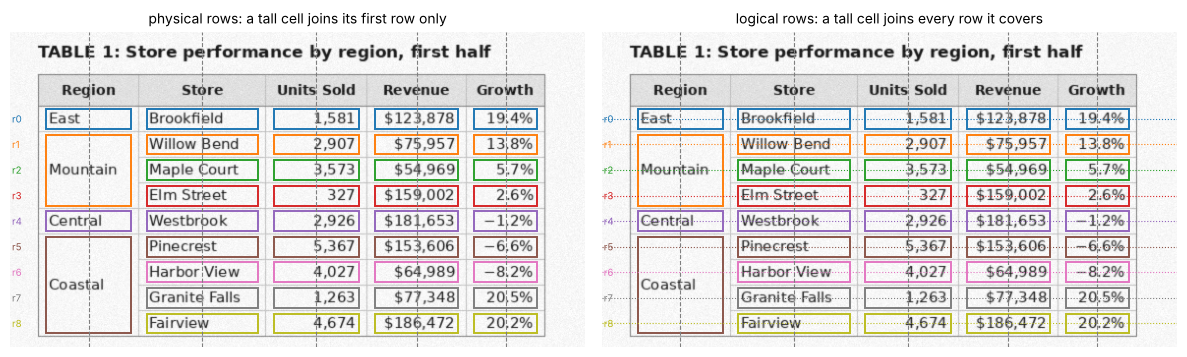

Region column, physical rows only: ['East', 'Mountain', None, None, 'Central', 'Coastal', None, None, None]
Region column, logical rows      : ['East', 'Mountain', 'Mountain', 'Mountain', 'Central', 'Coastal', 'Coastal', 'Coastal', 'Coastal']


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
x1, y1, _, _ = norm_box(t1.title_box)
zoom = (x1 - 0.03, y1 - 0.01, x1 + 0.62, norm_box(t1.boxes[(t1.n_rows - 1, 0)])[3] + 0.012)
phys = recover_tables(lay0, logical_rows=False)[1]
for ax, table, name in [(axes[0], phys, "physical rows: a tall cell joins its first row only"),
                        (axes[1], rt, "logical rows: a tall cell joins every row it covers")]:
    show_page(doc0.images[0], [], ax=ax, crop=zoom, title=name)
    colors = plt.cm.tab10(np.arange(table.n_rows) % 10)
    for r, row in enumerate(table.cells):
        mid = float(np.median([(cl["bbox"][1] + cl["bbox"][3]) / 2 for cl in row[1:] if cl]))
        ax.text(zoom[0] * PAGE_W + 2, mid * PAGE_H, f"r{r}", fontsize=7, color=colors[r], va="center")
        if table is rt:
            ax.axhline(mid * PAGE_H, color=colors[r], ls=":", lw=0.8)
        for c, cell in enumerate(row):
            if cell is not None and (c > 0 or table is phys or cell is not (table.cells[r - 1][0] if r else None)):
                bx = cell["bbox"]
                ax.add_patch(Rectangle((bx[0] * PAGE_W, bx[1] * PAGE_H), (bx[2] - bx[0]) * PAGE_W,
                                       (bx[3] - bx[1]) * PAGE_H, fill=False, ec=colors[r], lw=1.4))
    for hb in table.header_boxes:
        ax.axvline((hb[0] + hb[2]) / 2 * PAGE_W, color="tab:gray", ls="--", lw=0.8)
plt.tight_layout()
plt.show()
print("Region column, physical rows only:", [row[0]["text"] if row[0] else None for row in phys.cells])
print("Region column, logical rows      :", [row[0]["text"] if row[0] else None for row in rt.cells])

**Quick check.** The row tolerance `ROW_TOL` is about half the row pitch. Why not much smaller (say
one pixel), and why not larger than half a pitch?

<details><summary>Answer</summary>

Much smaller, and ordinary jitter splits a row: a block whose top moved by two pixels would start a
new row of its own, shifting every later row. Larger than half a pitch, and the tolerance window
of one row reaches past the middle between rows, so a block of the *next* row (whose top lies one
pitch lower, minus its own jitter) could be pulled into the current one. Half a pitch is the
largest window that stays on its side of the midpoint, which gives jitter the most room.
</details>

### 6.5 How well is the structure recovered?

We compare the recovered grids with the generator's ground truth on `DEV`. A gold cell counts as
**placed** if the recovered cell at the same (row, column) overlaps its box with IoU ≥ 0.5 (texts
are not compared, since OCR noise may legitimately change them). A grid is **perfect** if the row
count, column count and every cell placement are right. We vary the OCR noise level and switch off
one step at a time.

In [46]:
def noise_seed(doc_id: str, level: float) -> int:
    """A fixed noise seed per (document, level), so every experiment sees the same noisy OCR."""
    return int(re.sub(r"\D", "", doc_id)) * 101 + int(level * 1000)


def structure_report(docs: dict, level: float, **flags) -> dict:
    n_tab = found = perfect = n_cells = placed = 0
    for d in docs.values():
        tables = recover_tables(layout_of(d, level, noise_seed(d.doc_id, level)), **flags)
        for t in d.tables:
            rtab = tables.get(t.number)
            good = 0
            for (r, c), box in t.boxes.items():
                ok = rtab is not None and r < rtab.n_rows and c < len(rtab.headers)
                cell = rtab.cells[r][c] if ok else None
                good += int(cell is not None and iou(cell["bbox"], norm_box(box)) >= 0.5)
            n_tab, found, n_cells, placed = n_tab + 1, found + (rtab is not None), n_cells + len(t.boxes), placed + good
            perfect += int(rtab is not None and rtab.n_rows == t.n_rows and len(rtab.headers) == len(t.columns)
                           and good == len(t.boxes))
    return dict(tables_found=found / n_tab, perfect_grids=perfect / n_tab, cells_placed=placed / n_cells)


configs = [("full pipeline", 0, {}), ("full pipeline", 2, {}), ("full pipeline", 4, {}),
           ("no logical rows", 0, {"logical_rows": False}),
           ("no split re-joining", 2, {"merge_splits": False}), ("no split re-joining", 4, {"merge_splits": False})]
display(pd.DataFrame([dict(config=name, ocr_noise=lvl, **structure_report(DEV_DOCS, lvl, **fl))
                      for name, lvl, fl in configs]).round(3))

,config,ocr_noise,tables_found,perfect_grids,cells_placed
0,full pipeline,0,1.000,1.000,1.000
1,full pipeline,2,1.000,1.000,1.000
2,full pipeline,4,0.985,0.985,0.985
3,no logical rows,0,1.000,0.369,0.938
4,no split re-joining,2,0.923,0.646,0.849
5,no split re-joining,4,0.846,0.554,0.723


Reading the table:

- On clean OCR the geometry is recovered perfectly, and light noise (level 2) changes nothing.
- Without logical rows only 36.9% of the grids are perfect: every table with a merged cell loses
  the group value of the lower rows of each merged group.
- Without re-joining, split headers create phantom columns and split titles hide whole tables:
  at noise level 4 only 84.6% of the tables are even found and 55.4% of the grids are perfect.
  With re-joining, 98.5% of the grids survive level 4. The missing 1.5% is a single table (one of
  65) that was never *found*: `tables_found` drops by the same amount, so every table that was found
  is perfect. OCR split its title right after `TABLE`, jitter widened that gap to just above
  `max_gap`, so the pieces stayed apart, and neither `TABLE` (too narrow) nor
  `1: Project portfolio status, ...` (wrong first word) looked like a title. A gap threshold can fail
  in both directions: pieces of one text jittered apart, as here, or neighboring cells jittered
  together.

> **Going deeper.** Real tables are messier: missing ruling lines, multi-line cells, cells spanning
> columns, rotated pages, tables that continue onto the next page. Geometry rules can be extended
> (e.g., cluster x-edges to find columns, use ruling lines detected with OpenCV morphology), but at
> some point a learned **table structure recognition** model such as Table Transformer pays off.
> The idea of this section, *predict cells, then assign rows and columns geometrically*, remains the
> backbone of most systems.

In [47]:
# ✏️ Exercise 5: grouping blocks into physical rows
def my_group_rows(tops: list, tol: float) -> list:
    """Group block indices into rows by their top y.

    Process blocks in order of increasing top. A block joins the current row if its top is at most
    `tol` below the top of the row's FIRST block, otherwise it starts a new row.
    Return the rows from top to bottom, each as a sorted list of block indices.
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert my_group_rows([0.30, 0.10, 0.101, 0.205, 0.099, 0.20], 0.01) == [[1, 2, 4], [3, 5], [0]], \
        f"got {my_group_rows([0.30, 0.10, 0.101, 0.205, 0.099, 0.20], 0.01)}"
    assert my_group_rows([0.0, 0.008, 0.016, 0.024], 0.01) == [[0, 1], [2, 3]], \
        "compare with the FIRST top of the row, not with the previous block (no chaining)"
    assert my_group_rows([], 0.01) == [] and my_group_rows([0.5], 0.01) == [[0]], "edge cases"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_group_rows(tops, tol):
    rows = []
    for i in sorted(range(len(tops)), key=lambda i: tops[i]):
        if rows and tops[i] - tops[rows[-1][0]] <= tol:
            rows[-1].append(i)
        else:
            rows.append([i])
    return [sorted(r) for r in rows]
```
Anchoring on the row's first block prevents **chaining**: with "compare to the previous block", a
slow drift of tops (0.000, 0.008, 0.016, ...) would glue all rows into one.
</details>

In [48]:
# ✏️ Exercise 6: assigning blocks to columns by header centers
def my_assign_columns(block_boxes: list, header_boxes: list) -> list:
    """For each block box [x1, y1, x2, y2], the index of the header whose center x is nearest
    to the block's center x (ties: the smaller index). Return a list of Python ints."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    headers = [[0.10, 0.1, 0.20, 0.12], [0.25, 0.1, 0.40, 0.12], [0.45, 0.1, 0.55, 0.12]]
    blocks = [[0.11, 0.2, 0.19, 0.22],      # centered cell -> 0
              [0.26, 0.2, 0.31, 0.22],      # short left-aligned name in column 1 -> 1
              [0.50, 0.2, 0.55, 0.22],      # short right-aligned number in column 2 -> 2
              [0.30, 0.2, 0.39, 0.22]]      # -> 1
    out = my_assign_columns(blocks, headers)
    assert [int(v) for v in out] == [0, 1, 2, 1], f"got {out}"
    assert my_assign_columns([], headers) == [], "no blocks -> empty list"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_assign_columns(block_boxes, header_boxes):
    centers = [(h[0] + h[2]) / 2 for h in header_boxes]
    return [int(np.argmin([abs((b[0] + b[2]) / 2 - c) for c in centers])) for b in block_boxes]
```
`np.argmin` returns the first index among equal minima, which gives the required tie rule.
</details>

## 7. Retrieval, numbers and the text-only solvers

With grids and intents in hand, answering is "find the cells, then compute". Two supporting skills
come first: reading numbers robustly and printing them in the document's own format.

### 7.1 Parsing numbers robustly

A cell text such as `$172,644` or `−3.2%` must become a float before we can add or compare it.
Python's `float()` fails on all of these, so we write a parser that handles, in order:

1. **Signs**: the typographic minus `−` (U+2212, not the ASCII hyphen `-`), an explicit `+`, and
   accounting negatives in parentheses, `(1,250)` = −1250.
2. **Decoration**: `$`, `%`, spaces.
3. **OCR look-alikes**: `O`→`0`, `l`→`1`, `S`→`5`, `B`→`8`, ... (the same map as for titles).
4. **Separators**: `,` is normally a thousands separator, but OCR sometimes swaps `,` and `.`.
   In our reports decimals have at most two digits and thousands groups have exactly three, so
   `20,2` must be a misread `20.2` and `4.674` a misread `4,674`.

> **Common pitfall.** Rules like step 4 encode *domain assumptions*. In a European report `1.250`
> means one thousand two hundred fifty and `1,25` means one and a quarter. Write such assumptions
> down, because they are exactly what breaks when the data source changes.

In [49]:
def parse_number(text) -> float | None:
    """Parse '1,250', '$172,644', '$249.99', '−3.2%', '+12', '(1,250)' and common OCR slips.

    Returns None if the text is not a number.
    """
    if text is None:
        return None
    t = str(text).strip().replace(" ", "")
    neg = False
    if len(t) > 2 and t[0] == "(" and t[-1] == ")":           # accounting negative
        neg, t = True, t[1:-1]
    t = t.replace(MINUS, "-").replace("–", "-")
    if t[:1] in ("+", "-") and len(t) > 1:
        neg, t = neg != (t[0] == "-"), t[1:]
    t = t.replace("$", "").replace("%", "").translate(LOOKALIKE_DIGITS)
    if not re.fullmatch(r"[\d,.]*\d[\d,.]*", t):
        return None
    if "," in t and "." in t:                                  # the later symbol is the decimal point
        dec = "." if t.rfind(".") > t.rfind(",") else ","
        t = t.replace("," if dec == "." else ".", "").replace(",", ".")
    elif t.count(",") == 1 and re.search(r",\d{1,2}$", t):    # '20,2' : misread decimal point
        t = t.replace(",", ".")
    elif t.count(".") == 1 and re.search(r"\.\d{3}$", t):      # '4.674': misread thousands comma
        t = t.replace(".", "")
    else:
        t = t.replace(",", "")
    try:
        v = float(t)
    except ValueError:
        return None
    return -v if neg else v


tests = ["1,250", "$172,644", "$249.99", "−3.2%", "+12", "(1,250)", "l,25O", "20,2%", "4.674", "$S0,000",
         "Oakridge", "N/A", "1.234.567"]
display(pd.DataFrame({"text": tests, "parsed": [parse_number(s) for s in tests]}).T)

,0,1,2,3,4,5,6,7,8,9,10,11,12
text,"1,250","$172,644",$249.99,−3.2%,+12,"(1,250)","l,25O","20,2%",4.674,"$S0,000",Oakridge,N/A,1.234.567
parsed,1250.0,172644.0,249.99,-3.2,12.0,-1250.0,1250.0,20.2,4674.0,50000.0,NaN,NaN,NaN


### 7.2 Printing numbers the document's way

ANLS compares strings, so `270007` for a gold `$270,007` loses 2 characters out of 8. The fix is to
learn each column's **format** from its own cells (currency sign? percent? how many decimals? an
explicit `+`? thousands separators?) and print computed numbers the same way. Each property is
decided by a vote over the column's cells, so one OCR slip does not change the format.

In [50]:
@dataclass(frozen=True)
class NumberFormat:
    currency: bool = False
    percent: bool = False
    decimals: int = 0
    plus_sign: bool = False
    thousands: bool = True


def infer_format(texts) -> NumberFormat:
    """Majority-vote the printing format of a numeric column from its cell texts."""
    texts = [s.replace(" ", "") for s in texts if s and parse_number(s) is not None]
    if not texts:
        return NumberFormat()
    decimals = Counter(len(m.group(1)) if (m := re.search(r"\.(\d+)%?$", s)) else 0 for s in texts)
    return NumberFormat(
        currency=bool(np.mean(["$" in s for s in texts]) >= 0.5),
        percent=bool(np.mean(["%" in s for s in texts]) >= 0.5),
        decimals=decimals.most_common(1)[0][0],
        plus_sign=any(s.startswith("+") for s in texts),
        thousands=_mostly([("," in s) for s in texts if abs(parse_number(s)) >= 1000], default=True))


def _mostly(flags: list, default: bool) -> bool:
    """Majority vote of a list of booleans (default when the list is empty)."""
    return default if not flags else bool(np.mean(flags) >= 0.5)


def format_number(v: float, fmt: NumberFormat) -> str:
    """Print v in the given format (typographic minus, like the documents)."""
    v = round(v, fmt.decimals) + 0.0                          # + 0.0 turns -0.0 into 0.0
    body = f"{abs(v):,.{fmt.decimals}f}" if fmt.thousands else f"{abs(v):.{fmt.decimals}f}"
    sign = MINUS if v < 0 else ("+" if fmt.plus_sign and v > 0 else "")
    return sign + ("$" if fmt.currency else "") + body + ("%" if fmt.percent else "")


for col_texts, v in [(["$12,500", "$7,250", "$980"], 20730.0), (["8.5%", "−3.2%", "12.0%"], 17.3),
                     (["+12", "−7", "0", "+3"], -4.0), (["$249.99", "$19.99"], 269.98), (["14", "250", "33"], 1297.0)]:
    fmt = infer_format(col_texts)
    print(f"{str(col_texts):32} -> {fmt}\n{'':32}    {v} printed as {format_number(v, fmt)!r}")

['$12,500', '$7,250', '$980']    -> NumberFormat(currency=True, percent=False, decimals=0, plus_sign=False, thousands=True)
                                    20730.0 printed as '$20,730'
['8.5%', '−3.2%', '12.0%']       -> NumberFormat(currency=False, percent=True, decimals=1, plus_sign=False, thousands=True)
                                    17.3 printed as '17.3%'
['+12', '−7', '0', '+3']         -> NumberFormat(currency=False, percent=False, decimals=0, plus_sign=True, thousands=True)
                                    -4.0 printed as '−4'
['$249.99', '$19.99']            -> NumberFormat(currency=True, percent=False, decimals=2, plus_sign=False, thousands=True)
                                    269.98 printed as '$269.98'
['14', '250', '33']              -> NumberFormat(currency=False, percent=False, decimals=0, plus_sign=False, thousands=True)
                                    1297.0 printed as '1,297'


In [51]:
# ✏️ Exercise 7: a number parser
def my_parse_number(text: str):
    """Parse a printed number into a float, or return None if it is not a number.

    Must handle: thousands commas ('3,225'), '$', '%', a leading '+', the typographic minus '−'
    (U+2212), accounting negatives in parentheses ('(450)'), and the OCR look-alikes 'O' -> 0 and
    'l' -> 1. Decimal points are '.', and you may assume commas are always thousands separators.
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    cases = {"3,225": 3225.0, "$172,644": 172644.0, "$249.99": 249.99, "−3.2%": -3.2, "8.5%": 8.5,
             "+12": 12.0, "(450)": -450.0, "1,25O": 1250.0, "l2": 12.0, "0": 0.0}
    for s, v in cases.items():
        got = my_parse_number(s)
        assert got is not None and abs(got - v) < 1e-9, f"{s!r}: expected {v}, got {got}"
    for s in ["Oakridge", "", "N/A", "$"]:
        assert my_parse_number(s) is None, f"{s!r} is not a number, got {my_parse_number(s)}"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_parse_number(text):
    t = text.strip().replace(" ", "")
    neg = False
    if len(t) > 2 and t.startswith("(") and t.endswith(")"):
        neg, t = True, t[1:-1]
    t = t.replace("−", "-")
    if t[:1] in ("+", "-"):
        neg, t = neg != (t[0] == "-"), t[1:]
    t = t.replace("$", "").replace("%", "").replace(",", "").replace("O", "0").replace("l", "1")
    if not re.fullmatch(r"\d+(\.\d+)?", t):
        return None
    return -float(t) if neg else float(t)
```
The final `re.fullmatch` is the gatekeeper: after stripping decorations, only digits with an
optional decimal part may remain, so names like "Oakridge" and placeholders like "N/A" are rejected.
</details>

### 7.3 Retrieval: from conditions to exactly one row

A row descriptor such as `Store "Riverside" in Region "East"` is a set of conditions. Retrieval
scores every row by its **weakest** condition (the minimum similarity over conditions) and keeps
the best row, but only if it is good enough *and* strictly better than the runner-up. Two equally
good rows mean the question is ambiguous for us, and returning one of them at random would be a
guess dressed up as an answer.

Comparisons use `nls` (normalized Levenshtein similarity), so `Lakcside` (an OCR slip) still
matches `Lakeside` with similarity 0.875. Column names are **resolved** against the recovered
headers the same way: exactly if possible, otherwise the most similar header.

In [52]:
FUZZY_MATCHING = True     # switched off only in the ablation study of Section 10


def text_similarity(a: str, b: str) -> float:
    """NLS when fuzzy matching is on, otherwise 1.0 for an exact (normalized) match, else 0.0."""
    return nls(a, b) if FUZZY_MATCHING else float(normalize_answer(a) == normalize_answer(b))


def resolve_column(name, headers: list, min_sim: float = 0.7):
    """Index of the header matching `name` (exact, case-insensitive, else fuzzy), or None."""
    if not name or not headers:
        return None
    low = [h.lower() for h in headers]
    if name.lower() in low:
        return low.index(name.lower())
    sims = [text_similarity(name, h) for h in headers]
    best = int(np.argmax(sims))
    return best if sims[best] >= min_sim else None


def cell_text(rt: RecoveredTable, r: int, c: int) -> str:
    cell = rt.cells[r][c]
    return cell["text"] if cell is not None else ""


def row_scores(rt: RecoveredTable, conds: list):
    """(per-row score = weakest condition similarity, resolved condition columns)."""
    cols = [resolve_column(name, rt.headers) for name, _ in conds]
    if not conds or any(c is None for c in cols):
        return None, cols
    scores = np.array([min(text_similarity(cell_text(rt, r, c), v) for c, (_, v) in zip(cols, conds))
                       for r in range(rt.n_rows)])
    return scores, cols


def retrieve_row(rt: RecoveredTable, conds: list, min_sim: float = 0.75):
    """(row, confidence) of the unique best row matching all conditions, else (None, 0.0)."""
    scores, cols = row_scores(rt, conds)
    if scores is None or len(scores) == 0:
        return None, 0.0
    order = np.argsort(-scores, kind="stable")
    best = scores[order[0]]
    second = scores[order[1]] if len(scores) > 1 else -1.0
    if best < min_sim or best == second:
        return None, 0.0
    return int(order[0]), float(best)


def cells_evidence(rt: RecoveredTable, cells) -> list:
    """Evidence entries for (row, col) cells. A merged cell (shared by several rows) appears once."""
    out, seen = [], set()
    for r, c in cells:
        cell = rt.cells[r][c] if r is not None and c is not None else None
        if cell is not None and cell["ids"] not in seen:
            seen.add(cell["ids"])
            out.append({"page": rt.page, "bbox": cell["bbox"]})
    return out


for conds in ([("Store", "Harbor View")], [("Store", "Harbr View")], [("Region", "Coastal")],
              [("Store", "Unknown Place")]):
    print(f"{str(conds):40} -> row, confidence = {retrieve_row(rt, conds)}")

[('Store', 'Harbor View')]               -> row, confidence = (6, 1.0)
[('Store', 'Harbr View')]                -> row, confidence = (6, 0.9090909090909091)
[('Region', 'Coastal')]                  -> row, confidence = (None, 0.0)
[('Store', 'Unknown Place')]             -> row, confidence = (None, 0.0)


The third query is ambiguous on purpose: four rows have Region "Coastal", so a *row* retrieval
refuses to choose (count questions, which want all matching rows, use `row_scores` directly).

### 7.4 The solvers

Every solver has the same signature, `solver(intent, tables, layout) -> Prediction`, and follows the
same recipe: resolve the table and column, retrieve the rows, collect the cells (these become the
evidence), compute, format. A `Prediction` carries a **confidence** in $[0, 1]$ (here: the weakest
retrieval similarity, lowered further when the answer rests on a repaired or suspicious cell) and a
**note** explaining failures, which makes debugging pleasant.

A few small but valuable tricks:

- For **compare**, the answer is copied from the *question's* quoted value of the winning row, not
  from the OCR text. The question is typed text, so it is spelled correctly even if the page
  was misread.
- For **lookup**, a numeric cell is re-printed through `parse_number` → `format_number`, which
  repairs look-alike slips such as `l,250` or `20,2%`. The repair is only accepted if it keeps the
  number of digits, so a cell whose digit was *dropped* (`4,74` for `4,674`) is not turned into a
  confident-looking `5`. The mirror-image repair for **names** turns digits inside words back into
  letters (`Mobi1e` → `Mobile`).
- Values that contradict their column's format (a fractional value in a whole-number column) are
  treated as unreadable by `argmax`, `argmin` and threshold counts, and every answer's
  **confidence** is lowered when it rests on a repaired or suspicious cell.

In [53]:
@dataclass
class Prediction:
    answer: str = ""
    evidence: list = field(default_factory=list)
    confidence: float = 0.0
    note: str = ""


def column_format(rt: RecoveredTable, c: int) -> NumberFormat:
    """The column's printing format, computed once per table and cached."""
    if c not in rt.fmt_cache:
        rt.fmt_cache[c] = infer_format([cell_text(rt, r, c) for r in range(rt.n_rows)])
    return rt.fmt_cache[c]


def cell_value(rt: RecoveredTable, r: int, c: int, strict: bool = False):
    """Numeric value of a cell. strict=True also rejects values that contradict the column format,
    e.g. 4.74 in a whole-number column (a misread '4,674' with a dropped digit)."""
    v = parse_number(cell_text(rt, r, c))
    if v is not None and strict and column_format(rt, c).decimals == 0 and v != round(v):
        return None
    return v


def _digits(s: str) -> int:
    return len(re.sub(r"\D", "", s.translate(LOOKALIKE_DIGITS)))


def cond_columns(rt: RecoveredTable, conds: list) -> list:
    return [resolve_column(name, rt.headers) for name, _ in conds]


def clean_numeric_text(rt: RecoveredTable, r: int, c: int) -> str:
    """Re-print a numeric cell in its column's format if that only fixes OCR slips."""
    raw = cell_text(rt, r, c)
    v = parse_number(raw) if rt.numeric[c] else None
    if v is None:
        return raw
    fixed = format_number(v, column_format(rt, c))
    return fixed if _digits(fixed) == _digits(raw) else raw      # same digits: only slips were fixed


def value_quality(rt: RecoveredTable, r: int, c: int) -> float:
    """1.0 if a numeric cell is printed exactly in its column's format, 0.8 if it needed a repair,
    0.3 if it is unreadable or suspicious (used to lower the confidence of answers built on it)."""
    raw, v = cell_text(rt, r, c), cell_value(rt, r, c, strict=True)
    if v is None:
        return 0.3
    fixed = format_number(v, column_format(rt, c))
    return 1.0 if fixed == raw.strip() else (0.8 if _digits(fixed) == _digits(raw) else 0.3)


DIGIT_TO_LETTER = str.maketrans({"0": "O", "1": "l", "5": "S", "8": "B", "6": "b", "2": "Z"})


def clean_name_text(text: str) -> str:
    """Undo digit look-alikes inside words: 'Mobi1e App' -> 'Mobile App', '0akridge' -> 'Oakridge'."""
    return " ".join(w.translate(DIGIT_TO_LETTER) if re.search(r"[A-Za-z]", w) and re.search(r"\d", w) else w
                    for w in text.split(" "))


def _table_and_column(it: StructuredIntent, tables: dict, number=None):
    rt = tables.get(it.table if number is None else number)
    c = resolve_column(it.column, rt.headers) if rt is not None else None
    return rt, c


def solve_lookup(it, tables, layout) -> Prediction:
    rt, c = _table_and_column(it, tables)
    if rt is None or c is None:
        return Prediction(note="table or column not found")
    r, conf = retrieve_row(rt, it.operands[0])
    if r is None:
        return Prediction(note=f"no unique row for {it.operands[0]}")
    cells = [(r, k) for k in cond_columns(rt, it.operands[0])] + [(r, c)]
    conf = min(conf, value_quality(rt, r, c)) if rt.numeric[c] else conf
    return Prediction(clean_numeric_text(rt, r, c), cells_evidence(rt, cells), conf)


def solve_count(it, tables, layout) -> Prediction:
    rt = tables.get(it.table)
    if rt is None:
        return Prediction(note="table not found")
    if it.op and it.threshold:                                  # rows above / below a threshold
        c, thr = resolve_column(it.column, rt.headers), parse_number(it.threshold)
        if c is None or thr is None:
            return Prediction(note="threshold column or value not understood")
        vals = [cell_value(rt, r, c, strict=True) for r in range(rt.n_rows)]
        rows = [r for r, v in enumerate(vals) if v is not None and (v > thr if it.op == ">" else v < thr)]
        conf = min(value_quality(rt, r, c) for r in range(rt.n_rows))
        return Prediction(str(len(rows)), cells_evidence(rt, [(r, c) for r in rows]), conf)
    scores, cols = row_scores(rt, it.operands[0])               # rows of a group
    if scores is None:
        return Prediction(note="condition column not found")
    rows = [r for r in range(rt.n_rows) if scores[r] >= 0.75]
    return Prediction(str(len(rows)), cells_evidence(rt, [(r, k) for r in rows for k in cols]), 1.0)


def _rows_and_values(rt, c, operands):
    """Retrieve each operand's row and value. Returns (rows, values, cells, confidence) or a note."""
    rows, vals, cells, conf = [], [], [], 1.0
    for op in operands:
        r, cf = retrieve_row(rt, op)
        v = cell_value(rt, r, c) if r is not None else None
        if v is None:
            return f"no unique row or unreadable value for {op}"
        rows.append(r); vals.append(v); conf = min(conf, cf, value_quality(rt, r, c))
        cells += [(r, k) for k in cond_columns(rt, op)] + [(r, c)]
    return rows, vals, cells, conf


def solve_sum(it, tables, layout) -> Prediction:
    rt, c = _table_and_column(it, tables)
    if rt is None or c is None:
        return Prediction(note="table or column not found")
    got = _rows_and_values(rt, c, it.operands)
    if isinstance(got, str):
        return Prediction(note=got)
    _, vals, cells, conf = got
    return Prediction(format_number(sum(vals), column_format(rt, c)), cells_evidence(rt, cells), conf)


def solve_compare(it, tables, layout) -> Prediction:
    rt, c = _table_and_column(it, tables)
    if rt is None or c is None:
        return Prediction(note="table or column not found")
    got = _rows_and_values(rt, c, it.operands)
    if isinstance(got, str):
        return Prediction(note=got)
    _, (v0, v1), cells, conf = got
    win = 0 if (v0 > v1) == bool(it.higher) else 1
    conf = conf if v0 != v1 else 0.0                            # a tie: we cannot decide
    return Prediction(it.operands[win][0][1], cells_evidence(rt, cells), conf)

For **argmax / argmin** the evidence must be *minimal identifying*: the item cell of the winning row,
plus its group cell only when the item name appears more than once in the table (with a fuzzy
comparison, since OCR may have misspelled one copy), plus the winning value. The **cross-page sum**
simply runs the same retrieval in two tables, which may live on different pages, and the evidence list
then contains boxes from both pages.

In [54]:
def _solve_extreme(it, tables, largest: bool) -> Prediction:
    rt, c = _table_and_column(it, tables)
    if rt is None or c is None:
        return Prediction(note="table or column not found")
    vals = [cell_value(rt, r, c, strict=True) for r in range(rt.n_rows)]
    valid = [r for r, v in enumerate(vals) if v is not None]
    if not valid:
        return Prediction(note="no readable values")
    r = max(valid, key=lambda i: vals[i]) if largest else min(valid, key=lambda i: vals[i])
    keys = [k for k in range(len(rt.headers)) if not rt.numeric[k]]
    ic = resolve_column(it.item_column, rt.headers) if it.item_column else None
    ic = ic if ic is not None else (keys[-1] if keys else 0)
    item = cell_text(rt, r, ic)
    repeated = sum(nls(cell_text(rt, r2, ic), item) >= 0.85 for r2 in range(rt.n_rows)) > 1
    cells = [(r, ic)] + ([(r, k) for k in keys if k != ic] if repeated else []) + [(r, c)]
    conf = min(value_quality(rt, r2, c) for r2 in range(rt.n_rows))
    return Prediction(clean_name_text(item), cells_evidence(rt, cells), conf)


def solve_argmax(it, tables, layout) -> Prediction:
    return _solve_extreme(it, tables, largest=True)


def solve_argmin(it, tables, layout) -> Prediction:
    return _solve_extreme(it, tables, largest=False)


def solve_cross_page_sum(it, tables, layout) -> Prediction:
    total, evidence, conf, fmt = 0.0, [], 1.0, None
    for number in (it.table, it.table2):
        rt, c = _table_and_column(it, tables, number)
        if rt is None or c is None:
            return Prediction(note=f"table {number} or its column not found")
        got = _rows_and_values(rt, c, it.operands[:1])
        if isinstance(got, str):
            return Prediction(note=f"table {number}: {got}")
        _, (v,), cells, cf = got
        total, conf = total + v, min(conf, cf)
        fmt = fmt or column_format(rt, c)
        evidence += cells_evidence(rt, cells)
    return Prediction(format_number(total, fmt), evidence, conf)


SOLVERS = {"lookup": solve_lookup, "count": solve_count, "sum": solve_sum, "compare": solve_compare,
           "argmax": solve_argmax, "argmin": solve_argmin, "cross_page_sum": solve_cross_page_sum}

**Quick check.** The compare solver answers with the item name typed in the *question*, but the
argmax solver answers with the name read by OCR. Why can't argmax copy from the question as well?

<details><summary>Answer</summary>

A compare question names both candidates, so the answer is one of two strings we already have in
clean form. An argmax question names no row at all: the winner is discovered in the table, and the
page is the only place its name is written. That is why the argmax answer goes through
`clean_name_text`, and why an OCR typo in a name (`Planncr`) still costs a little ANLS.
</details>

### 7.5 First results (text-only types, clean OCR)

Let us run parse → recover → solve on all `DEV` questions except the bold ones, which need pixels.
On clean OCR we expect (and want) near-perfect scores, and anything less is a bug to hunt now, while the
setting is still simple.

In [55]:
def run_text_solvers(questions: list, docs: dict, level: float = 0.0) -> pd.DataFrame:
    rows, cache = [], {}
    for q in questions:
        if q["type"] == "visual_bold_lookup":
            continue
        if q["doc_id"] not in cache:
            lay = layout_of(docs[q["doc_id"]], level, noise_seed(q["doc_id"], level))
            tabs = recover_tables(lay)
            cache[q["doc_id"]] = (lay, tabs, schema_of(tabs))
        lay, tabs, schema = cache[q["doc_id"]]
        it = parse_question(q["question"], schema)
        pred = SOLVERS[it.qtype](it, tabs, lay) if (not it.missing() and it.qtype in SOLVERS) else Prediction(note="unparsed")
        rows.append(dict(question_id=q["question_id"], type=q["type"], pred=pred.answer, gold=q["answer"],
                         note=pred.note, **score_one(dict(answer=pred.answer, evidence=pred.evidence), q)))
    return pd.DataFrame(rows)


res_text = run_text_solvers(DEV, DEV_DOCS)
display(res_text.groupby("type")[["anls", "ev_f1", "score"]].mean().loc[[t for t in TYPES if t in SOLVERS]].round(3))
print("overall score (text types):", round(res_text.score.mean(), 4))
bad = res_text[res_text.score < 1]
print(f"{len(bad)} imperfect answers" + (":" if len(bad) else "."))
if len(bad):
    display(bad.head(5)[["type", "pred", "gold", "note", "anls", "ev_f1"]])

,anls,ev_f1,score
type,,,
lookup,1.0,1.0,1.0
count,1.0,1.0,1.0
sum,1.0,1.0,1.0
compare,1.0,1.0,1.0
argmax,1.0,1.0,1.0
argmin,1.0,1.0,1.0
cross_page_sum,1.0,1.0,1.0


overall score (text types): 1.0
0 imperfect answers.


Every text-only question on clean OCR is answered perfectly, with perfect evidence. That is the
promise of the structured approach on regular data, and also its danger: perfect scores on clean
development data tell us nothing about robustness. Section 10 stresses the pipeline.

Adding a new reasoning type is now a small, local change: a template (or a cue), and a solver
written with the same building blocks. Try it.

In [56]:
# ✏️ Exercise 8: a new solver, difference
def my_solve_difference(it: StructuredIntent, tables: dict, layout=None) -> Prediction:
    """Answer 'In Table n, by how much does the <column> of A exceed that of B?'

    it.table, it.column and it.operands = [conditions_of_A, conditions_of_B] are filled in.
    Return a Prediction whose answer is value_A - value_B printed in the column's format and whose
    evidence is the condition cells + value cells of both rows. If a row or the column cannot be
    found, return Prediction() with an empty answer (do not crash).
    Helpers you can use: _table_and_column, _rows_and_values, column_format, format_number,
    cells_evidence.
    """
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    t = doc0.table(1)                                      # generator side, used to build expectations
    for col, (ra, rb) in [("Revenue", (1, 5)), ("Revenue", (5, 1)), ("Growth", (0, 3))]:
        c = t.col_index(col)
        ops = [key_conditions(t, ra), key_conditions(t, rb)]
        want = format_value(t.values[ra][c] - t.values[rb][c], t.columns[c].kind)
        want_ev = cells_to_evidence(t, cond_cells(t, ra, ops[0]) + [(ra, c)] + cond_cells(t, rb, ops[1]) + [(rb, c)])
        pred = my_solve_difference(StructuredIntent("difference", table=1, column=col, operands=ops), rec0, lay0)
        assert pred.answer == want, f"{col} rows {ra}-{rb}: expected {want!r}, got {pred.answer!r}"
        assert evidence_prf(pred.evidence, want_ev)[2] == 1.0, f"evidence differs from {want_ev}"
    nowhere = StructuredIntent("difference", table=1, column="Revenue",
                               operands=[[("Store", "Nowhere Plaza")], key_conditions(t, 0)])
    assert my_solve_difference(nowhere, rec0, lay0).answer == "", "a missing row must give an empty answer"


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def my_solve_difference(it, tables, layout=None):
    rt, c = _table_and_column(it, tables)
    if rt is None or c is None:
        return Prediction(note="table or column not found")
    got = _rows_and_values(rt, c, it.operands)
    if isinstance(got, str):                     # a note explaining what was not found
        return Prediction(note=got)
    _, (va, vb), cells, conf = got
    return Prediction(format_number(va - vb, column_format(rt, c)), cells_evidence(rt, cells), conf)
```
Because retrieval collects the cells it touches, the evidence comes for free. To make the new type
reachable you would also add a template such as "By how much does the {col} of {desc1} exceed
that of {desc2} in Table {t}?", a cue for the fallback parser, and `SOLVERS["difference"] = ...`.
</details>

## 8. Reading pixels: which row is bold?

### 8.1 Why we need the image

A `visual_bold_lookup` question names two rows and says one of them is printed in bold. OCR text
and boxes are identical for bold and regular text (we even made column widths independent of
boldness), so the answer exists **only in the pixels**. And scanning makes it harder: blur spreads
thin and thick strokes toward the same gray smear. Here is the same bold and regular cell re-scanned
with each scan profile.

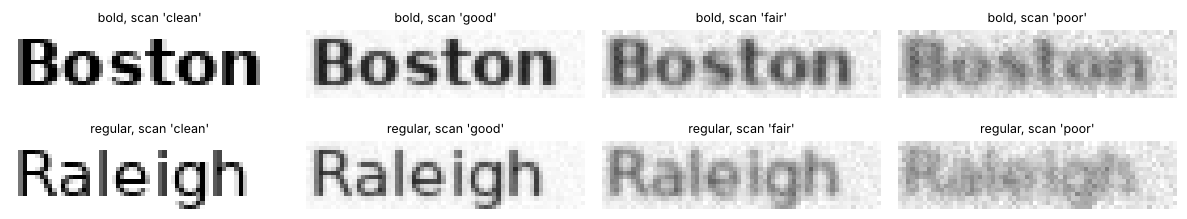

In [57]:
def crop_box(img: np.ndarray, bbox, shrink: int = 2) -> np.ndarray:
    """Pixels inside a normalized box, shrunk by `shrink` px on each side (avoids neighbor ink)."""
    H, W = img.shape
    x1, y1, x2, y2 = bbox
    X1, X2 = int(round(x1 * W)) + shrink, int(round(x2 * W)) - shrink
    Y1, Y2 = int(round(y1 * H)) + shrink, int(round(y2 * H)) - shrink
    return img[max(Y1, 0):max(Y2, Y1 + 1, 0), max(X1, 0):max(X2, X1 + 1, 0)]


bold_doc = next(d for d in DEV_DOCS.values() if any(t.bold_rows and t.emphasis == "full" for t in d.tables))
bt = next(t for t in bold_doc.tables if t.bold_rows and t.emphasis == "full")
rb_demo = min(bt.bold_rows)
ro_demo = next(r for r in range(bt.n_rows) if r not in bt.bold_rows)
clean_page = render_page(bold_doc, bt.page)
fig, axes = plt.subplots(2, 4, figsize=(12, 2.6))
for j, prof in enumerate(SCAN_PROFILES):
    page = degrade(clean_page, prof, seed=7)
    for i, (r, lab) in enumerate([(rb_demo, "bold"), (ro_demo, "regular")]):
        axes[i, j].imshow(crop_box(page, norm_box(bt.boxes[(r, 1)])), cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"{lab}, scan '{prof}'", fontsize=9)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

On clean and good scans boldness is obvious, but on fair and poor scans the regular text also looks
heavy. We need a measurement that is as insensitive as possible to blur, and a decision rule that
compares *the two candidate rows on the same page* (same scanner, same blur), rather than
comparing a row to a fixed threshold.

### 8.2 Separating ink from paper: Otsu's threshold

First we turn a gray crop into a binary **ink mask**. Which gray level separates ink from paper?
**Otsu's method** picks the threshold $t$ that best splits the histogram into two classes. Let
$p_i$ be the fraction of pixels with gray level $i$, and for a candidate $t$ let class 0 be the
levels $\le t$ (ink) and class 1 the rest (paper), with probabilities $\omega_0(t), \omega_1(t)$
and mean levels $\mu_0(t), \mu_1(t)$. Otsu maximizes the **between-class variance**

$$
\sigma_B^2(t) = \omega_0(t)\,\omega_1(t)\,\big(\mu_0(t) - \mu_1(t)\big)^2 .
$$

Since total variance = within-class + between-class, maximizing $\sigma_B^2$ is the same as
minimizing the weighted variance *inside* the two classes: the two groups are as tight as possible.
With cumulative sums $\omega(t) = \sum_{i \le t} p_i$ and $m(t) = \sum_{i \le t} i\,p_i$, and the
global mean $m_G$, this becomes the fast formula
$\sigma_B^2(t) = \dfrac{(m_G\,\omega(t) - m(t))^2}{\omega(t)\,(1 - \omega(t))}$, evaluated for all 256
thresholds at once.

In [58]:
def otsu_threshold(gray: np.ndarray) -> int:
    """Otsu's threshold of a uint8 image: pixels <= t form one class (ink), > t the other (paper)."""
    p = np.bincount(gray.ravel(), minlength=256).astype(float)
    p /= p.sum()
    omega = np.cumsum(p)                       # P(class 0) for every threshold t
    m = np.cumsum(p * np.arange(256))          # cumulative mean
    with np.errstate(divide="ignore", invalid="ignore"):
        sigma_b = (m[-1] * omega - m) ** 2 / (omega * (1.0 - omega))
    return int(np.nanargmax(np.where(np.isfinite(sigma_b), sigma_b, np.nan)))


page_fair = degrade(clean_page, "fair", seed=7)
crop_b = crop_box(page_fair, norm_box(bt.boxes[(rb_demo, 1)]))
t_ours = otsu_threshold(crop_b)
t_cv, _ = cv2.threshold(crop_b, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print(f"Otsu threshold on a 'fair' bold crop: ours = {t_ours}, OpenCV = {int(t_cv)}")

Otsu threshold on a 'fair' bold crop: ours = 174, OpenCV = 174


### 8.3 A stroke score from the distance transform

The **distance transform** (DT) of a binary mask assigns every ink pixel its distance to the nearest
background pixel. Walk across a stroke that is $w$ pixels wide: the values are $1, 2, \dots$ up to
about $w/2$ in the middle and back down to 1, so their mean is roughly $w/4 + 1/2$. We use

$$
\text{stroke score} = 2 \cdot \operatorname{mean}_{\text{ink pixels}} \operatorname{DT} \;\approx\; \frac{w}{2} + 1,
$$

a number that grows with the stroke width $w$ but is **not** the width itself. The next cell checks
this on clean vertical bars: the score is about 1.9 for a bar 1 *or* 2 pixels wide (every pixel of
such a bar touches the background, and OpenCV's fast $3 \times 3$ approximation gives it 0.955
instead of 1), 2.5 for 3 pixels, and only about half the width for thick bars. It still separates our
two weights, because in the Otsu mask of our anti-aliased text a regular stroke is mostly 2 pixels
wide and a bold one mostly 3. Almost every regular ink pixel touches the background, so regular
cells sit at the floor of about 1.9, while bold strokes have interior pixels that lift their median
score to about 2.2 on clean scans (Section 8.4 prints the medians for every scan profile).

Two extra per-cell measurements help when blur blurs the mask itself:

- **contrast**: the gap between the paper level (90th percentile of the crop) and the darkest ink
  (5th percentile). Blur lightens thin strokes much more than thick ones, so bold text stays darker.
- **ink fraction**: the share of crop pixels in the ink mask.

stroke score of a clean bar: w=1: 1.91, w=2: 1.91, w=3: 2.50, w=4: 2.80, w=6: 3.65, w=10: 5.22
    bold: stroke score = 2.61, contrast = 158, ink fraction = 0.333
 regular: stroke score = 2.50, contrast = 110, ink fraction = 0.350


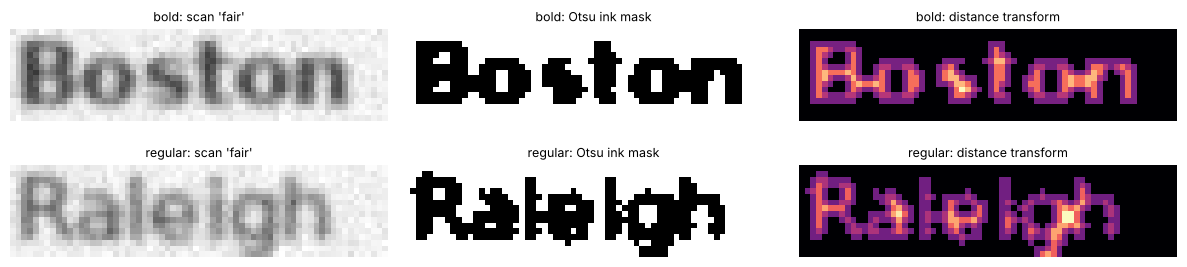

In [59]:
def stroke_features(crop: np.ndarray):
    """{'sw', 'contrast', 'ink'} of a cell crop, or None if the crop holds no plausible text.
    'sw' is the stroke score 2 * mean distance transform over the ink (it grows with the stroke width)."""
    if crop.size < 30:
        return None
    ink = crop <= otsu_threshold(crop)
    frac = float(ink.mean())
    if not 0.01 <= frac <= 0.6:
        return None
    dt = cv2.distanceTransform(ink.astype(np.uint8), cv2.DIST_L2, 3)
    dark, paper = np.percentile(crop, [5, 90])
    return {"sw": 2.0 * float(dt[ink].mean()), "contrast": float(paper - dark), "ink": frac}


# The stroke score of clean vertical bars of known width w: it grows with w, but it is not w.
bar_scores = {}
for bw in (1, 2, 3, 4, 6, 10):
    bar = np.zeros((40, 24), np.uint8)
    bar[5:35, 6:6 + bw] = 1
    bar_scores[bw] = 2.0 * float(cv2.distanceTransform(bar, cv2.DIST_L2, 3)[bar > 0].mean())
print("stroke score of a clean bar:", ", ".join(f"w={bw}: {s:.2f}" for bw, s in bar_scores.items()))

fig, axes = plt.subplots(2, 3, figsize=(12, 3.1))
for i, (r, lab) in enumerate([(rb_demo, "bold"), (ro_demo, "regular")]):
    crop = crop_box(page_fair, norm_box(bt.boxes[(r, 1)]))
    ink = crop <= otsu_threshold(crop)
    dt = cv2.distanceTransform(ink.astype(np.uint8), cv2.DIST_L2, 3)
    f = stroke_features(crop)
    styles = [dict(cmap="gray", vmin=0, vmax=255), dict(cmap="gray_r"), dict(cmap="magma")]
    for ax, im, ttl, kw in zip(axes[i], [crop, ink, dt], ["scan 'fair'", "Otsu ink mask", "distance transform"], styles):
        ax.imshow(im, **kw)
        ax.set_title(f"{lab}: {ttl}", fontsize=9)
        ax.axis("off")
    print(f"{lab:>8}: stroke score = {f['sw']:.2f}, contrast = {f['contrast']:.0f}, ink fraction = {f['ink']:.3f}")
plt.tight_layout()
plt.show()

On this blurry crop the two stroke scores differ by only about 0.1, while the contrast differs
by almost 50 gray levels: blur hides the *shape* of a bold stroke much more than its *darkness*.

### 8.4 Features for every row of every recovered table

The pipeline works on *recovered* tables, so features are computed from the recovered cell boxes.
Merged cells are skipped: they are shared by several rows and cannot tell rows apart. Key
(name) cells and numeric cells are kept apart, because in the `"label"` emphasis style only the key
cells are bold.

313 (bold, regular) row pairs from DEV in 0.3 s


median stroke score, regular / bold: clean 1.93 / 2.23, good 1.96 / 2.29, fair 2.48 / 2.69, poor 2.97 / 3.16


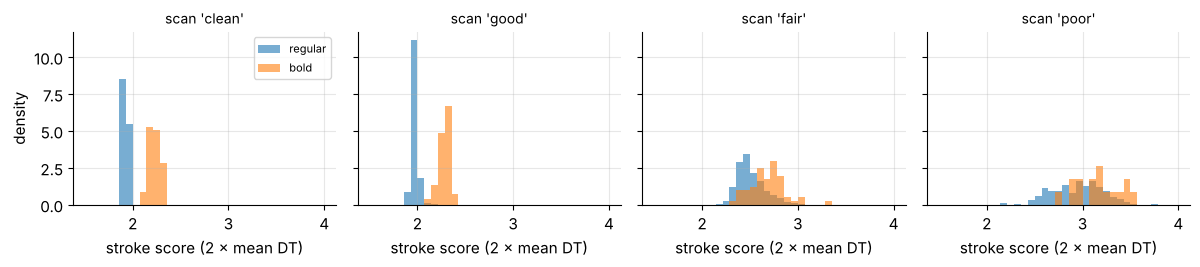

In [60]:
def row_features(layout: DocumentLayout, rt: RecoveredTable, rows=None) -> list:
    """For each row (or only the given rows), {column: stroke features} over its own (non-shared) cells."""
    uses = Counter(cell["ids"] for row in rt.cells for cell in row if cell is not None)
    img = layout.images[rt.page]
    out = []
    for r, row in enumerate(rt.cells):
        feats = {}
        for c, cell in enumerate(row if rows is None or r in rows else []):
            if cell is not None and uses[cell["ids"]] == 1:
                f = stroke_features(crop_box(img, cell["bbox"]))
                if f is not None:
                    feats[c] = f
        out.append(feats)
    return out


def bold_pairs(docs: dict) -> pd.DataFrame:
    """All (bold row, regular row) pairs of all tables, with features from the clean-OCR pipeline."""
    recs = []
    for d in docs.values():
        lay = layout_of(d)
        tabs = recover_tables(lay)
        for t in d.tables:
            rt_ = tabs.get(t.number)
            if not t.bold_rows or rt_ is None or rt_.n_rows != t.n_rows:
                continue
            feats = row_features(lay, rt_)
            for rb in sorted(t.bold_rows):
                for ro in range(t.n_rows):
                    if ro not in t.bold_rows:
                        recs.append(dict(doc=d.doc_id, profile=d.profile, emphasis=t.emphasis,
                                         numeric=tuple(rt_.numeric), fb=feats[rb], fo=feats[ro]))
    return pd.DataFrame(recs)


t0 = time.time()
PAIRS_DEV = bold_pairs(DEV_DOCS)
print(f"{len(PAIRS_DEV)} (bold, regular) row pairs from DEV in {time.time() - t0:.1f} s")

sw = defaultdict(list)                       # stroke scores of single cells, by profile and boldness
for d in DEV_DOCS.values():
    for t in d.tables:
        img = d.images[t.page]
        for (r, c), box in t.boxes.items():
            if t.span(r, c)[0] == t.span(r, c)[1]:
                f = stroke_features(crop_box(img, norm_box(box)))
                if f is not None:
                    sw[(d.profile, t.is_bold(r, c))].append(f["sw"])
print("median stroke score, regular / bold:", ", ".join(
    f"{prof} {np.median(sw[(prof, False)]):.2f} / {np.median(sw[(prof, True)]):.2f}" for prof in SCAN_PROFILES))
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8), sharey=True)
for ax, prof in zip(axes, SCAN_PROFILES):
    bins = np.linspace(1.5, 4.0, 36)
    ax.hist(sw[(prof, False)], bins=bins, alpha=0.6, density=True, label="regular")
    ax.hist(sw[(prof, True)], bins=bins, alpha=0.6, density=True, label="bold")
    ax.set_title(f"scan '{prof}'", fontsize=10)
    ax.set_xlabel("stroke score (2 × mean DT)")
axes[0].set_ylabel("density")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

The histograms tell the story. On `clean` and `good` scans the stroke score alone separates bold
from regular cells. On `fair` and `poor` scans blur makes *all* strokes wider in the ink mask, so
every score goes up, and the two distributions overlap: no single global threshold works. Comparing
two rows **of the same page** helps (both suffer the same blur), and combining several features
helps more.

### 8.5 Three decision rules and a learned one

Given the features of two candidate rows A and B:

1. **Row median**: the row with the larger median stroke score is bold. Simple, but in `"label"`
   rows only two of four to six cells are bold, so the median sees at least as many regular cells as bold ones.
2. **Per-cell voting with a margin**: compare the two rows column by column. A column votes for
   the row whose cell has the clearly larger stroke score (difference above a **margin**, so that
   noise does not vote), and the majority wins. Numeric columns of `"label"` rows abstain instead of
   drowning the signal.
3. **Learned pairwise classifier**: logistic regression on the *differences* of row features
   (mean stroke score, contrast and ink fraction over key cells and over numeric cells: 6 numbers).
   It outputs $P(\text{A is bold} \mid \text{A}, \text{B})$. We fit it **without intercept** and on
   both orders of every pair, so swapping A and B exactly flips the prediction:
   $P(\text{A} \mid \text{A}, \text{B}) = 1 - P(\text{B} \mid \text{B}, \text{A})$.
4. **Cascade**: trust voting when it is decisive (at least two votes ahead), otherwise ask the
   classifier. This mirrors a common production pattern: cheap transparent rules first, a model for
   the hard cases.

To choose between them honestly, the classifier is trained on the first 20 `DEV` documents and all
rules are compared on the other 10.

In [61]:
FEATURE_NAMES = ["sw", "contrast", "ink"]


def row_summary(feats: dict, numeric: tuple) -> list:
    """Mean of each feature over key cells, then over numeric cells (0.0 if a group is empty)."""
    out = []
    for want_numeric in (False, True):
        cs = [f for c, f in feats.items() if numeric[c] == want_numeric]
        out += [float(np.mean([f[k] for f in cs])) if cs else 0.0 for k in FEATURE_NAMES]
    return out


def pair_vector(fa: dict, fb: dict, numeric: tuple) -> np.ndarray:
    return np.array(row_summary(fa, numeric)) - np.array(row_summary(fb, numeric))


def rule_median(fa, fb, numeric) -> float:
    ma = np.median([f["sw"] for f in fa.values()]) if fa else 0.0
    mb = np.median([f["sw"] for f in fb.values()]) if fb else 0.0
    return 0.5 if ma == mb else float(ma > mb)


def vote_counts(fa, fb, margin: float = 0.15) -> tuple:
    va = vb = 0
    for c in set(fa) & set(fb):
        d = fa[c]["sw"] - fb[c]["sw"]
        va, vb = va + (d > margin), vb + (d < -margin)
    return va, vb


def rule_vote(fa, fb, numeric, margin: float = 0.15) -> float:
    va, vb = vote_counts(fa, fb, margin)
    return 0.5 if va == vb else float(va > vb)


def fit_bold_classifier(pairs: pd.DataFrame):
    X = [pair_vector(p.fb, p.fo, p.numeric) for p in pairs.itertuples()]
    X = np.array(X + [-x for x in X])                      # both orders: (bold, regular) and (regular, bold)
    y = np.array([1] * len(pairs) + [0] * len(pairs))
    model = make_pipeline(StandardScaler(with_mean=False), LogisticRegression(fit_intercept=False, max_iter=1000))
    return model.fit(X, y)


def rule_learned(fa, fb, numeric, model=None) -> float:
    return float(model.predict_proba(pair_vector(fa, fb, numeric)[None, :])[0, 1])


def rule_cascade(fa, fb, numeric, model=None) -> float:
    va, vb = vote_counts(fa, fb)
    if abs(va - vb) >= 2:
        return float(va > vb)
    return rule_learned(fa, fb, numeric, model)


train_ids = sorted(DEV_DOCS)[:20]
clf_dev = fit_bold_classifier(PAIRS_DEV[PAIRS_DEV.doc.isin(train_ids)])
val = PAIRS_DEV[~PAIRS_DEV.doc.isin(train_ids)]
rules = {"row median": rule_median, "per-cell voting": rule_vote,
         "learned (logistic)": lambda a, b, n: rule_learned(a, b, n, clf_dev),
         "cascade: voting → learned": lambda a, b, n: rule_cascade(a, b, n, clf_dev)}
acc = {}
for name, rule in rules.items():
    s = np.array([rule(p.fb, p.fo, p.numeric) for p in val.itertuples()])
    correct = np.where(s == 0.5, 0.5, (s > 0.5).astype(float))        # a tie counts as a coin flip
    acc[name] = pd.Series(correct).groupby(val.profile.values).mean().reindex(list(SCAN_PROFILES))
    acc[name]["label rows"] = correct[val.emphasis.values == "label"].mean()
    acc[name]["ALL"] = correct.mean()
print(f"validation pairs: {len(val)} (from {val.doc.nunique()} documents)")
display(pd.DataFrame(acc).T.round(3))

validation pairs: 115 (from 10 documents)


,clean,good,fair,poor,label rows,ALL
row median,0.977,0.952,0.969,0.667,0.778,0.922
per-cell voting,1.000,1.000,0.891,0.639,0.819,0.913
learned (logistic),1.000,1.000,1.000,1.000,1.000,1.000
cascade: voting → learned,1.000,1.000,1.000,1.000,1.000,1.000


On the validation documents the row median is fooled by `"label"` rows and by blur, and voting on
the stroke score alone collapses on `poor` scans (about 64% correct, barely better than a coin). The
learned combination of three features gets every validation pair right, and so does the cascade,
because it only trusts voting when voting is decisive. We use the learned classifier alone in the
final pipeline: it is simpler, and a cascade pays off only when the rule is much cheaper or more
trustworthy than the model. It is retrained on all `DEV` pairs, and its weights are worth a look,
because they say which evidence the model trusts.

,key:sw,key:contrast,key:ink,numeric:sw,numeric:contrast,numeric:ink
weight (standardized),1.61,3.81,0.06,0.58,0.88,0.48


In Table 1, one of Store "Harbor View" and Store "Maple Court" is printed in bold. What is the Units Sold of the bold row?
scan profile 'poor' -> predicted '5,775' (confidence 0.95), gold '5,775'


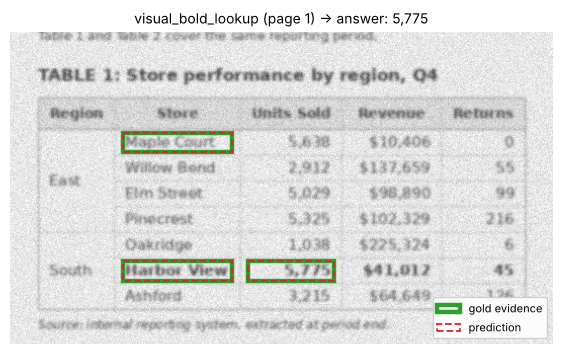

In [62]:
BOLD_MODEL = fit_bold_classifier(PAIRS_DEV)
coefs = BOLD_MODEL[-1].coef_[0]
display(pd.DataFrame([coefs.round(2)], columns=[f"{g}:{f}" for g in ("key", "numeric") for f in FEATURE_NAMES],
                     index=["weight (standardized)"]))


BOLD_RULE = "learned"     # "median" or "voting" only in the ablation study of Section 10


def which_is_bold(layout: DocumentLayout, rt: RecoveredTable, ra: int, rb: int) -> tuple:
    """(0 if row ra is the bold one else 1, confidence in [0, 1])."""
    feats = row_features(layout, rt, rows=(ra, rb))
    rule = {"median": rule_median, "voting": rule_vote}.get(BOLD_RULE)
    p = rule(feats[ra], feats[rb], tuple(rt.numeric)) if rule else rule_learned(
        feats[ra], feats[rb], tuple(rt.numeric), BOLD_MODEL)
    return (0 if p >= 0.5 else 1), abs(p - 0.5) * 2


def solve_visual_bold_lookup(it, tables, layout) -> Prediction:
    rt, c = _table_and_column(it, tables)
    if rt is None or c is None or len(it.operands) != 2:
        return Prediction(note="table, column or the two candidate rows not understood")
    (ra, ca), (rb, cb) = retrieve_row(rt, it.operands[0]), retrieve_row(rt, it.operands[1])
    if ra is None or rb is None or ra == rb:
        return Prediction(note="candidate rows not found")
    k, conf = which_is_bold(layout, rt, ra, rb)
    bold_row = (ra, rb)[k]
    cells = ([(ra, j) for j in cond_columns(rt, it.operands[0])] + [(rb, j) for j in cond_columns(rt, it.operands[1])]
             + [(bold_row, c)])
    conf = min(conf, ca, cb, value_quality(rt, bold_row, c) if rt.numeric[c] else 1.0)
    return Prediction(clean_numeric_text(rt, bold_row, c), cells_evidence(rt, cells), conf)


SOLVERS["visual_bold_lookup"] = solve_visual_bold_lookup

q_b = next(q for q in DEV if q["type"] == "visual_bold_lookup" and DEV_DOCS[q["doc_id"]].profile in ("fair", "poor"))
d_b = DEV_DOCS[q_b["doc_id"]]
lay_b = layout_of(d_b)
tabs_b = recover_tables(lay_b)
it_b = parse_question(q_b["question"], schema_of(tabs_b))
pred_b = solve_visual_bold_lookup(it_b, tabs_b, lay_b)
print(q_b["question"])
print(f"scan profile '{d_b.profile}' -> predicted {pred_b.answer!r} (confidence {pred_b.confidence:.2f}), "
      f"gold {q_b['answer']!r}")
show_question(d_b, q_b, pred_boxes=pred_b.evidence)
plt.show()

> **Going deeper.** With more compute you would train a small CNN on pairs of row crops (a
> *Siamese* network: the same encoder embeds both rows, and a head compares the embeddings), or ask
> a vision-language model directly. Our hand-made features play the role of a very small, very
> interpretable encoder. Real documents add more visual attributes worth reading the same way:
> italics, underlines, colored or shaded rows, strike-through, check boxes.

**Quick check.** Why train on *differences* of features of two rows from the same page, instead of
classifying each row as bold or regular on its own?

<details><summary>Answer</summary>

Scan quality changes the features of *every* row on a page in the same direction (blur makes all
strokes look wider and lighter). A single-row classifier would need a different threshold for every
scan profile. A difference between two rows of the same page cancels most of that shared shift,
leaving mainly the effect we care about, the bold row being heavier than its neighbor.
</details>

## 9. Routing, abstaining and writing predictions

### 9.1 The router

All the pieces now plug into one function. For each document: run OCR (here: simulated), rebuild
the tables, derive the schema. For each question: parse, validate, dispatch to the solver for the
intent's type through the `SOLVERS` table. Two engineering habits matter in batch prediction:

- **A failure is an answer too.** Every path returns a `Prediction`, with a `note` saying what went
  wrong. One strange question must never crash a run over thousands of documents, so the solver
  call is wrapped in `try/except`, and the error is recorded instead of raised.
- **Cache per document.** Table recovery runs once per document, not once per question.

In [63]:
def answer_question(question: str, layout: DocumentLayout, tables: dict, schema: dict,
                    guess: bool = False) -> tuple:
    """Parse, validate and solve one question. Returns (intent, Prediction)."""
    it = parse_question(question, schema)
    if it.missing() or it.qtype not in SOLVERS:
        pred = Prediction(note=f"invalid intent ({it.qtype}): missing {it.missing()}")
    else:
        try:
            pred = SOLVERS[it.qtype](it, tables, layout)
        except Exception as exc:                      # record, do not crash the batch
            pred = Prediction(note=f"solver error: {type(exc).__name__}: {exc}")
    if guess and not pred.answer:
        pred = best_guess(it, tables, layout) or pred
    return it, pred


def best_guess(it: StructuredIntent, tables: dict, layout) -> Prediction | None:
    """A low-confidence fallback answer for questions we could not solve properly."""
    rt = tables.get(it.table) if it.table is not None else None
    if rt is None:
        return None
    c = resolve_column(it.column, rt.headers)
    if c is None:
        return None
    for op in it.operands:                            # a lookup on the first row we can find
        r, _ = retrieve_row(rt, op)
        if r is not None:
            return Prediction(clean_numeric_text(rt, r, c), cells_evidence(rt, [(r, c)]), 0.05, "guess")
    return None


def run_pipeline(questions: list, docs: dict, level: float = 0.0, guess: bool = False, **flags) -> pd.DataFrame:
    """Answer all questions, one row per question with prediction, diagnostics and metrics."""
    rows, cache = [], {}
    for q in questions:
        if q["doc_id"] not in cache:
            lay = layout_of(docs[q["doc_id"]], level, noise_seed(q["doc_id"], level))
            tabs = recover_tables(lay, **flags)
            cache[q["doc_id"]] = (lay, tabs, schema_of(tabs))
        lay, tabs, schema = cache[q["doc_id"]]
        it, pred = answer_question(q["question"], lay, tabs, schema, guess=guess)
        m = score_one(dict(answer=pred.answer, evidence=pred.evidence), q)
        rows.append(dict(question_id=q["question_id"], doc_id=q["doc_id"], type=q["type"],
                         answer=pred.answer, gold=q["answer"], evidence=pred.evidence,
                         confidence=pred.confidence, note=pred.note, source=it.source,
                         intent_ok=intent_correct(it, q), **m))
    return pd.DataFrame(rows)


t0 = time.time()
res_dev = run_pipeline(DEV, DEV_DOCS)
print(f"DEV, clean OCR: {len(res_dev)} questions in {time.time() - t0:.1f} s, "
      f"mean score {res_dev.score.mean():.4f}")
display(res_dev.groupby("type")[["anls", "ev_f1", "score"]].mean().loc[TYPES].round(3))

DEV, clean OCR: 300 questions in 0.3 s, mean score 1.0000


,anls,ev_f1,score
type,,,
lookup,1.0,1.0,1.0
count,1.0,1.0,1.0
sum,1.0,1.0,1.0
compare,1.0,1.0,1.0
argmax,1.0,1.0,1.0
argmin,1.0,1.0,1.0
cross_page_sum,1.0,1.0,1.0
visual_bold_lookup,1.0,1.0,1.0


(The bold questions of `DEV` were used to train the bold classifier, so their score here is
a training score. The honest numbers come from `TEST` in Section 10.)

### 9.2 To answer or to abstain?

When the system is unsure (an unparsable question, an ambiguous row, a nearly tied bold
decision) it has two options: **abstain** (empty answer, no evidence) or **guess**. What is right
depends entirely on the scoring rule.

Under our metric a wrong answer scores at least as much as an empty one: ANLS of an empty string
is 0, and a wrong guess scores 0 *or more* (partial credit). So **never abstain** here: guessing
weakly dominates. That changes if wrong answers are costly. Suppose a correct answer is worth $+1$,
a wrong answer costs $-c$, and abstaining (passing the question to a human) is worth 0. If the
answer is right with probability $p$,

$$
\mathbb{E}[\text{answer}] = p - (1 - p)\,c > 0 = \mathbb{E}[\text{abstain}]
\iff p > \frac{c}{1 + c}.
$$

With $c = 0$ (our metric) the threshold is 0: always answer. With $c = 1$ (a wrong answer is as bad
as a right one is good) answer only when $p > 0.5$, and with $c = 9$, only when $p > 0.9$. This is the
same expected-utility reasoning as any decision under uncertainty.

To use it we need confidences that behave like probabilities. Let us check ours on a harder
setting (`DEV` with OCR noise level 4), where confidence varies, then compute the utility of
"answer only if confidence ≥ threshold" for a few penalties $c$.

,questions,accuracy
confidence,,
"(-0.01, 0.5]",18,0.278
"(0.5, 0.8]",71,0.887
"(0.8, 0.9]",25,1.000
"(0.9, 0.99]",15,0.867
"(0.99, 1.0]",171,0.977


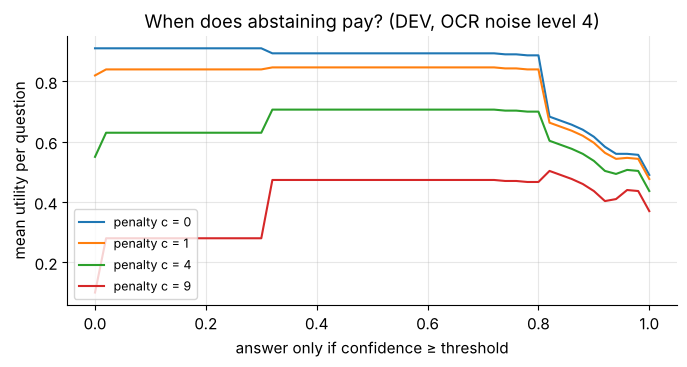

In [64]:
res_noisy = run_pipeline(DEV, DEV_DOCS, level=4)
res_noisy["correct"] = res_noisy.anls >= 0.999
bins = pd.cut(res_noisy.confidence, [-0.01, 0.5, 0.8, 0.9, 0.99, 1.0])
display(res_noisy.groupby(bins, observed=True).correct.agg(["count", "mean"]).rename(
    columns={"count": "questions", "mean": "accuracy"}).round(3))

thresholds = np.linspace(0, 1, 51)
fig, ax = plt.subplots(figsize=(7, 3.8))
for c_pen in [0, 1, 4, 9]:
    util = [np.mean(np.where(res_noisy.confidence >= th, np.where(res_noisy.correct, 1.0, -c_pen), 0.0))
            for th in thresholds]
    ax.plot(thresholds, util, label=f"penalty c = {c_pen}")
ax.set_xlabel("answer only if confidence ≥ threshold")
ax.set_ylabel("mean utility per question")
ax.set_title("When does abstaining pay? (DEV, OCR noise level 4)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

The confidence is informative: answers with confidence at most 0.5 (repaired or suspicious
numbers, weak fuzzy matches) are right only about 28% of the time, answers with confidence 1 about
98% of the time. For $c = 0$ the utility is highest at threshold 0 (answer everything), exactly as
the algebra says. As the penalty grows, skipping the shaky answers starts to pay: with $c = 9$,
answering everything is worth only about 0.1 per question, while answering only above a confidence
of about 0.8 is worth about 0.5. Our confidences are not calibrated probabilities,
though, so in a real deployment you would *fit* the threshold on held-out data (or calibrate the
scores first, for example with logistic regression on the confidence).

> **Key idea.** Abstention is a decision-theory question, not a modeling question. Ask "what does a
> wrong answer cost compared with no answer?" before tuning thresholds.

### 9.3 Writing the predictions file

Finally, the submission: one JSON line per question with the answer and the evidence boxes. Writing
the file and scoring the file (not the in-memory objects) guards against serialization bugs, such
as NumPy floats or tuples that `json` refuses or silently changes.

In [65]:
def to_records(results: pd.DataFrame) -> list:
    return [dict(question_id=r.question_id, answer=r.answer,
                 evidence=[{"page": int(e["page"]), "bbox": [float(v) for v in e["bbox"]]} for e in r.evidence])
            for r in results.itertuples()]


write_jsonl(DATA_DIR / "18_dev_predictions.jsonl", to_records(res_dev))
from_file = {r["question_id"]: r for r in read_jsonl(DATA_DIR / "18_dev_predictions.jsonl")}
print("lines written:", len(from_file), "| score recomputed from the file:",
      round(score_predictions(from_file, DEV).score.mean(), 4))
print("example line:", json.dumps(to_records(res_dev.iloc[[3]])[0])[:200])

lines written: 300 | score recomputed from the file: 1.0
example line: {"question_id": "D000-q03", "answer": "Denver", "evidence": [{"page": 0, "bbox": [0.2622, 0.2292, 0.34, 0.2464]}, {"page": 0, "bbox": [0.0689, 0.2292, 0.2444, 0.2464]}, {"page": 0, "bbox": [0.3578, 0.


## 10. Evaluation: per type, paraphrases, OCR noise, ablations, errors

Time to open the test set. Everything below runs the *same* pipeline, and only the inputs (wording,
OCR noise) or one switched-off component change, so each difference has a single cause.

### 10.1 Test results per reasoning type

In [66]:
t0 = time.time()
res_test = run_pipeline(TEST, TEST_DOCS)
write_jsonl(DATA_DIR / "18_test_predictions.jsonl", to_records(res_test))
scored = score_predictions({r["question_id"]: r for r in read_jsonl(DATA_DIR / "18_test_predictions.jsonl")}, TEST)
per_type = res_test.groupby("type").agg(n=("score", "size"), anls=("anls", "mean"), ev_precision=("ev_p", "mean"),
                                       ev_recall=("ev_r", "mean"), ev_f1=("ev_f1", "mean"), score=("score", "mean"))
per_type = per_type.loc[TYPES]
per_type.loc["ALL"] = [len(res_test)] + res_test[["anls", "ev_p", "ev_r", "ev_f1", "score"]].mean().tolist()
per_type["n"] = per_type["n"].astype(int)
display(per_type.round(4))
print(f"TEST (canonical, clean OCR) scored from the JSONL file: {scored.score.mean():.4f}   "
      f"[{time.time() - t0:.1f} s]")

,n,anls,ev_precision,ev_recall,ev_f1,score
type,,,,,,
lookup,77,1.0,1.0,1.0,1.0,1.0
count,86,1.0,1.0,1.0,1.0,1.0
sum,83,1.0,1.0,1.0,1.0,1.0
compare,83,1.0,1.0,1.0,1.0,1.0
argmax,89,1.0,1.0,1.0,1.0,1.0
argmin,81,1.0,1.0,1.0,1.0,1.0
cross_page_sum,27,1.0,1.0,1.0,1.0,1.0
visual_bold_lookup,74,1.0,1.0,1.0,1.0,1.0
ALL,600,1.0,1.0,1.0,1.0,1.0


TEST (canonical, clean OCR) scored from the JSONL file: 1.0000   [0.5 s]


On clean OCR with canonical wording, the pipeline is perfect on every type, including the bold
questions, whose classifier never saw these documents. This is the regime where
hand-built structure shines: regular layouts and known phrasings. The interesting part is what
happens when we leave that regime.

### 10.2 Robustness to wording

Same specs, same gold answers, paraphrased questions. We run the router in two modes: **abstain**
when the intent is invalid, or **guess** with the fallback of Section 9.

In [67]:
res_para = run_pipeline(TEST_PARA, TEST_DOCS)
res_para_guess = run_pipeline(TEST_PARA, TEST_DOCS, guess=True)
cmp_wording = pd.DataFrame({
    "canonical": res_test.groupby("type").score.mean(),
    "paraphrase, abstain": res_para.groupby("type").score.mean(),
    "paraphrase, guess": res_para_guess.groupby("type").score.mean(),
    "paraphrase: intent correct": res_para.groupby("type").intent_ok.mean()}).loc[TYPES]
cmp_wording.loc["ALL"] = [res_test.score.mean(), res_para.score.mean(), res_para_guess.score.mean(),
                          res_para.intent_ok.mean()]
display(cmp_wording.round(3))
print("most common failure notes on paraphrases:")
print(res_para[res_para.score < 1].note.str.slice(0, 60).value_counts().head(4).to_string())

,canonical,"paraphrase, abstain","paraphrase, guess",paraphrase: intent correct
type,,,,
lookup,1.0,1.000,1.000,1.000
count,1.0,1.000,1.000,1.000
sum,1.0,1.000,1.000,1.000
compare,1.0,1.000,1.000,1.000
argmax,1.0,1.000,1.000,1.000
argmin,1.0,1.000,1.000,1.000
cross_page_sum,1.0,1.000,1.000,1.000
visual_bold_lookup,1.0,0.608,0.804,0.608
ALL,1.0,0.952,0.976,0.952


most common failure notes on paraphrases:
note
invalid intent (lookup): missing ['1 operand']    29


Wording matters only where the fallback parser misses a cue. The big loss is in
`visual_bold_lookup`: the paraphrase *"printed in a heavier font"* contains none of the bold cue
words, so the parser sees two rows and no recognizable type, defaults to `lookup`, and the intent is
invalid (a lookup needs exactly one row). Guessing recovers part of the loss, since a lookup on one
of the two candidate rows is right about half the time. As predicted in Section 9, guessing never
lowers the score under this metric.

> **Common pitfall.** It is tempting to now add "heavier" to the cue list and re-run. That *fixes the
> test set*, and the next paraphrase will break something else. Held-out wordings are a measurement
> of how the system handles the unknown, and once you tune on them, they stop being one. (Adding cues is
> fine, but then you need a fresh held-out set to measure again.)

### 10.3 Robustness to OCR noise

Now the wording is canonical and the OCR gets worse, level by level (Section 2.8). Besides the full
pipeline we run two **ablations**, each with one robustness component switched off: re-joining of
split blocks, and fuzzy text matching (exact matches only). Switching a component off and measuring
the drop is the cleanest way to learn what each part is worth.

18 runs in 9 s


OCR noise level,0,1,2,3,4,5
full pipeline,1.0,0.989,0.981,0.978,0.947,0.916
no split re-joining,1.0,0.911,0.786,0.664,0.639,0.586
no fuzzy matching,1.0,0.936,0.819,0.786,0.675,0.585


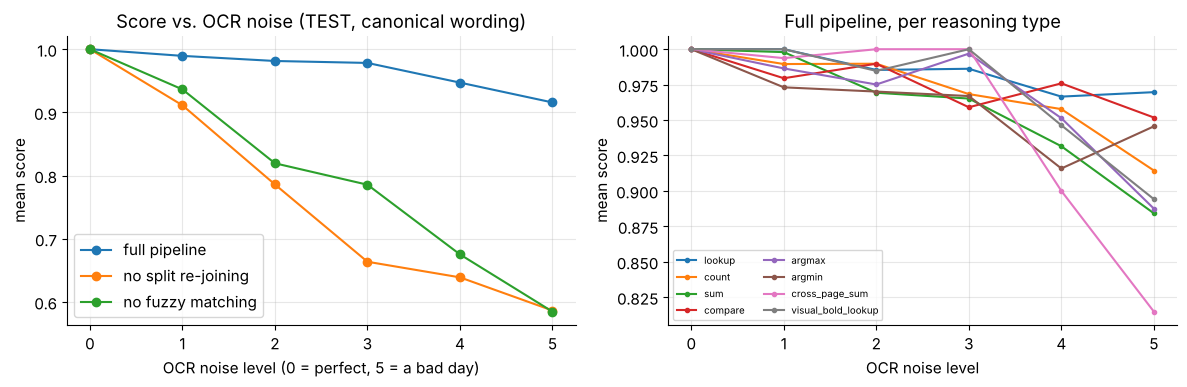

In [68]:
def set_fuzzy(on: bool) -> None:
    global FUZZY_MATCHING
    FUZZY_MATCHING = on


levels = [0, 1, 2, 3, 4, 5]
curves = {"full pipeline": {}, "no split re-joining": {}, "no fuzzy matching": {}}
t0 = time.time()
for lvl in levels:
    curves["full pipeline"][lvl] = run_pipeline(TEST, TEST_DOCS, level=lvl)
    curves["no split re-joining"][lvl] = run_pipeline(TEST, TEST_DOCS, level=lvl, merge_splits=False)
    set_fuzzy(False)
    curves["no fuzzy matching"][lvl] = run_pipeline(TEST, TEST_DOCS, level=lvl)
    set_fuzzy(True)
print(f"{3 * len(levels)} runs in {time.time() - t0:.0f} s")
noise_table = pd.DataFrame({name: {lvl: r.score.mean() for lvl, r in runs.items()} for name, runs in curves.items()})
noise_table.index.name = "OCR noise level"
display(noise_table.round(3).T)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, runs in curves.items():
    axes[0].plot(levels, [runs[lvl].score.mean() for lvl in levels], marker="o", label=name)
axes[0].set_xlabel("OCR noise level (0 = perfect, 5 = a bad day)")
axes[0].set_ylabel("mean score")
axes[0].set_title("Score vs. OCR noise (TEST, canonical wording)")
axes[0].legend()
full = curves["full pipeline"]
for ty in TYPES:
    axes[1].plot(levels, [full[lvl][full[lvl].type == ty].score.mean() for lvl in levels], marker=".", label=ty)
axes[1].set_xlabel("OCR noise level")
axes[1].set_ylabel("mean score")
axes[1].set_title("Full pipeline, per reasoning type")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

Three lessons from the curves:

1. **Re-joining split blocks matters most at moderate noise.** Without it, a single split header
   or title wrecks a whole table: at level 3 the score drops to 0.664, against 0.978 for the full
   pipeline.
2. **Fuzzy matching is worth almost as much.** With exact matching, one misread letter in a store
   name makes its row unfindable (0.786 at level 3). At level 5 both ablations end near 0.59.
3. **The full pipeline degrades gracefully, not perfectly** (0.916 at level 5). Noise hits the types
   that combine several cells or two tables hardest (cross-page sums and sums above all), because
   one damaged cell or title spoils the whole answer.

Where exactly does the remaining score go? The next cell sorts every imperfect answer of the full
pipeline at level 5 by its symptom and adds up the score that each kind of failure loses.

In [69]:
res5 = curves["full pipeline"][5]
imperfect = res5[res5.score < 0.999]
symptom = np.select(
    [imperfect.answer == "",                                         # the solver gave up (see `note`)
     imperfect.anls >= 0.999,                                        # right answer, imperfect boxes
     imperfect.gold.str.contains(r"\d") | (imperfect.anls == 0)],    # a wrong number or another row's name
    ["no answer (table, column or row not found)", "right answer, imperfect evidence",
     "wrong number or wrong row"],
    default="letter slip in a returned name")                        # right row, name misread
loss_by_symptom = (1 - imperfect.score).groupby(symptom).agg(["size", "sum"]).rename_axis("symptom")
loss_by_symptom.columns = ["questions", "score lost"]
loss_by_symptom["share of loss"] = loss_by_symptom["score lost"] / loss_by_symptom["score lost"].sum()
display(loss_by_symptom.sort_values("score lost", ascending=False).round(2))

,questions,score lost,share of loss
symptom,,,
"no answer (table, column or row not found)",32,32.00,0.63
wrong number or wrong row,18,16.00,0.32
letter slip in a returned name,22,2.21,0.04
"right answer, imperfect evidence",8,0.35,0.01


Nearly two thirds of the lost score comes from questions the pipeline does not answer at all: OCR
damaged a table title, a column header or a row name beyond what re-joining and fuzzy matching can
repair, so the solver finds no table, column or row and returns an empty answer, with the reason in
`note`. That is the honest way to fail, and it points at the next repair worth building. Most of
the rest are wrong numbers or wrong rows, nearly all caused by a **dropped character** inside a
number, usually a digit. Look-alike substitutions such as `O` for `0` are undone by the number
parser, but a dropped digit (like the `194` read as `94` in Section 10.5) usually leaves a perfectly
valid-looking number, and no rule can put the digit back. It spoils a lookup or a sum, moves a row
across a threshold in a count, or crowns the wrong row in an argmax or argmin. Letter slips in
returned names (`Denvcr` for `Denver`) are frequent but cheap: each costs only a little ANLS.

### 10.4 More ablations

Two more components to switch off one at a time: the logical-row handling of merged cells, and the
bold decision rule (learned classifier vs. the two hand-made rules). We report the overall score and
the score of the type each component serves, at OCR noise levels 0 and 3.

In [70]:
def set_bold_rule(name: str) -> None:
    global BOLD_RULE
    BOLD_RULE = name


rows = []
for name, flags, bold_rule in [("full pipeline", {}, "learned"), ("no logical rows", {"logical_rows": False}, "learned"),
                               ("bold: per-cell voting", {}, "voting"), ("bold: row median", {}, "median")]:
    set_bold_rule(bold_rule)
    for lvl in (0, 3):
        r = curves["full pipeline"][lvl] if name == "full pipeline" else run_pipeline(TEST, TEST_DOCS, level=lvl, **flags)
        rows.append(dict(config=name, level=lvl, overall=r.score.mean(),
                         count=r[r.type == "count"].score.mean(), lookup=r[r.type == "lookup"].score.mean(),
                         bold=r[r.type == "visual_bold_lookup"].score.mean()))
set_bold_rule("learned")
abl = pd.DataFrame(rows).pivot(index="config", columns="level").round(3)
display(abl.loc[["full pipeline", "no logical rows", "bold: per-cell voting", "bold: row median"]])

overall         count        lookup          bold       
level                       0      3      0      3      0      3      0      3
config                                                                        
full pipeline           1.000  0.978  1.000  0.968  1.000  0.986  1.000  1.000
no logical rows         0.937  0.916  0.773  0.741  0.974  0.960  0.880  0.880
bold: per-cell voting   0.993  0.966  1.000  0.968  1.000  0.986  0.939  0.903
bold: row median        0.988  0.966  1.000  0.968  1.000  0.986  0.903  0.903

- **No logical rows** hurts every question whose conditions use a merged group cell: counts by
  group, and lookups or sums whose row descriptor needs the group (a repeated item name). It is
  invisible on rows that are not in a merged group, which is why such bugs survive casual testing.
- The **bold rules** confirm Section 8 on fresh documents: voting and the row median lose 6 to 10%
  of the bold questions, the learned classifier none at these noise levels.

### 10.5 Error analysis

Aggregate scores say *how much* fails, and an error analysis says *why*, and therefore what to fix
next. We take the hardest setting (paraphrased questions, OCR noise level 3, guessing on) and sort
every imperfect answer into one cause, checked in pipeline order.

In [71]:
res_hard = run_pipeline(TEST_PARA, TEST_DOCS, level=3, guess=True)


def error_cause(r) -> str:
    if r.score >= 0.999:
        return "correct"
    if r.note.startswith("invalid intent") or r.note == "guess":
        return "question not understood"
    if not r.intent_ok:
        return "misunderstood question"
    if "not found" in r.note or "unreadable" in r.note or "not understood" in r.note:
        return "table / row / value not found"
    if r.anls >= 0.999:
        return "answer right, evidence imperfect"
    return "wrong or misread value"


res_hard["cause"] = [error_cause(r) for r in res_hard.itertuples()]
causes = res_hard.cause.value_counts()
display(pd.DataFrame({"questions": causes, "share": (causes / len(res_hard)).round(3)}))
print(f"mean score in this setting: {res_hard.score.mean():.3f}")
display(res_hard[res_hard.cause == "wrong or misread value"].head(6)[["type", "answer", "gold", "confidence", "anls"]])

,questions,share
cause,,
correct,546,0.910
question not understood,29,0.048
wrong or misread value,23,0.038
misunderstood question,2,0.003


mean score in this setting: 0.954


,type,answer,gold,confidence,anls
5,compare,Harbor View,Granite Falls,1.0,0.000
15,argmin,Kingslcy,Kingsley,1.0,0.875
210,lookup,.9%,6.9%,0.3,0.750
211,sum,62,"1,254",0.3,0.000
221,compare,Mobile App,Help Center,1.0,0.000
224,argmin,Mobile App,Route Planner,1.0,0.000


Two families dominate: questions the parser did not understand (wording) and values that OCR
misread (noise). Most misread values are numbers with a dropped digit, which spoil a lookup or a
sum and flip comparisons, counts and argmins, and the others are letter slips in returned names
(`Kingslcy`), which cost only a little ANLS. Both families suggest the same kind of next step:
**more learning, in the right places**.
A small text classifier trained on many paraphrases would replace the keyword cues, and a better OCR
engine (or a second OCR pass on low-confidence numeric cells) would attack misread digits. Some
misread values come with a low confidence (0.3 in the table above) and could be routed to a human
or a second OCR pass instead of being answered blindly, and others look perfectly normal.

Let us look at one failure on the page, since seeing it is often faster than reading about it.

Between Store "Granite Falls" and Store "Harbor View" in Table 2, whose Returns is larger?
predicted 'Harbor View' (confidence 1.00), gold 'Granite Falls'
  OCR text in a predicted evidence box: ['Granite', 'Falls']
  OCR text in a predicted evidence box: ['94']
  OCR text in a predicted evidence box: ['Harbor View']
  OCR text in a predicted evidence box: ['160']


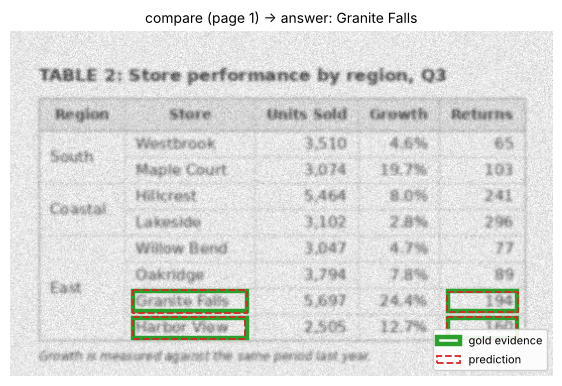

In [72]:
fail = res_hard[(res_hard.cause == "wrong or misread value") & (res_hard.type != "count")].iloc[0]
q_fail = next(q for q in TEST_PARA if q["question_id"] == fail.question_id)
lay_fail = layout_of(TEST_DOCS[q_fail["doc_id"]], 3, noise_seed(q_fail["doc_id"], 3))
print(q_fail["question"])
print(f"predicted {fail.answer!r} (confidence {fail.confidence:.2f}), gold {fail.gold!r}")
ax = show_question(TEST_DOCS[q_fail["doc_id"]], q_fail, pred_boxes=fail.evidence)
for e in fail.evidence:                                  # print what the OCR read inside the predicted boxes
    texts = [b["text"] for b in lay_fail.blocks if b["page"] == e["page"] and iou(b["bbox"], e["bbox"]) > 0.3]
    print("  OCR text in a predicted evidence box:", texts)
plt.show()

The predicted boxes are exactly the right cells (they sit on the green gold boxes): retrieval,
structure and evidence all worked. The failure is pure *reading*: OCR returned `94` for the printed
`194`, so the comparison flipped. The confidence stayed at 1.0 because `94` is a perfectly
well-formed number, so no format check can catch it. Only a second look at the pixels (another OCR
engine, or a digit recognizer run on that crop) could. Notice also that the evidence would let a
human reviewer catch the mistake in seconds, which is the whole point of answering with evidence.

## 11. Rules vs. learned document models

Our pipeline is mostly hand-written rules plus one small learned component. Research and industry
systems for document question answering are mostly *learned*. Knowing the main families, and what
each one gives up, helps you choose (and helps in olympiad questions that ask you to compare
designs).

### 11.1 The main families

**1. OCR + layout-aware transformers (the LayoutLM family).** Start from OCR tokens, like we did.
A BERT-style encoder receives, for every token, its text embedding **plus an embedding of its
bounding box** (the 2D position, quantized $x_1, y_1, x_2, y_2$). LayoutLM showed that this simple
addition lets a pre-trained model "see" that `1,250` sits under `Revenue`. Later versions add image
features (v2: a CNN feature map, and v3: image patches, pre-trained jointly with text masking). For
question answering they are usually fine-tuned **extractively**: predict the start and end token of
the answer among the OCR tokens. A nice side effect: the predicted span *is* a set of OCR boxes, so
extractive models come with natural evidence. The limits: an answer that is not printed anywhere
(a sum, a count) cannot be extracted, inputs are capped at a few hundred tokens, and everything
depends on the OCR.

**2. OCR-free encoder–decoders (Donut, Pix2Struct).** Feed the page *image* to a vision encoder and
let a text decoder *generate* the answer. Donut pre-trains the model to read (predict the page's
text). Pix2Struct pre-trains on turning masked web-page screenshots into simplified HTML, and
accepts images at variable resolution. No OCR errors to inherit, and visual cues such as bold come
for free. The costs: lots of training data and compute, trouble with tiny text at limited
resolution, arithmetic done "in the head" of a decoder (and therefore error-prone), and no boxes.

**3. Vision–language models with grounding.** Large multimodal language models answer free-form
questions about a page image and can be prompted (or fine-tuned) to also output **boxes as text**,
e.g. coordinates in a fixed grid. They handle any wording and can explain their reasoning. They also
hallucinate plausible numbers, produce boxes that are often too loose for IoU ≥ 0.5 on small table
cells, cost far more per question than our pipeline, and may not give the same answer twice.

**4. Learned components inside a pipeline.** Table structure recognition models (for example
DETR-style detectors such as Table Transformer) replace the geometric rules of Section 6, a
semantic parser (small seq2seq model or a prompted LLM) replaces the regex templates of Section 5, and
the arithmetic and the evidence stay deterministic. This **hybrid** design ("the model writes the
query, code executes it") is how many production systems and tool-using LLM agents work.

| | Rules (this notebook) | LayoutLM-style, extractive | Donut / Pix2Struct | VLM with grounding | Hybrid |
|---|---|---|---|---|---|
| Needs OCR | yes | yes | no | no | usually |
| New wordings | poor | good | good | very good | good |
| Exact arithmetic | yes | no (extract only) | unreliable | unreliable | yes |
| Evidence boxes | exact, by construction | token boxes of the span | none | approximate | exact |
| Reads visual style (bold) | with extra pixel code | partly (v2/v3) | yes | yes | with extra code |
| Training data / compute | none / tiny | moderate | large | huge (pre-trained) | moderate |
| Debuggability | excellent | fair | poor | poor | good |

### 11.2 Can we add evidence to a black-box answer?

Suppose a model that only returns answer strings is perfect: every answer is right. A popular
trick to get evidence anyway is **answer-then-locate**: search the OCR blocks for the answer text
and return the best-matching boxes. Let us measure how much evidence that would recover on `TEST`,
using the *gold* answers as the black box's output (the best case).

In [73]:
def locate_answer(answer: str, layout: DocumentLayout, min_sim: float = 0.9) -> list:
    """Evidence by search: every OCR block whose text matches the answer string."""
    return [{"page": b["page"], "bbox": b["bbox"]} for b in merge_split_blocks(layout.blocks)
            if nls(b["text"], answer) >= min_sim]


rows = []
lay_cache = {}
for q in TEST:
    lay = lay_cache.setdefault(q["doc_id"], layout_of(TEST_DOCS[q["doc_id"]]))
    p, r, f1 = evidence_prf(locate_answer(q["answer"], lay), q["evidence"])
    rows.append(dict(type=q["type"], ev_precision=p, ev_recall=r, ev_f1=f1))
loc = pd.DataFrame(rows).groupby("type").mean().loc[TYPES]
loc["final score (perfect answers)"] = 0.85 + 0.15 * loc.ev_f1
display(loc.round(3))

,ev_precision,ev_recall,ev_f1,final score (perfect answers)
type,,,,
lookup,1.000,0.474,0.641,0.946
count,0.000,0.000,0.000,0.850
sum,0.018,0.004,0.007,0.851
compare,0.782,0.236,0.354,0.903
argmax,0.846,0.483,0.603,0.940
argmin,0.830,0.475,0.593,0.939
cross_page_sum,0.037,0.009,0.015,0.852
visual_bold_lookup,0.973,0.309,0.465,0.920


Answer-then-locate recovers only a fraction of the evidence even with perfect answers:

- **Computed answers** (sums, counts, cross-page sums) are not printed anywhere, so there is almost
  nothing to find: evidence F1 is close to 0.
- **Lookups** find the answer cell but not the *condition* cells that justify it (recall about one
  half).
- **Name answers** (argmax, argmin, compare) and bold lookups find the printed name or value, but
  not the numbers or the other row that make it the answer (recall between about 0.24 and 0.48).

Evidence is not an afterthought you can bolt on: it has to come from the *process* that produced the
answer. That is the real argument for "retrieve first, reason second", whatever does the reasoning.

### 11.3 Choosing in practice

- **Few layouts, known question types, exact numbers required, audit trail needed** (finance,
  compliance, invoices from a handful of vendors): rules or a hybrid with deterministic execution.
- **Many layouts, free-form questions, approximate answers acceptable** (search over a document
  archive, assistants): learned models, ideally extractive or grounded, with answer verification.
- **Always**: build the evaluation first (Section 4), keep a held-out set of *new* layouts and
  wordings, and measure robustness to the noise your OCR or scanner actually produces.

A word on the **sim-to-real gap** promised in Section 2. Every number in this notebook comes from
documents that our own generator produced, with one font, four table families, ruled grids and
well-behaved OCR noise. Real archives add skewed and curved scans, stamps and handwriting, tables
without ruling lines, multi-line cells, footnote markers inside numbers, and layouts nobody
anticipated. Treat the perfect clean-data scores as an upper bound and the noise curves as a
*relative* comparison of designs. Before trusting a pipeline on real documents, annotate even a
few dozen real pages and evaluate on them: a small real test set is worth more than a large
synthetic one.

> **Olympiad tip.** Exam questions about system design often hide a metric detail. Before choosing
> an approach, ask what the metric rewards: partial string credit (ANLS) favors near-misses, an IoU
> threshold favors tight boxes, one-to-one matching punishes duplicates, and the weight split (85/15
> here) tells you where the points are.

## 12. Quiz

Try each question before opening the answer. The explanations cover every option.

**Q1.** Gold answer `"Westbrook"`, prediction `"Westbrock"`. What is the ANLS score ($\tau = 0.5$)?

(A) 0  (B) 0.5  (C) 0.889  (D) 1.0

<details><summary>Answer</summary>

**(C).** One substitution in a 9-character string: $\operatorname{NL} = 1/9 \approx 0.111 < 0.5$, so
the score is $1 - 1/9 \approx 0.889$. (A) would require $\operatorname{NL} \ge 0.5$. (B) confuses the
threshold with the score. (D) would require an exact (case-insensitive) match.
</details>

**Q2.** A predicted box has exactly the size of the gold cell box but is shifted *down* by 40% of
the box height. Does it count as correct evidence?

(A) Yes, IoU = 0.6  (B) Yes, IoU = 0.5  (C) No, IoU ≈ 0.43  (D) No, IoU = 0

<details><summary>Answer</summary>

**(C).** For a shift of $d$ times the size, $\operatorname{IoU} = (1 - d)/(1 + d) = 0.6/1.4 \approx
0.43 < 0.5$. (A) is the overlap as a fraction of *one* box (intersection / area), not IoU. (B) would
hold for a shift of exactly one third. (D) would need no overlap at all, i.e. a shift of 100% or
more.
</details>

**Q3.** The answer is right. The gold evidence has 3 boxes, and you predicted 5 boxes, 3 of which match
gold boxes. What is the question's final score?

(A) 0.85  (B) 0.94  (C) 0.9625  (D) 1.0

<details><summary>Answer</summary>

**(C).** $P = 3/5$, $R = 3/3$, $F_1 = 2 \cdot 0.6 \cdot 1 / 1.6 = 0.75$, so the score is
$0.85 + 0.15 \cdot 0.75 = 0.9625$. (A) ignores the evidence term entirely. (B) plugs in the
precision $0.6$ instead of $F_1$. (D) would need perfect evidence: the two extra boxes cost precision.
</details>

**Q4.** A merged Region cell "North" spans rows 3, 4 and 5 of a table. The table is rebuilt with
*physical rows only* (no logical rows). What does the count solver answer to "How many rows have
Region "North"?"

(A) 0  (B) 1  (C) 3  (D) it crashes

<details><summary>Answer</summary>

**(B).** The tall block's top edge belongs to row 3 only, so only row 3 has a Region cell equal to
"North", and rows 4 and 5 have an empty Region cell. (A) would happen only if the block were lost
entirely. (C) is the correct answer, obtained with logical rows (mid-row $y$ inside the tall block).
(D): the solver treats an empty cell as non-matching text, it does not crash, which is exactly why
this bug is silent.
</details>

**Q5.** When can *greedy* one-to-one box matching find fewer matches than the Hungarian algorithm?

(A) Never, greedy is always optimal
(B) Only when some box has IoU ≥ 0.5 with two or more boxes of the other set, which requires
    overlapping boxes (or exact ties at IoU = 0.5)
(C) Whenever there are more predicted boxes than gold boxes
(D) Whenever boxes lie on different pages

<details><summary>Answer</summary>

**(B).** Greedy can only go wrong when valid pairs *compete*. If gold boxes are pairwise disjoint,
a prediction can have IoU ≥ 0.5 with at most one of them (each would need to cover half of the
prediction, and only exact ties at IoU = 0.5 escape this), so no competition is possible. (A) is false:
Section 4.4 shows a counterexample.
(C): extra predictions simply stay unmatched, and that alone does not fool greedy. (D): pairs on
different pages are never valid, so pages only *reduce* competition.
</details>

**Q6.** Under $\text{score} = 0.85\,\text{ANLS} + 0.15\,F_1$, your system is only 30% sure of an
answer. What should it do?

(A) Abstain: 30% is below 50%
(B) Answer: a wrong answer scores at least as much as an empty one
(C) Abstain, because wrong evidence is penalized
(D) Answer only if the confidence is calibrated

<details><summary>Answer</summary>

**(B).** An empty answer scores 0 on both terms, and a wrong answer also scores 0 or a bit more (partial
ANLS credit, partially right boxes). There is no penalty, so answering weakly dominates. (A) applies
the threshold $c/(1 + c)$ for $c = 1$, but here $c = 0$. (C): wrong evidence earns 0, the same as no
evidence, it is not *negative*. (D): calibration matters for choosing a threshold when $c > 0$, and
with $c = 0$ the threshold is 0 whatever the calibration.
</details>

**Q7.** What does Otsu's method choose?

(A) The threshold that maximizes the between-class variance of the two pixel classes
(B) The threshold that maximizes the within-class variance
(C) The mean gray level of the image
(D) The threshold that makes exactly half the pixels ink

<details><summary>Answer</summary>

**(A)**, which is the same as *minimizing* the within-class variance, because the two add up to the
fixed total variance. (B) is the opposite of what we want: classes as loose as possible. (C) is a
common quick heuristic, but it ignores the histogram's shape and fails when text covers a small
part of the crop. (D) is a median split, which makes no sense when ink covers 10% of the crop.
</details>

**Q8.** The bold classifier is a logistic regression **without intercept**, trained on feature
*differences* $\mathbf{x}_A - \mathbf{x}_B$ of both orders of every pair. Which property follows?

(A) It predicts bold for the row with the larger stroke score, always
(B) $P(\text{A bold} \mid \text{A}, \text{B}) = 1 - P(\text{B bold} \mid \text{B}, \text{A})$
(C) Its predictions are calibrated probabilities
(D) It can only use one feature

<details><summary>Answer</summary>

**(B).** Swapping A and B negates the input, $\sigma(\mathbf{w}^\top(-\mathbf{x})) = 1 -
\sigma(\mathbf{w}^\top\mathbf{x})$, so the decision never depends on the order of the two rows. With an
intercept $b$, $\sigma(b - \mathbf{w}^\top\mathbf{x}) \ne 1 - \sigma(b + \mathbf{w}^\top\mathbf{x})$ in
general. (A) is false: it weighs three features over key and numeric cells. (C): nothing
guarantees calibration. (D): it uses six features.
</details>

**Q9.** Our number parser reads `1,250` as 1250, yet it reads `4.674` as 4674 and `20,2` as 20.2.
Which assumption justifies all three readings?

(A) OCR never confuses `,` and `.`
(B) In these reports decimals have at most two digits and thousands groups exactly three
(C) All numbers are integers
(D) European number formatting

<details><summary>Answer</summary>

**(B).** Under that assumption a separator followed by exactly three digits must be a thousands
separator, and one followed by one or two digits must be a decimal point, whatever symbol OCR
printed. (A) is the opposite: the rule exists *because* OCR confuses them. (C) would make `20.2`
impossible. (D) would also read `4.674` as 4674 and `20,2` as 20.2, but it would read `1,250` as
1.25, which our parser does not do.
</details>

**Q10.** Why does this notebook keep paraphrased templates out of development and use them only
for testing?

(A) Paraphrases are harder to generate
(B) To measure how the parser handles wordings it was not designed for, since tuning on them would make
    that measurement optimistic
(C) Because regex cannot parse paraphrases
(D) To make the test set larger

<details><summary>Answer</summary>

**(B).** A held-out set is a measurement instrument. Once you adjust cue words to the paraphrases,
the paraphrase score stops estimating performance on *new* wordings. (A) is irrelevant to the
protocol. (C) is false: a regex can be written for any fixed paraphrase (Exercise 4), and the point is
that unseen wordings have no regex yet. (D): the paraphrase set has the same specs as the canonical
test set, so it adds no new answers.
</details>

**Q11.** An OCR-free model such as Donut answers a sum question with the correct string `$270,007`.
What is still missing for this task?

(A) Nothing
(B) Evidence boxes, and answer-then-locate cannot recover them because the sum is not printed on
    the page
(C) The currency sign
(D) A confidence score, which is required by the metric

<details><summary>Answer</summary>

**(B).** The model gives no boxes, and searching the page for `$270,007` finds nothing: computed
answers do not appear in the document. That costs up to 15% of the score and, more importantly,
leaves the user unable to verify the answer. (A) ignores the evidence term. (C): the string already
has it. (D): the metric does not use confidences at all.
</details>

## 13. Summary and going further

### 13.1 What you built

```text
 synthetic report pages ─► simulated OCR (+ noise) ─► re-join splits ─► titles ─► header ─►
 physical rows ─► logical rows ─► columns ─► grids
 questions ─► regex templates / keyword + schema-linking fallback ─► validated StructuredIntent
 router ─► solvers (retrieve rows → cells = evidence → compute → format) ─► JSONL
               └─ bold questions: Otsu + distance transform features ─► pairwise logistic model
```

### 13.2 Key formulas and takeaways

| Topic | Formula / rule | Remember |
|---|---|---|
| Edit distance | $D[i][j] = \min(D[i-1][j]+1,\, D[i][j-1]+1,\, D[i-1][j-1]+[a_i \ne b_j])$ | $O(\lvert a\rvert\,\lvert b\rvert)$ dynamic programming |
| ANLS | $s = 1 - \operatorname{NL}$ if $\operatorname{NL} < \tau = 0.5$, else 0, max over gold answers | lenient to typos, *also* to wrong numbers that look similar |
| IoU | $\lvert A \cap B\rvert / \lvert A \cup B\rvert$ | a box survives a shift of $1/3$ of its size at threshold 0.5 |
| Matching | one-to-one, same page, IoU ≥ 0.5, greedy or Hungarian | greedy is optimal when gold boxes are disjoint (barring exact ties at 0.5) |
| Evidence F1 | $P = \text{TP}/\lvert\hat E\rvert$, $R = \text{TP}/\lvert E\rvert$, $F_1 = 2PR/(P+R)$ | extra boxes cost precision, missing boxes cost recall |
| Final score | $0.85\,\text{ANLS} + 0.15\,F_1$ | evidence decides between equally right answers |
| Rows | same top $y$ (tolerance ≈ half a row) → physical rows, and mid-row $y$ inside a tall block → logical rows | merged cells are silent bugs |
| Columns | nearest header center $x$ | headers are centered, and cell text alignment varies |
| Otsu | maximize $\sigma_B^2(t) = \omega_0\omega_1(\mu_0 - \mu_1)^2$ | = minimize within-class variance |
| Stroke score | $2 \cdot$ mean distance transform over ink $\approx w/2 + 1$ (grows with the stroke width $w$, is not $w$) | blur hides stroke shape more than darkness |
| Pairwise model | $P(\text{A bold}) = \sigma(\mathbf{w}^\top(\mathbf{x}_A - \mathbf{x}_B))$, no intercept | order-invariant, cancels page-level scan effects |
| Abstaining | answer iff $p > c/(1 + c)$ | with no penalty ($c = 0$), always answer |

**Takeaways**

1. Define the metric first. It decides formatting, box tightness and whether to abstain.
2. Retrieve first, reason second: the cells a solver touches *are* its evidence.
3. Layout geometry (top edges, mid-row lines, header centers) recovers tables without any model.
4. Robustness comes from small, specific repairs (re-joining splits, fuzzy matching, look-alike
   correction, format-aware parsing), each validated by an ablation.
5. Learn where rules run out (bold under blur), and compare *within a page* to cancel nuisance
   factors.
6. Measure on held-out wordings and realistic noise, then read the errors, not just the averages.

### 13.3 Going further

- Mathew, Karatzas, Jawahar, [DocVQA: A Dataset for VQA on Document Images](https://arxiv.org/abs/2007.00398) (WACV 2021): the
  benchmark that popularized ANLS for documents.
- Biten et al., [Scene Text Visual Question Answering](https://arxiv.org/abs/1905.13648) (ICCV 2019): where ANLS and the
  $\tau = 0.5$ threshold were introduced.
- Xu et al., [LayoutLM](https://arxiv.org/abs/1912.13318) and Huang et al., [LayoutLMv3](https://arxiv.org/abs/2204.08387):
  text + 2D position (+ image) pre-training.
- Kim et al., [Donut: OCR-free Document Understanding Transformer](https://arxiv.org/abs/2111.15664) and Lee et al.,
  [Pix2Struct](https://arxiv.org/abs/2210.03347): reading documents straight from pixels.
- Smock et al., [PubTables-1M and Table Transformer](https://arxiv.org/abs/2110.00061): learned table structure
  recognition.
- Zhu et al., [TAT-QA](https://arxiv.org/abs/2105.07624): question answering with numerical reasoning over tables and text.
- Otsu, [A Threshold Selection Method from Gray-Level Histograms](https://doi.org/10.1109/TSMC.1979.4310076) (1979).
- OpenCV tutorials: [image thresholding](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html) and the
  [distance transform](https://docs.opencv.org/4.x/d7/d1b/group__imgproc__misc.html).
- SciPy: [`linear_sum_assignment`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linear_sum_assignment.html)
  (the Hungarian-style assignment solver used in Section 4).
- Python documentation: [regular expressions (`re`)](https://docs.python.org/3/library/re.html), and Pillow's
  [text anchors](https://pillow.readthedocs.io/en/stable/handbook/text-anchors.html) used by the page renderer.

**Ideas to extend this notebook:** add the `difference` type end to end (template, cue, solver,
questions). Make the generator emit tables that continue across pages or cells spanning
*columns*, and extend Section 6 to handle them. Replace the keyword cues with a small classifier
trained on many generated paraphrases. Or train a tiny CNN on pairs of row crops and compare it with
the 6-feature logistic model.